## Download Data

In [ ]:
# Khoa_LHR_image.zip
!gdown --id 1qTkTp1OfumLB2dHtX6e_c2lhNNcnOZOx



In [ ]:
!pip install torcheval


In [ ]:
!unzip /content/Khoa_LHR_image.zip

In [ ]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch import optim
from PIL import Image
from torchvision import transforms
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from torcheval.metrics.functional import peak_signal_noise_ratio
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(66)


## Problem3: Inpainting Image with UNET

### Unet for inpainting image task

#### No skip connection

In [ ]:
class FirstFeatureNoSkip(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(FirstFeatureNoSkip, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, 1, 0, bias=False),
            nn.LeakyReLU()
        )

    def forward(self, x):
        return self.conv(x)


class ConvBlockNoSkip(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlockNoSkip, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class EncoderNoSkip(nn.Module):
    def __init__(self, in_channels, out_channels) -> None:
        super(EncoderNoSkip, self).__init__()
        self.encoder = nn.Sequential(
            nn.MaxPool2d(2),
            ConvBlockNoSkip(in_channels, out_channels)
        )

    def forward(self, x):
        x = self.encoder(x)
        return x


class DecoderNoSkip(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DecoderNoSkip, self).__init__()
        self.conv = nn.Sequential(
            nn.UpsamplingBilinear2d(scale_factor=2),
            nn.Conv2d(in_channels, out_channels*2, 1, 1, 0, bias=False),
            nn.BatchNorm2d(out_channels*2),
            nn.LeakyReLU(),
        )
        self.conv_block = ConvBlockNoSkip(out_channels*2, out_channels)

    def forward(self, x):
        x = self.conv(x)
        x = self.conv_block(x)
        return x


class FinalOutputNoSkip(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(FinalOutputNoSkip, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, 1, 0, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.conv(x)


class II_Unet_NoSkip(nn.Module):
    def __init__(
            self, n_channels=3, n_classes=3
    ):
        super(II_Unet_NoSkip, self).__init__()

        self.n_channels = n_channels
        self.n_classes = n_classes
        self.in_conv1 = FirstFeatureNoSkip(n_channels, 64)
        self.in_conv2 = ConvBlockNoSkip(64, 64)

        self.enc_1 = EncoderNoSkip(64, 128)
        self.enc_2 = EncoderNoSkip(128, 256)
        self.enc_3 = EncoderNoSkip(256, 512)
        self.enc_4 = EncoderNoSkip(512, 1024)

        self.dec_1 = DecoderNoSkip(1024, 512)
        self.dec_2 = DecoderNoSkip(512, 256)
        self.dec_3 = DecoderNoSkip(256, 128)
        self.dec_4 = DecoderNoSkip(128, 64)

        self.out_conv = FinalOutputNoSkip(64, n_classes)


    def forward(self, x):
        x = self.in_conv1(x)
        x = self.in_conv2(x)

        x = self.enc_1(x)
        x = self.enc_2(x)
        x = self.enc_3(x)
        x = self.enc_4(x)

        x = self.dec_1(x)
        x = self.dec_2(x)
        x = self.dec_3(x)
        x = self.dec_4(x)

        x = self.out_conv(x)
        return x

In [ ]:
unet_model = II_Unet_NoSkip().to(device)
img = torch.ones(2, 3, 256, 256).to(device)
unet_model(img).shape

torch.Size([2, 3, 256, 256])

#### Skip connection

In [ ]:
class FirstFeature(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(FirstFeature, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, 1, 0, bias=False),
            nn.LeakyReLU()
        )

    def forward(self, x):
        return self.conv(x)


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class Encoder(nn.Module):
    def __init__(self, in_channels, out_channels) -> None:
        super().__init__()
        self.encoder = nn.Sequential(
            nn.MaxPool2d(2),
            ConvBlock(in_channels, out_channels)
        )

    def forward(self, x):
        x = self.encoder(x)
        return x


class Decoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(Decoder, self).__init__()
        self.conv = nn.Sequential(
            nn.UpsamplingBilinear2d(scale_factor=2),
            nn.Conv2d(in_channels, out_channels, 1, 1, 0, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(),
        )
        self.conv_block = ConvBlock(in_channels, out_channels)

    def forward(self, x, skip):
        x = self.conv(x)
        x = torch.concat([x, skip], dim=1)
        x = self.conv_block(x)
        return x


class FinalOutput(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(FinalOutput, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, 1, 0, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.conv(x)


class II_Unet(nn.Module):
    def __init__(
            self, n_channels=3, n_classes=3, features=[64, 128, 256, 512],
    ):
        super(II_Unet, self).__init__()

        self.n_channels = n_channels
        self.n_classes = n_classes

        self.in_conv1 = FirstFeature(n_channels, 64)
        self.in_conv2 = ConvBlock(64, 64)

        self.enc_1 = Encoder(64, 128)
        self.enc_2 = Encoder(128, 256)
        self.enc_3 = Encoder(256, 512)
        self.enc_4 = Encoder(512, 1024)

        self.dec_1 = Decoder(1024, 512)
        self.dec_2 = Decoder(512, 256)
        self.dec_3 = Decoder(256, 128)
        self.dec_4 = Decoder(128, 64)

        self.out_conv = FinalOutput(64, n_classes)


    def forward(self, x):
        x = self.in_conv1(x)
        x1 = self.in_conv2(x)

        x2 = self.enc_1(x1)
        x3 = self.enc_2(x2)
        x4 = self.enc_3(x3)
        x5 = self.enc_4(x4)

        x = self.dec_1(x5, x4)
        x = self.dec_2(x, x3)
        x = self.dec_3(x, x2)
        x = self.dec_4(x, x1)

        x = self.out_conv(x)
        return x

In [ ]:
unet_model = II_Unet().to(device)
img = torch.ones(2, 3, 256, 256).to(device)
unet_model(img).shape

torch.Size([2, 3, 256, 256])

### Prepare Inpainting Dataset

In [ ]:
LHR_TRAIN_DATA_PATH = '/content/Khoa_LHR_image/train'
LHR_VAL_DATA_PATH = '/content/Khoa_LHR_image/val'
BATCH_SIZE = 8
IMG_HEIGHT = 256
IMG_WIDTH = 256

In [ ]:
class ImageDataset(Dataset):
    def __init__(self, img_dir, is_train=True):
        self.is_train = is_train
        self.img_dir = img_dir
        self.images = os.listdir(img_dir)

    def __len__(self):
        return len(self.images)

    def normalize(self, input_image, target_image):
        input_image  = input_image*2 - 1
        target_image = target_image*2 - 1

        return input_image, target_image

    def random_jitter(self, input_image, target_image):
        if torch.rand([]) < 0.5:
            input_image = transforms.functional.hflip(input_image)
            target_image = transforms.functional.hflip(target_image)

        return input_image, target_image

    def create_mask(self, image):
        masked_image = image.copy()
        ## Prepare masking matrix
        mask = np.full((IMG_WIDTH,IMG_HEIGHT,3), 0, np.uint8)
        for _ in range(np.random.randint(1, 5)):
            # Get random x locations to start line
            x1, x2 = np.random.randint(1, IMG_WIDTH), np.random.randint(1, IMG_WIDTH)
            # Get random y locations to start line
            y1, y2 = np.random.randint(1, IMG_HEIGHT), np.random.randint(1, IMG_HEIGHT)
            # Get random thickness of the line drawn
            thickness = np.random.randint(1, 15)
            # Draw line on the black mask
            cv2.line(mask,(x1,y1),(x2,y2),(1,1,1),thickness)

        masked_image = np.where(mask, 255*np.ones_like(mask), masked_image)
        return masked_image

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.images[idx])
        image = np.array(Image.open(img_path).convert("RGB"))

        input_image = self.create_mask(image)
        input_image = transforms.functional.to_tensor(input_image)
        target_image = transforms.functional.to_tensor(image)

        input_image = input_image.type(torch.float32)
        target_image = target_image.type(torch.float32)

        input_image, target_image = self.normalize(input_image, target_image)

        if self.is_train:
            input_image, target_image = self.random_jitter(input_image, target_image)

        return input_image, target_image



In [ ]:
train_dataset = ImageDataset(LHR_TRAIN_DATA_PATH, is_train=True)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

test_dataset = ImageDataset(LHR_VAL_DATA_PATH, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Text(0.5, 1.0, 'Target')

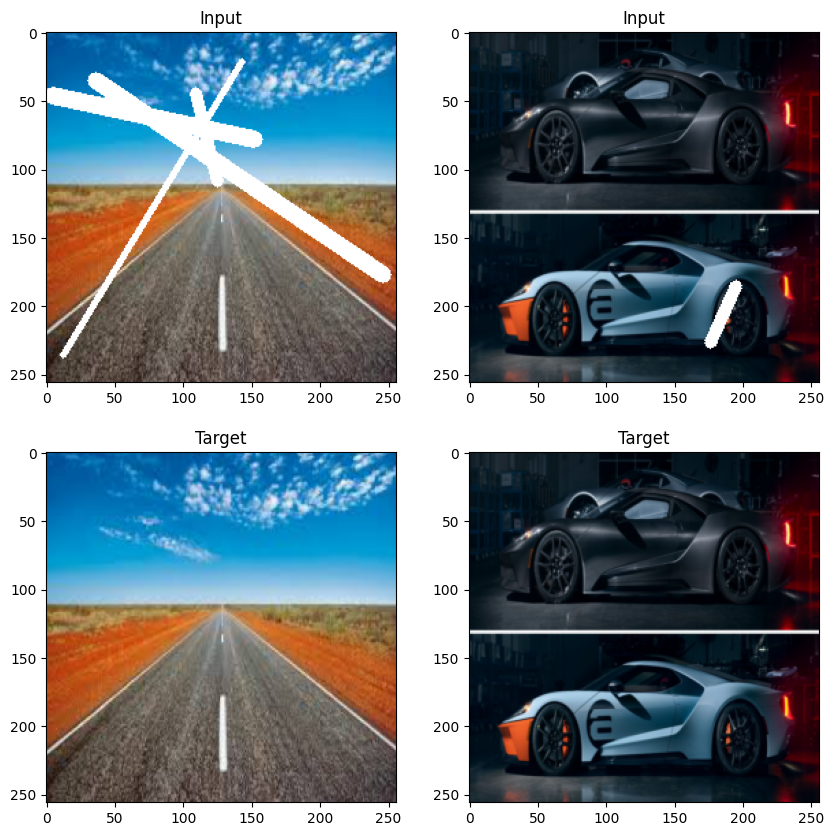

In [ ]:
in_batch, tar_batch = next(iter(train_loader))
in_batch = (in_batch + 1)/2
tar_batch = (tar_batch + 1)/2

plt.figure(figsize=(10, 10))
ax = plt.subplot(2, 2, 1)
plt.imshow(np.squeeze(in_batch[0].numpy().transpose((1, 2, 0))))
plt.title("Input")
ax = plt.subplot(2, 2, 3)
plt.imshow(np.squeeze(tar_batch[0].numpy().transpose((1, 2, 0))))
plt.title("Target")
ax = plt.subplot(2, 2, 2)
plt.imshow(np.squeeze(in_batch[1].numpy().transpose((1, 2, 0))))
plt.title("Input")
ax = plt.subplot(2, 2, 4)
plt.imshow(np.squeeze(tar_batch[1].numpy().transpose((1, 2, 0))))
plt.title("Target")



### Train

In [ ]:
def generate_images(model, inputs, labels):
    model.eval()
    with torch.no_grad():
        inputs, labels = inputs.to(device), labels.to(device)
        predictions = model(inputs)
    inputs, labels, predictions = inputs.cpu().numpy(), labels.cpu().numpy(), predictions.cpu().numpy()
    plt.figure(figsize=(15,20))

    display_list = [inputs[-1].transpose((1, 2, 0)), labels[-1].transpose((1, 2, 0)), predictions[-1].transpose((1, 2, 0))]
    title = ['Input', 'Real', 'Predicted']

    for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.title(title[i])
        plt.imshow((display_list[i] + 1) / 2)
        plt.axis('off')
    plt.show()

In [ ]:
import time

def train_epoch(model, optimizer, criterion, train_dataloader, device, epoch=0, log_interval=50):
    model.train()
    total_psnr, total_count = 0, 0
    losses = []
    start_time = time.time()

    for idx, (inputs, labels) in enumerate(train_dataloader):
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(inputs)

        # compute loss
        loss = criterion(predictions, labels)
        losses.append(loss.item())

        # backward
        loss.backward()
        optimizer.step()

        total_psnr += peak_signal_noise_ratio(predictions, labels)
        total_count += 1
        if idx % log_interval == 0 and idx > 0:
            elapsed = time.time() - start_time
            print(
                "| epoch {:3d} | {:5d}/{:5d} batches "
                "| psnr {:8.3f}".format(
                    epoch, idx, len(train_dataloader), total_psnr / total_count
                )
            )
            total_psnr, total_count = 0, 0
            start_time = time.time()

    epoch_psnr = total_psnr / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_psnr, epoch_loss

In [ ]:
def evaluate_epoch(model, criterion, valid_dataloader, device):
    model.eval()
    total_psnr, total_count = 0, 0
    losses = []

    with torch.no_grad():
        for idx, (inputs, labels) in enumerate(valid_dataloader):
            inputs = inputs.to(device)
            labels = labels.to(device)

            predictions = model(inputs)

            loss = criterion(predictions, labels)
            losses.append(loss.item())


            total_psnr +=  peak_signal_noise_ratio(predictions, labels)
            total_count += 1

    epoch_psnr = total_psnr / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_psnr, epoch_loss

In [ ]:
def train(model, model_name, save_model, optimizer, criterion, train_dataloader, valid_dataloader, num_epochs, device):
    train_psnrs, train_losses = [], []
    eval_psnrs, eval_losses = [], []
    best_psnr_eval = -1000
    times = []
    for epoch in range(1, num_epochs+1):
        epoch_start_time = time.time()
        # Training
        train_psnr, train_loss = train_epoch(model, optimizer, criterion, train_dataloader, device, epoch)
        train_psnrs.append(train_psnr.cpu())
        train_losses.append(train_loss)

        # Evaluation
        eval_psnr, eval_loss = evaluate_epoch(model, criterion, valid_dataloader, device)
        eval_psnrs.append(eval_psnr.cpu())
        eval_losses.append(eval_loss)

        # Save best model
        if best_psnr_eval < eval_psnr:
            torch.save(model.state_dict(), save_model + f'/{model_name}.pt')
            inputs_t, targets_t = next(iter(valid_dataloader))
            generate_images(model, inputs_t, targets_t)
            best_psnr_eval = eval_psnr
        times.append(time.time() - epoch_start_time)
        # Print loss, psnr end epoch
        print("-" * 59)
        print(
            "| End of epoch {:3d} | Time: {:5.2f}s | Train psnr {:8.3f} | Train Loss {:8.3f} "
            "| Valid psnr {:8.3f} | Valid Loss {:8.3f} ".format(
                epoch, time.time() - epoch_start_time, train_psnr, train_loss, eval_psnr, eval_loss
            )
        )
        print("-" * 59)

    # Load best model
    model.load_state_dict(torch.load(save_model + f'/{model_name}.pt'))
    model.eval()
    metrics = {
        'train_psnr': train_psnrs,
        'train_loss': train_losses,
        'valid_psnr': eval_psnrs,
        'valid_loss': eval_losses,
        'time': times
    }
    return model, metrics

In [ ]:
import matplotlib.pyplot as plt

def plot_result(num_epochs, train_psnrs, eval_psnrs, train_losses, eval_losses):
    epochs = list(range(num_epochs))
    fig, axs = plt.subplots(nrows = 1, ncols =2 , figsize = (12,6))
    axs[0].plot(epochs, train_psnrs, label = "Training")
    axs[0].plot(epochs, eval_psnrs, label = "Evaluation")
    axs[1].plot(epochs, train_losses, label = "Training")
    axs[1].plot(epochs, eval_losses, label = "Evaluation")
    axs[0].set_xlabel("Epochs")
    axs[1].set_xlabel("Epochs")
    axs[0].set_ylabel("PSNR")
    axs[1].set_ylabel("Loss")
    plt.legend()

In [ ]:
import matplotlib.pyplot as plt

def predict_and_display(model, test_dataloader, device):
    model.eval()

    with torch.no_grad():
        for idx, (inputs, labels) in enumerate(test_dataloader):
            if idx >= 10:
                break
            inputs = inputs.to(device)
            predictions = model(inputs)
            generate_images(model, inputs, labels)
            plt.show()


# Usage example:
# predict_and_display(model, test_dataloader, device)


#### Unet No Skip Connection

| epoch   1 |    50/   86 batches | psnr   14.315


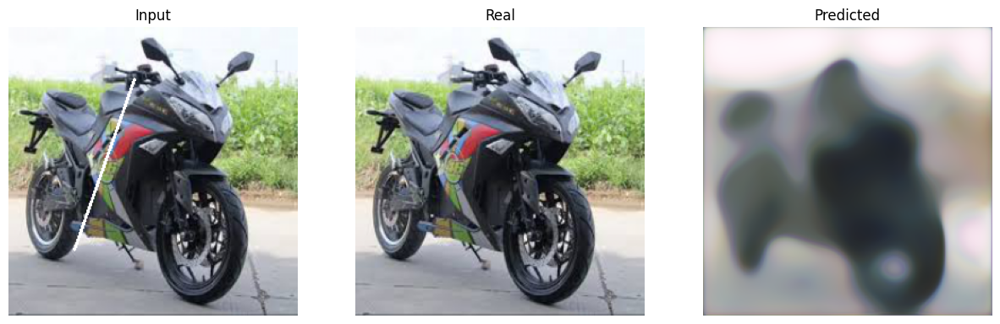

-----------------------------------------------------------
| End of epoch   1 | Time: 46.18s | Train psnr   15.522 | Train Loss    0.267 | Valid psnr   16.735 | Valid Loss    0.202 
-----------------------------------------------------------
| epoch   2 |    50/   86 batches | psnr   16.167
-----------------------------------------------------------
| End of epoch   2 | Time: 43.95s | Train psnr   15.418 | Train Loss    0.224 | Valid psnr   13.524 | Valid Loss    0.290 
-----------------------------------------------------------
| epoch   3 |    50/   86 batches | psnr   15.924


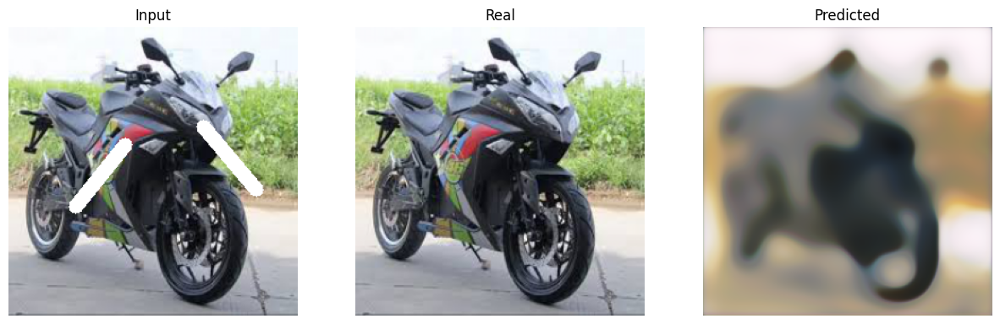

-----------------------------------------------------------
| End of epoch   3 | Time: 45.41s | Train psnr   16.659 | Train Loss    0.214 | Valid psnr   17.154 | Valid Loss    0.192 
-----------------------------------------------------------
| epoch   4 |    50/   86 batches | psnr   16.846
-----------------------------------------------------------
| End of epoch   4 | Time: 45.63s | Train psnr   16.566 | Train Loss    0.199 | Valid psnr   13.870 | Valid Loss    0.276 
-----------------------------------------------------------
| epoch   5 |    50/   86 batches | psnr   15.940
-----------------------------------------------------------
| End of epoch   5 | Time: 45.20s | Train psnr   16.760 | Train Loss    0.212 | Valid psnr   17.154 | Valid Loss    0.194 
-----------------------------------------------------------
| epoch   6 |    50/   86 batches | psnr   17.170


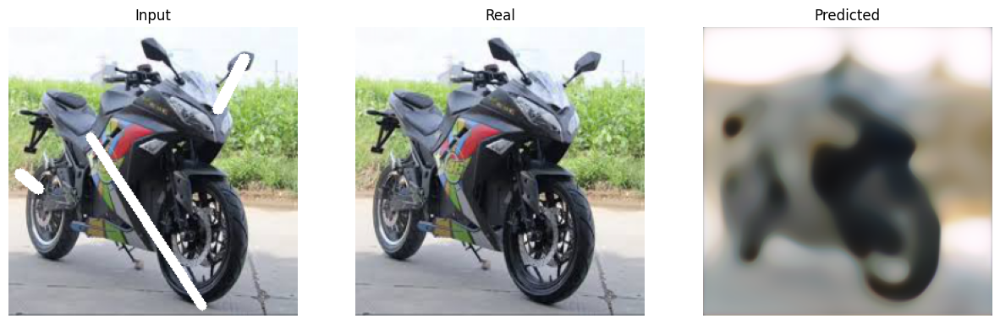

-----------------------------------------------------------
| End of epoch   6 | Time: 44.49s | Train psnr   17.027 | Train Loss    0.188 | Valid psnr   17.784 | Valid Loss    0.171 
-----------------------------------------------------------
| epoch   7 |    50/   86 batches | psnr   16.898
-----------------------------------------------------------
| End of epoch   7 | Time: 46.02s | Train psnr   16.786 | Train Loss    0.196 | Valid psnr   17.489 | Valid Loss    0.180 
-----------------------------------------------------------
| epoch   8 |    50/   86 batches | psnr   17.451
-----------------------------------------------------------
| End of epoch   8 | Time: 45.57s | Train psnr   17.486 | Train Loss    0.180 | Valid psnr   16.450 | Valid Loss    0.205 
-----------------------------------------------------------
| epoch   9 |    50/   86 batches | psnr   17.417
-----------------------------------------------------------
| End of epoch   9 | Time: 46.78s | Train psnr   17.663 | Tra

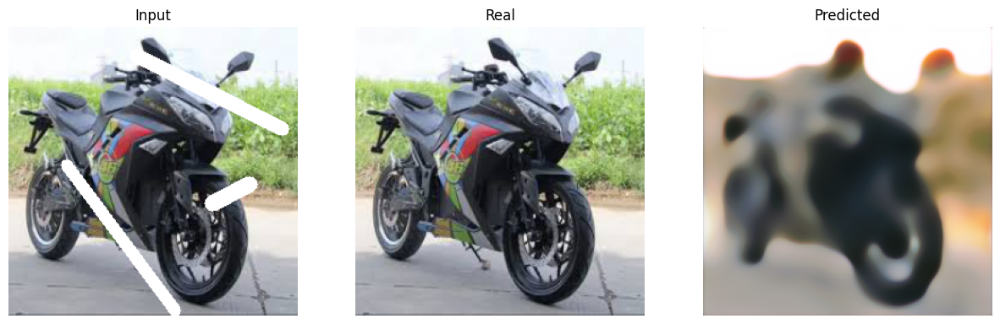

-----------------------------------------------------------
| End of epoch  10 | Time: 46.02s | Train psnr   17.878 | Train Loss    0.169 | Valid psnr   17.816 | Valid Loss    0.168 
-----------------------------------------------------------
| epoch  11 |    50/   86 batches | psnr   17.980


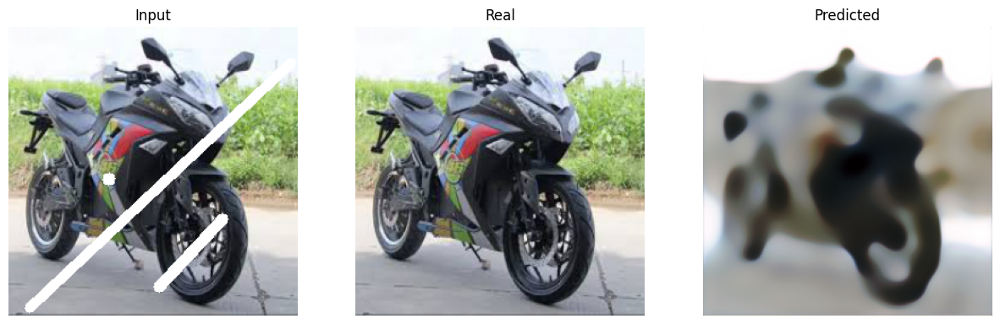

-----------------------------------------------------------
| End of epoch  11 | Time: 47.14s | Train psnr   18.205 | Train Loss    0.165 | Valid psnr   18.005 | Valid Loss    0.164 
-----------------------------------------------------------
| epoch  12 |    50/   86 batches | psnr   18.122
-----------------------------------------------------------
| End of epoch  12 | Time: 43.64s | Train psnr   18.302 | Train Loss    0.163 | Valid psnr   17.529 | Valid Loss    0.181 
-----------------------------------------------------------
| epoch  13 |    50/   86 batches | psnr   18.317


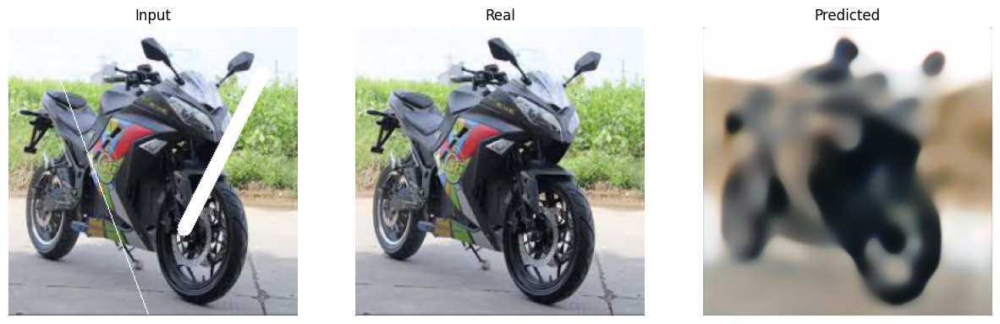

-----------------------------------------------------------
| End of epoch  13 | Time: 46.55s | Train psnr   18.333 | Train Loss    0.159 | Valid psnr   18.479 | Valid Loss    0.154 
-----------------------------------------------------------
| epoch  14 |    50/   86 batches | psnr   18.354


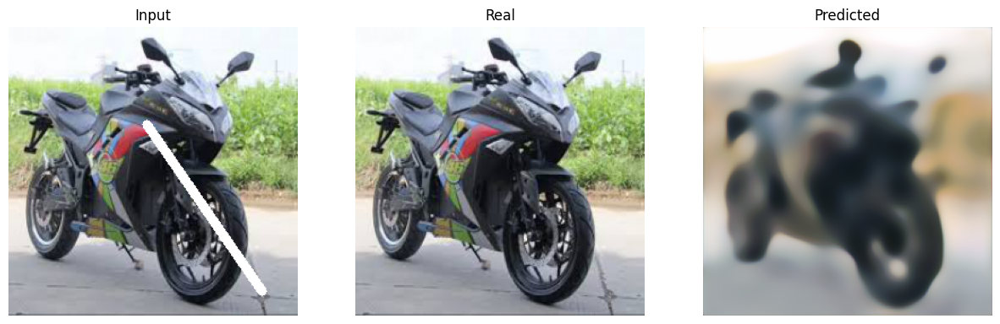

-----------------------------------------------------------
| End of epoch  14 | Time: 45.38s | Train psnr   18.518 | Train Loss    0.158 | Valid psnr   18.581 | Valid Loss    0.154 
-----------------------------------------------------------
| epoch  15 |    50/   86 batches | psnr   18.156


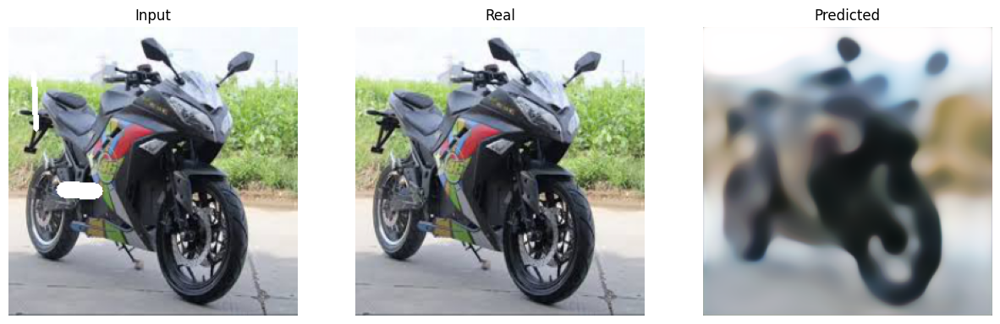

-----------------------------------------------------------
| End of epoch  15 | Time: 44.80s | Train psnr   18.630 | Train Loss    0.159 | Valid psnr   18.719 | Valid Loss    0.148 
-----------------------------------------------------------
| epoch  16 |    50/   86 batches | psnr   18.330
-----------------------------------------------------------
| End of epoch  16 | Time: 45.79s | Train psnr   18.803 | Train Loss    0.156 | Valid psnr   18.602 | Valid Loss    0.160 
-----------------------------------------------------------
| epoch  17 |    50/   86 batches | psnr   18.684
-----------------------------------------------------------
| End of epoch  17 | Time: 46.21s | Train psnr   18.342 | Train Loss    0.154 | Valid psnr   18.473 | Valid Loss    0.156 
-----------------------------------------------------------
| epoch  18 |    50/   86 batches | psnr   18.620
-----------------------------------------------------------
| End of epoch  18 | Time: 44.97s | Train psnr   18.095 | Tra

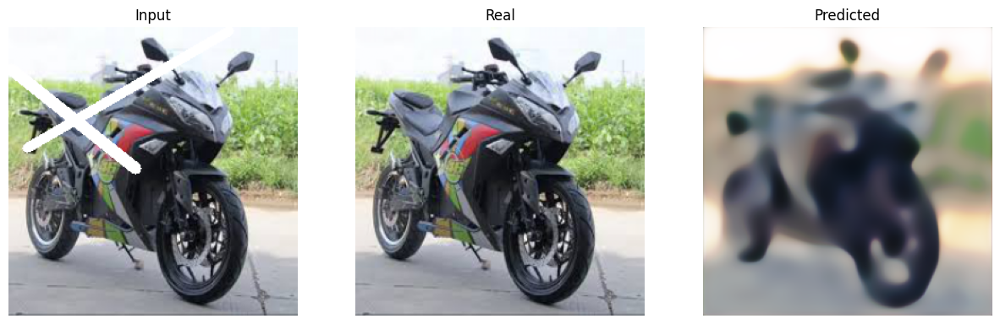

-----------------------------------------------------------
| End of epoch  22 | Time: 45.23s | Train psnr   18.737 | Train Loss    0.157 | Valid psnr   18.873 | Valid Loss    0.151 
-----------------------------------------------------------
| epoch  23 |    50/   86 batches | psnr   18.808
-----------------------------------------------------------
| End of epoch  23 | Time: 45.93s | Train psnr   18.969 | Train Loss    0.149 | Valid psnr   18.858 | Valid Loss    0.147 
-----------------------------------------------------------
| epoch  24 |    50/   86 batches | psnr   19.019


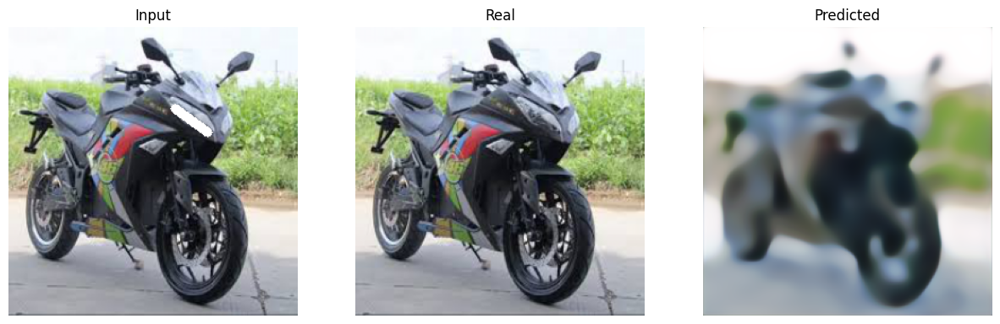

-----------------------------------------------------------
| End of epoch  24 | Time: 45.59s | Train psnr   19.148 | Train Loss    0.145 | Valid psnr   19.119 | Valid Loss    0.145 
-----------------------------------------------------------
| epoch  25 |    50/   86 batches | psnr   18.937


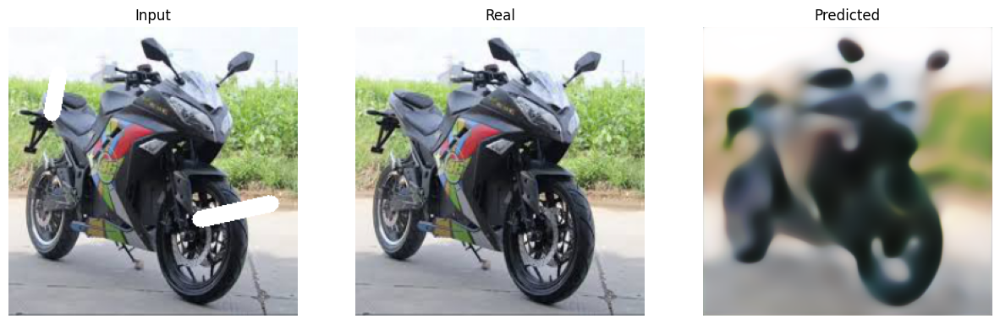

-----------------------------------------------------------
| End of epoch  25 | Time: 45.72s | Train psnr   19.228 | Train Loss    0.144 | Valid psnr   19.170 | Valid Loss    0.139 
-----------------------------------------------------------
| epoch  26 |    50/   86 batches | psnr   19.074
-----------------------------------------------------------
| End of epoch  26 | Time: 44.99s | Train psnr   19.005 | Train Loss    0.146 | Valid psnr   18.919 | Valid Loss    0.151 
-----------------------------------------------------------
| epoch  27 |    50/   86 batches | psnr   19.083
-----------------------------------------------------------
| End of epoch  27 | Time: 44.80s | Train psnr   19.302 | Train Loss    0.142 | Valid psnr   19.136 | Valid Loss    0.142 
-----------------------------------------------------------
| epoch  28 |    50/   86 batches | psnr   19.349
-----------------------------------------------------------
| End of epoch  28 | Time: 45.50s | Train psnr   19.637 | Tra

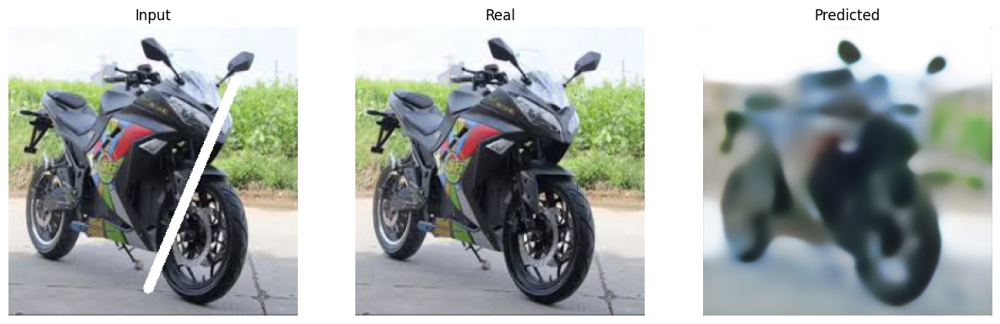

-----------------------------------------------------------
| End of epoch  29 | Time: 46.88s | Train psnr   19.328 | Train Loss    0.140 | Valid psnr   19.232 | Valid Loss    0.145 
-----------------------------------------------------------
| epoch  30 |    50/   86 batches | psnr   19.561
-----------------------------------------------------------
| End of epoch  30 | Time: 45.86s | Train psnr   19.425 | Train Loss    0.136 | Valid psnr   18.598 | Valid Loss    0.161 
-----------------------------------------------------------
| epoch  31 |    50/   86 batches | psnr   19.541


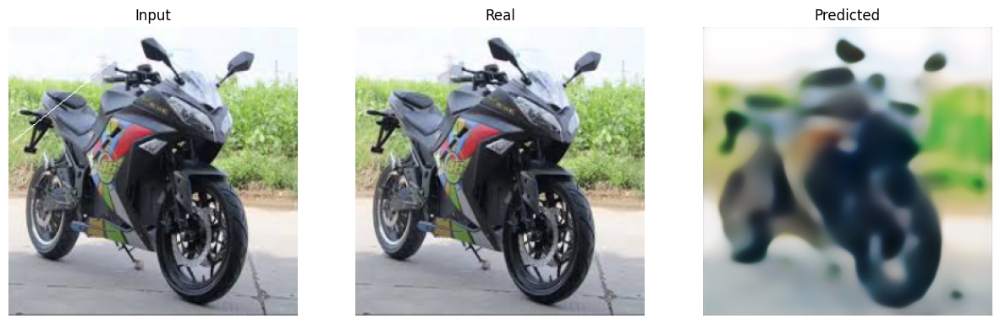

-----------------------------------------------------------
| End of epoch  31 | Time: 45.60s | Train psnr   19.468 | Train Loss    0.137 | Valid psnr   19.251 | Valid Loss    0.141 
-----------------------------------------------------------
| epoch  32 |    50/   86 batches | psnr   19.593
-----------------------------------------------------------
| End of epoch  32 | Time: 44.47s | Train psnr   19.873 | Train Loss    0.133 | Valid psnr   19.030 | Valid Loss    0.143 
-----------------------------------------------------------
| epoch  33 |    50/   86 batches | psnr   19.599


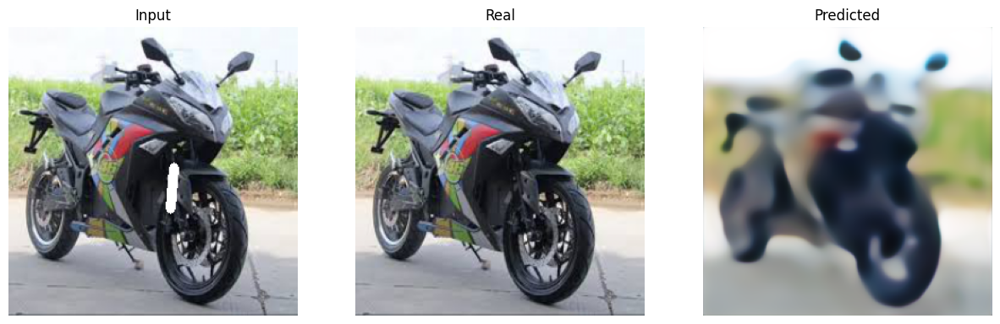

-----------------------------------------------------------
| End of epoch  33 | Time: 44.96s | Train psnr   19.818 | Train Loss    0.134 | Valid psnr   19.758 | Valid Loss    0.131 
-----------------------------------------------------------
| epoch  34 |    50/   86 batches | psnr   19.740
-----------------------------------------------------------
| End of epoch  34 | Time: 45.40s | Train psnr   20.077 | Train Loss    0.130 | Valid psnr   19.667 | Valid Loss    0.137 
-----------------------------------------------------------
| epoch  35 |    50/   86 batches | psnr   19.864


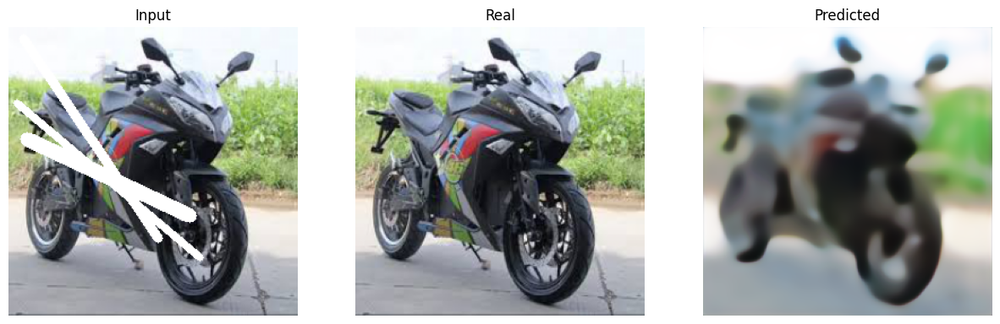

-----------------------------------------------------------
| End of epoch  35 | Time: 45.47s | Train psnr   19.933 | Train Loss    0.130 | Valid psnr   19.899 | Valid Loss    0.128 
-----------------------------------------------------------
| epoch  36 |    50/   86 batches | psnr   19.866
-----------------------------------------------------------
| End of epoch  36 | Time: 44.18s | Train psnr   19.856 | Train Loss    0.131 | Valid psnr   19.573 | Valid Loss    0.132 
-----------------------------------------------------------
| epoch  37 |    50/   86 batches | psnr   19.932
-----------------------------------------------------------
| End of epoch  37 | Time: 44.85s | Train psnr   20.048 | Train Loss    0.128 | Valid psnr   19.522 | Valid Loss    0.138 
-----------------------------------------------------------
| epoch  38 |    50/   86 batches | psnr   20.170
-----------------------------------------------------------
| End of epoch  38 | Time: 45.53s | Train psnr   19.618 | Tra

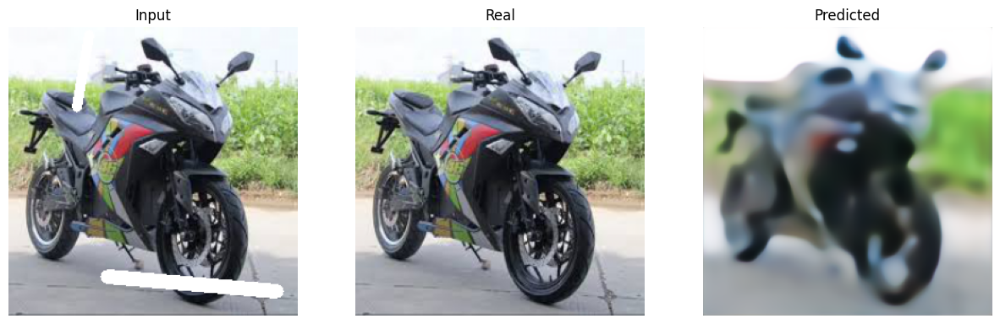

-----------------------------------------------------------
| End of epoch  42 | Time: 45.18s | Train psnr   20.274 | Train Loss    0.128 | Valid psnr   19.985 | Valid Loss    0.128 
-----------------------------------------------------------
| epoch  43 |    50/   86 batches | psnr   20.141
-----------------------------------------------------------
| End of epoch  43 | Time: 45.09s | Train psnr   20.131 | Train Loss    0.126 | Valid psnr   19.763 | Valid Loss    0.133 
-----------------------------------------------------------
| epoch  44 |    50/   86 batches | psnr   19.687
-----------------------------------------------------------
| End of epoch  44 | Time: 45.98s | Train psnr   20.106 | Train Loss    0.131 | Valid psnr   19.913 | Valid Loss    0.139 
-----------------------------------------------------------
| epoch  45 |    50/   86 batches | psnr   20.268


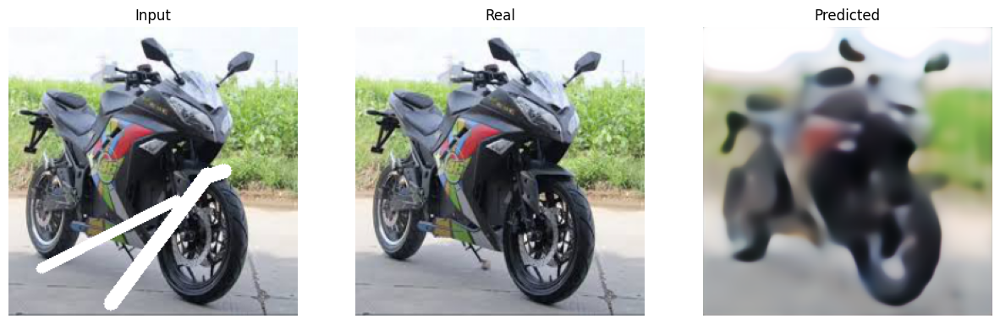

-----------------------------------------------------------
| End of epoch  45 | Time: 45.20s | Train psnr   20.344 | Train Loss    0.124 | Valid psnr   20.192 | Valid Loss    0.123 
-----------------------------------------------------------
| epoch  46 |    50/   86 batches | psnr   20.511
-----------------------------------------------------------
| End of epoch  46 | Time: 45.37s | Train psnr   20.146 | Train Loss    0.122 | Valid psnr   20.167 | Valid Loss    0.126 
-----------------------------------------------------------
| epoch  47 |    50/   86 batches | psnr   20.437


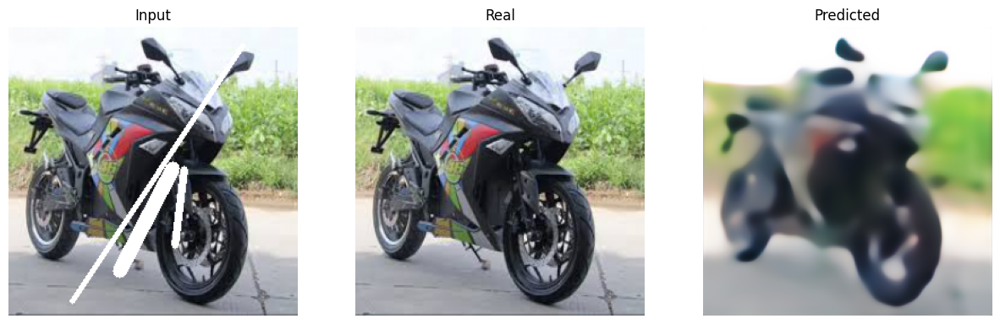

-----------------------------------------------------------
| End of epoch  47 | Time: 48.56s | Train psnr   20.466 | Train Loss    0.121 | Valid psnr   20.229 | Valid Loss    0.124 
-----------------------------------------------------------
| epoch  48 |    50/   86 batches | psnr   20.513
-----------------------------------------------------------
| End of epoch  48 | Time: 46.02s | Train psnr   20.386 | Train Loss    0.120 | Valid psnr   20.200 | Valid Loss    0.120 
-----------------------------------------------------------
| epoch  49 |    50/   86 batches | psnr   20.414


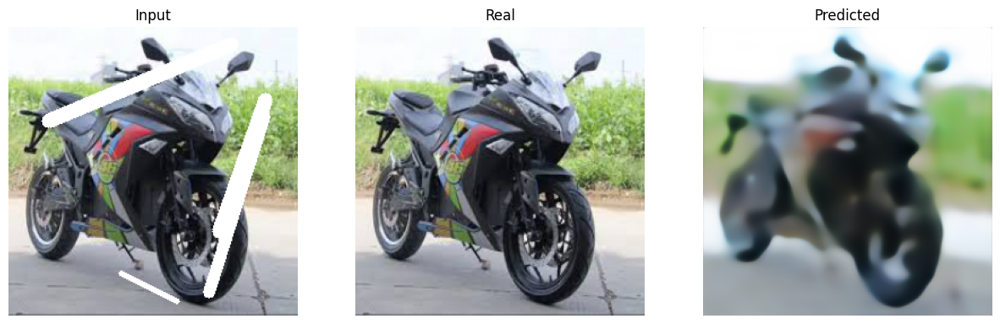

-----------------------------------------------------------
| End of epoch  49 | Time: 44.96s | Train psnr   20.295 | Train Loss    0.122 | Valid psnr   20.379 | Valid Loss    0.119 
-----------------------------------------------------------
| epoch  50 |    50/   86 batches | psnr   20.520


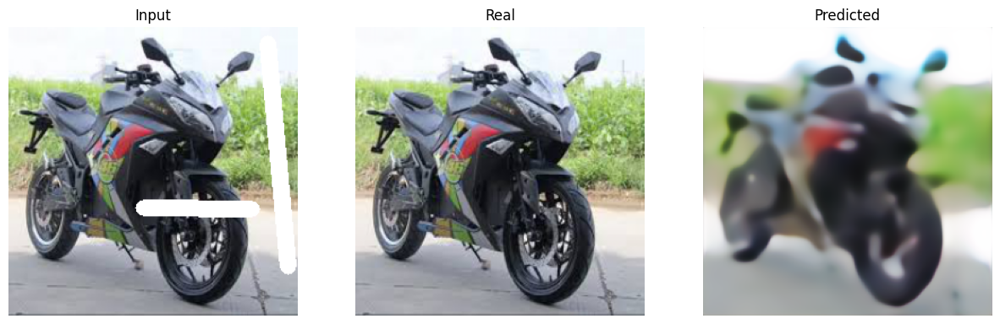

-----------------------------------------------------------
| End of epoch  50 | Time: 45.26s | Train psnr   20.433 | Train Loss    0.120 | Valid psnr   20.463 | Valid Loss    0.119 
-----------------------------------------------------------
| epoch  51 |    50/   86 batches | psnr   20.593
-----------------------------------------------------------
| End of epoch  51 | Time: 45.69s | Train psnr   20.640 | Train Loss    0.117 | Valid psnr   20.057 | Valid Loss    0.130 
-----------------------------------------------------------
| epoch  52 |    50/   86 batches | psnr   20.357
-----------------------------------------------------------
| End of epoch  52 | Time: 45.45s | Train psnr   20.726 | Train Loss    0.120 | Valid psnr   19.713 | Valid Loss    0.131 
-----------------------------------------------------------
| epoch  53 |    50/   86 batches | psnr   20.657
-----------------------------------------------------------
| End of epoch  53 | Time: 44.95s | Train psnr   20.427 | Tra

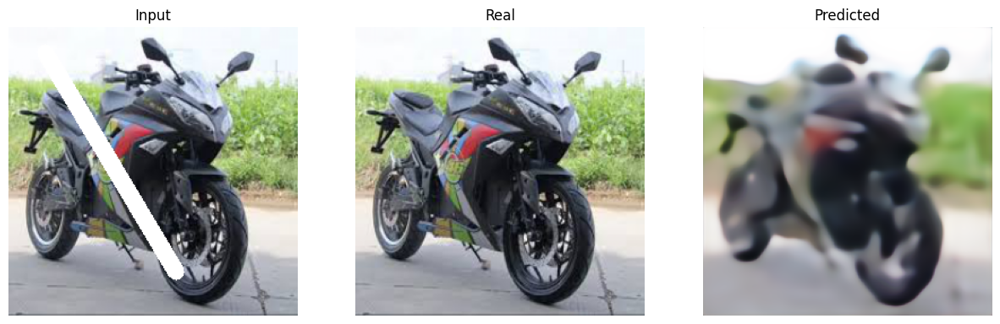

-----------------------------------------------------------
| End of epoch  60 | Time: 45.68s | Train psnr   20.793 | Train Loss    0.116 | Valid psnr   20.789 | Valid Loss    0.114 
-----------------------------------------------------------
| epoch  61 |    50/   86 batches | psnr   20.797
-----------------------------------------------------------
| End of epoch  61 | Time: 45.00s | Train psnr   20.963 | Train Loss    0.114 | Valid psnr   20.514 | Valid Loss    0.120 
-----------------------------------------------------------
| epoch  62 |    50/   86 batches | psnr   20.894
-----------------------------------------------------------
| End of epoch  62 | Time: 44.85s | Train psnr   20.948 | Train Loss    0.113 | Valid psnr   20.491 | Valid Loss    0.120 
-----------------------------------------------------------
| epoch  63 |    50/   86 batches | psnr   20.698
-----------------------------------------------------------
| End of epoch  63 | Time: 46.07s | Train psnr   21.165 | Tra

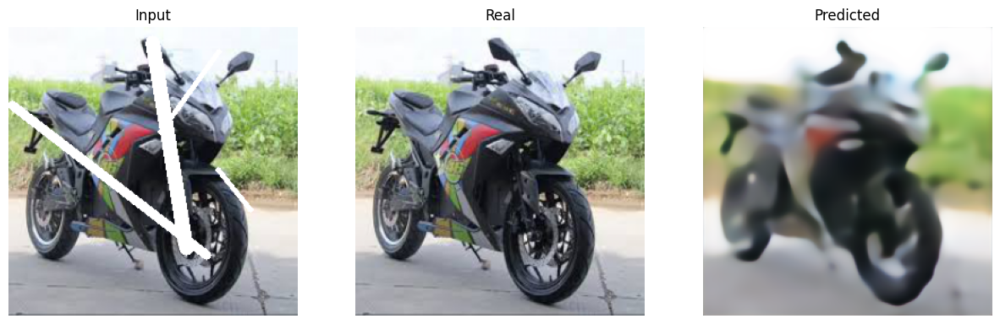

-----------------------------------------------------------
| End of epoch  65 | Time: 48.11s | Train psnr   21.144 | Train Loss    0.114 | Valid psnr   20.990 | Valid Loss    0.110 
-----------------------------------------------------------
| epoch  66 |    50/   86 batches | psnr   20.969
-----------------------------------------------------------
| End of epoch  66 | Time: 45.61s | Train psnr   21.046 | Train Loss    0.113 | Valid psnr   20.538 | Valid Loss    0.123 
-----------------------------------------------------------
| epoch  67 |    50/   86 batches | psnr   21.196
-----------------------------------------------------------
| End of epoch  67 | Time: 44.48s | Train psnr   20.924 | Train Loss    0.111 | Valid psnr   20.404 | Valid Loss    0.117 
-----------------------------------------------------------
| epoch  68 |    50/   86 batches | psnr   21.201
-----------------------------------------------------------
| End of epoch  68 | Time: 45.11s | Train psnr   20.989 | Tra

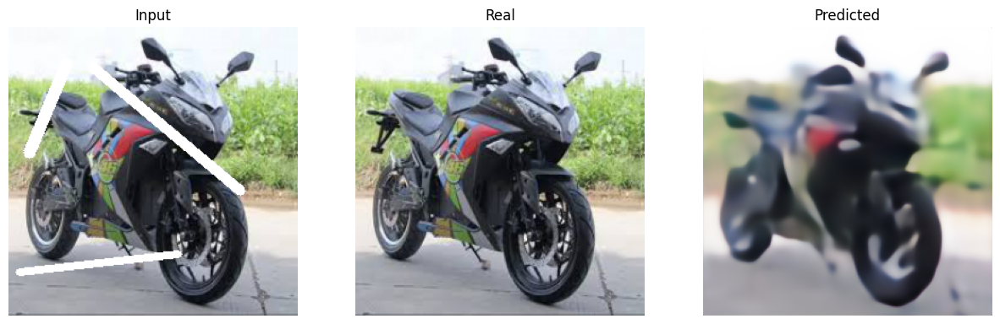

-----------------------------------------------------------
| End of epoch  82 | Time: 46.12s | Train psnr   21.396 | Train Loss    0.106 | Valid psnr   21.026 | Valid Loss    0.108 
-----------------------------------------------------------
| epoch  83 |    50/   86 batches | psnr   21.375
-----------------------------------------------------------
| End of epoch  83 | Time: 44.43s | Train psnr   21.502 | Train Loss    0.106 | Valid psnr   20.116 | Valid Loss    0.126 
-----------------------------------------------------------
| epoch  84 |    50/   86 batches | psnr   21.130


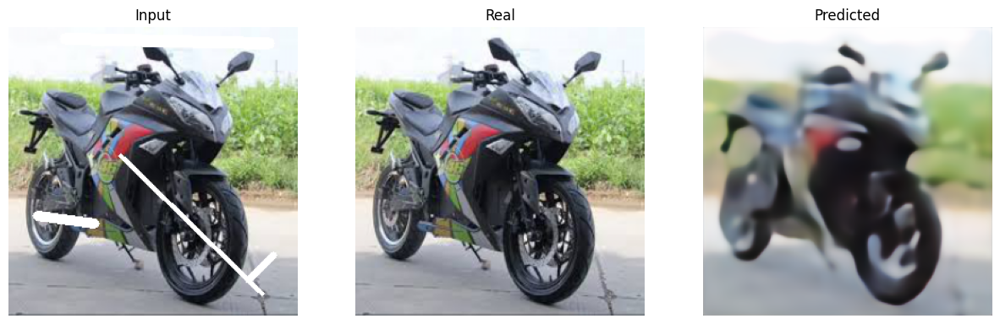

-----------------------------------------------------------
| End of epoch  84 | Time: 44.40s | Train psnr   21.289 | Train Loss    0.110 | Valid psnr   21.155 | Valid Loss    0.110 
-----------------------------------------------------------
| epoch  85 |    50/   86 batches | psnr   21.449
-----------------------------------------------------------
| End of epoch  85 | Time: 44.05s | Train psnr   21.395 | Train Loss    0.106 | Valid psnr   21.129 | Valid Loss    0.109 
-----------------------------------------------------------
| epoch  86 |    50/   86 batches | psnr   21.540


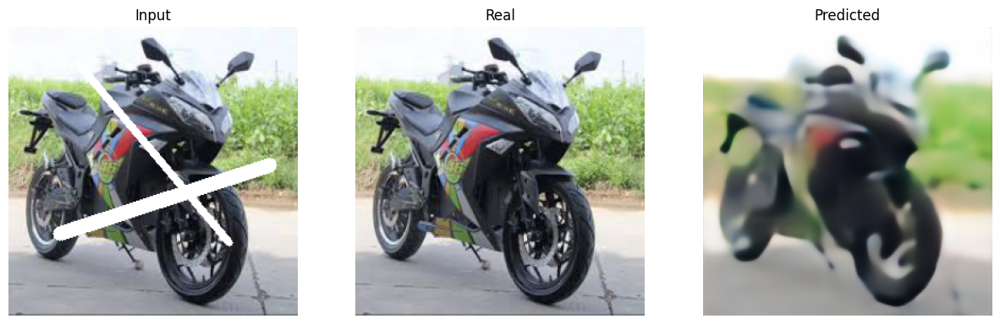

-----------------------------------------------------------
| End of epoch  86 | Time: 43.58s | Train psnr   21.600 | Train Loss    0.104 | Valid psnr   21.173 | Valid Loss    0.106 
-----------------------------------------------------------
| epoch  87 |    50/   86 batches | psnr   21.389
-----------------------------------------------------------
| End of epoch  87 | Time: 44.18s | Train psnr   21.528 | Train Loss    0.107 | Valid psnr   20.856 | Valid Loss    0.119 
-----------------------------------------------------------
| epoch  88 |    50/   86 batches | psnr   21.426
-----------------------------------------------------------
| End of epoch  88 | Time: 44.07s | Train psnr   21.933 | Train Loss    0.104 | Valid psnr   21.122 | Valid Loss    0.109 
-----------------------------------------------------------
| epoch  89 |    50/   86 batches | psnr   21.515
-----------------------------------------------------------
| End of epoch  89 | Time: 44.06s | Train psnr   21.550 | Tra

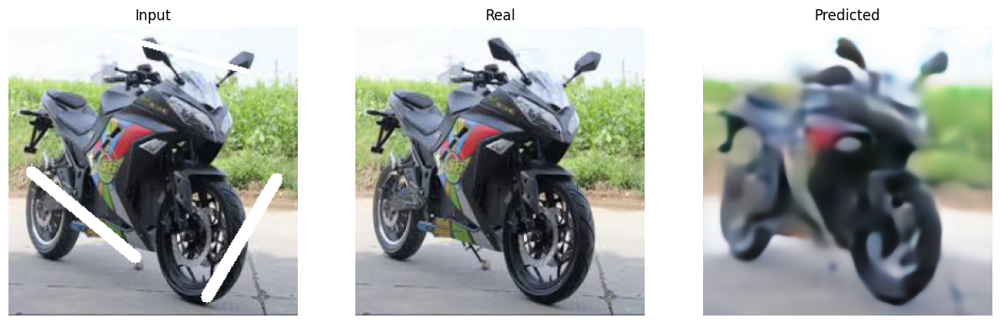

-----------------------------------------------------------
| End of epoch  99 | Time: 47.00s | Train psnr   21.797 | Train Loss    0.102 | Valid psnr   21.452 | Valid Loss    0.106 
-----------------------------------------------------------
| epoch 100 |    50/   86 batches | psnr   21.875
-----------------------------------------------------------
| End of epoch 100 | Time: 49.34s | Train psnr   21.608 | Train Loss    0.102 | Valid psnr   21.156 | Valid Loss    0.107 
-----------------------------------------------------------


In [ ]:
import torch.optim as optim

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IP_unet_model_noskip = II_Unet_NoSkip().to(device)
IP_unet_model_noskip.to(device)

criterion = nn.L1Loss()

optimizer = optim.Adam(IP_unet_model_noskip.parameters(), lr=1e-4, betas=[0.5,0.999])

save_model = './UNET'
os.makedirs(save_model, exist_ok = True)

EPOCHS = 100
IP_unet_model_noskip, metrics = train(
    IP_unet_model_noskip, 'IP_unet_model_noskip', save_model, optimizer, criterion, train_loader, test_loader, EPOCHS, device
)

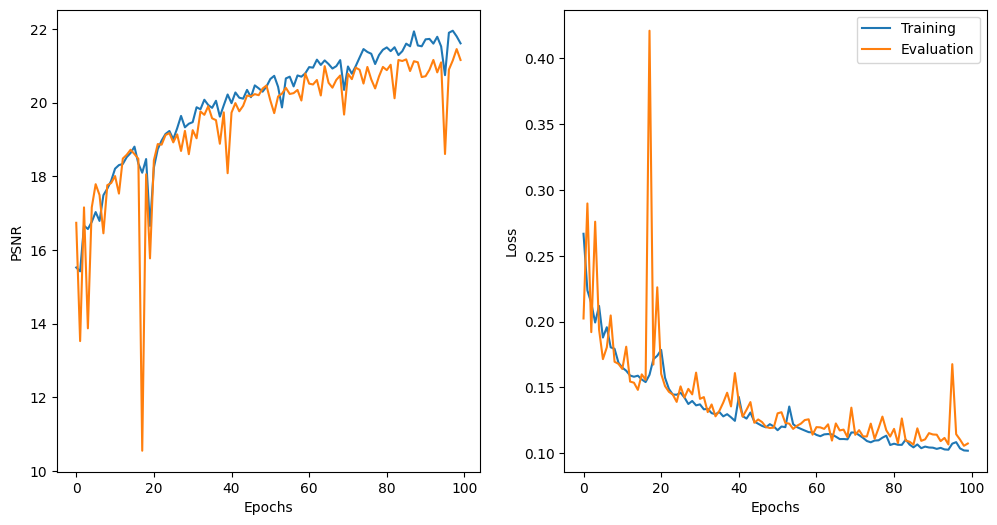

In [ ]:
plot_result(
    EPOCHS,
    metrics["train_psnr"],
    metrics["valid_psnr"],
    metrics["train_loss"],
    metrics["valid_loss"]
)

In [ ]:
test_psnr, test_loss = evaluate_epoch(IP_unet_model_noskip, criterion, test_loader, device)
test_psnr, test_loss

(tensor(21.4306, device='cuda:0'), 0.10577464374628934)

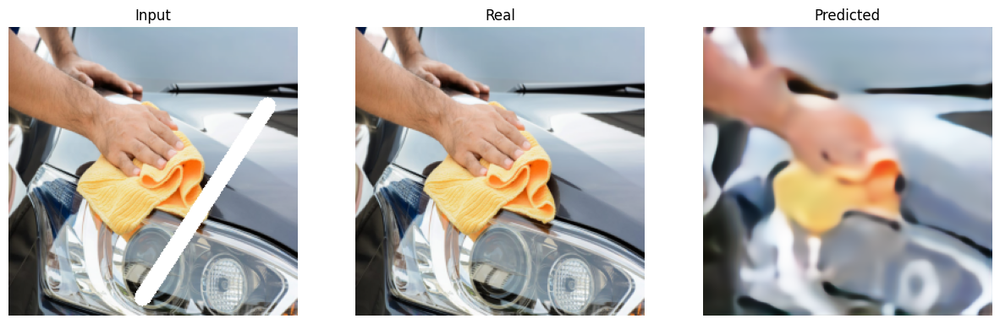

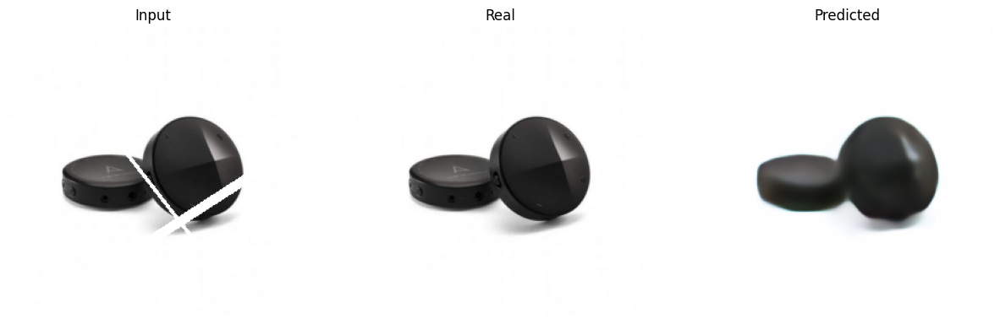

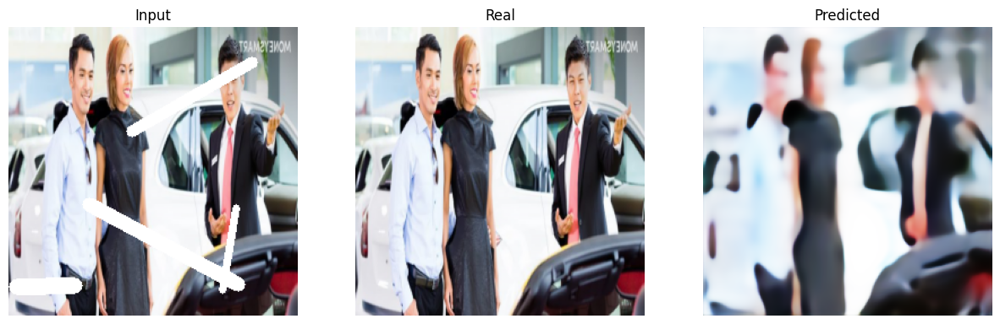

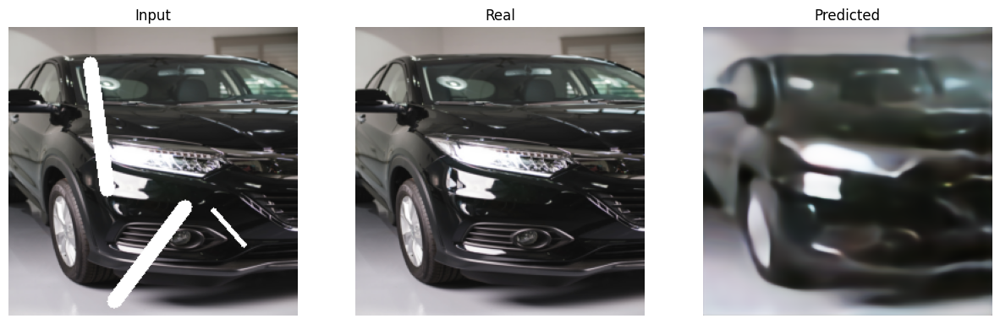

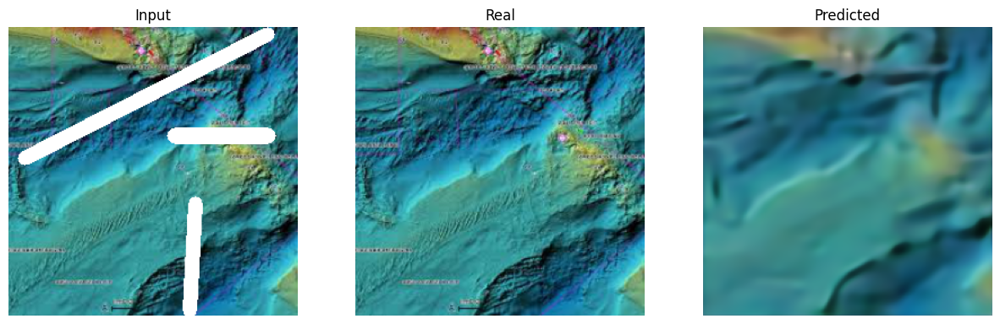

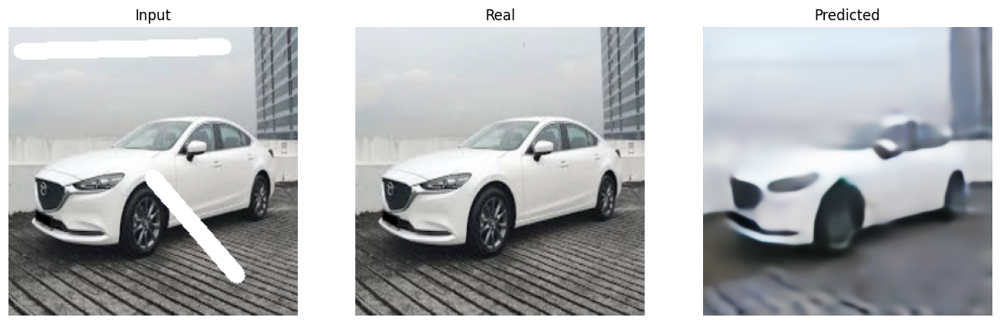

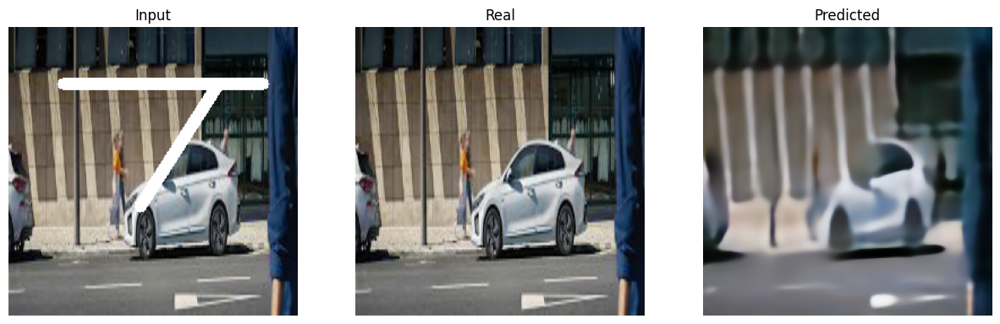

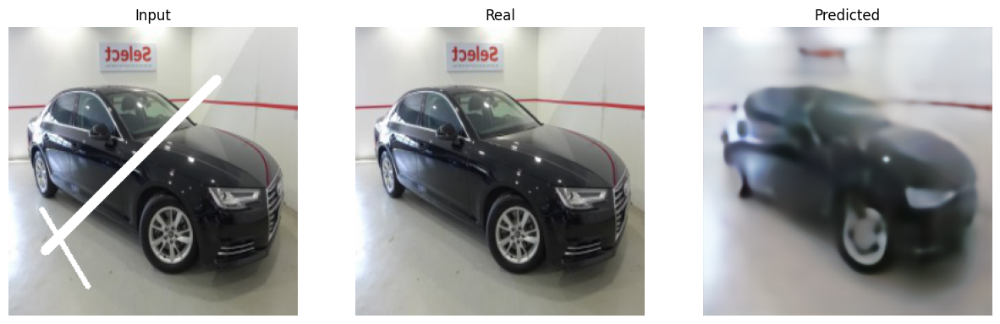

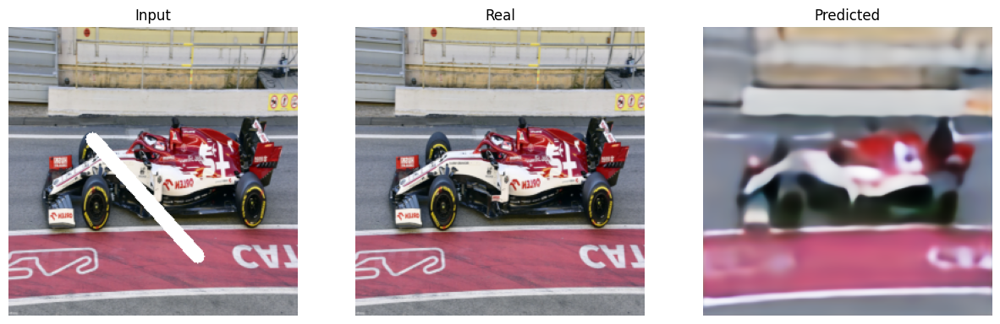

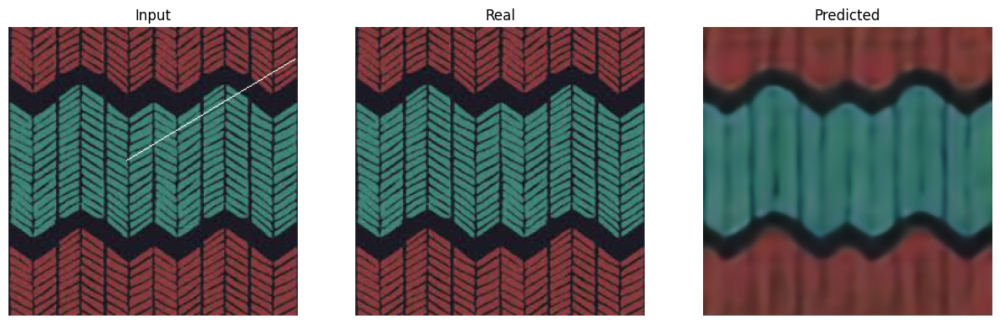

In [ ]:
predict_and_display(IP_unet_model_noskip, train_loader, device)

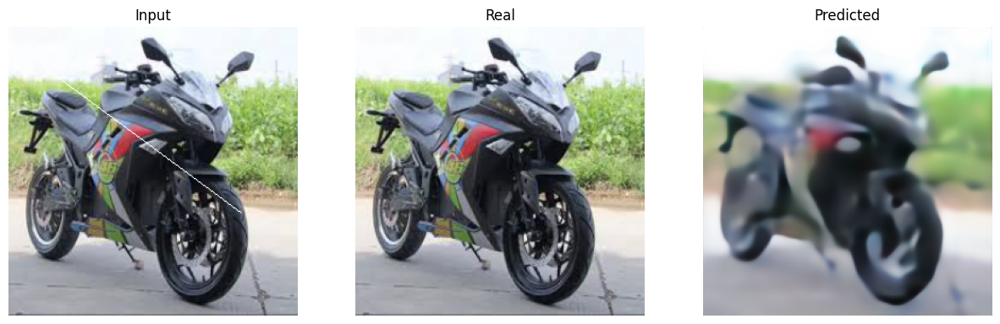

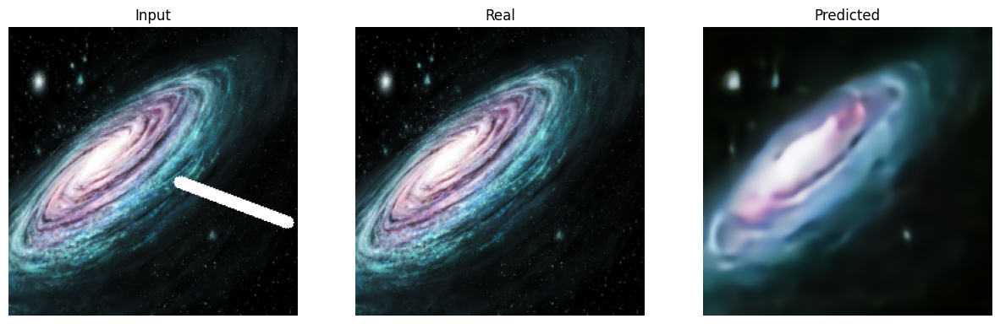

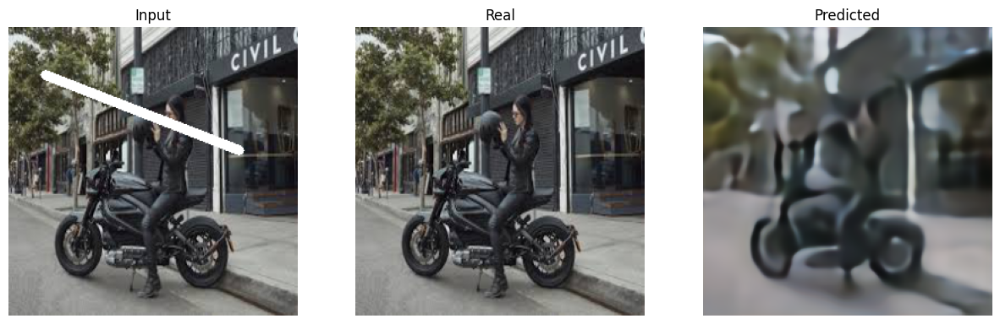

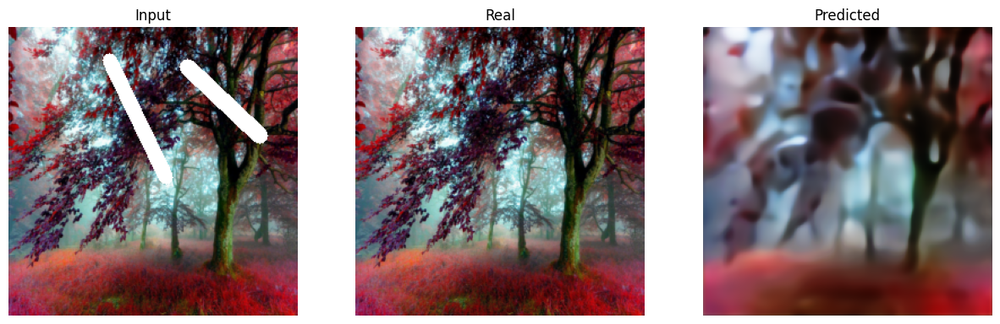

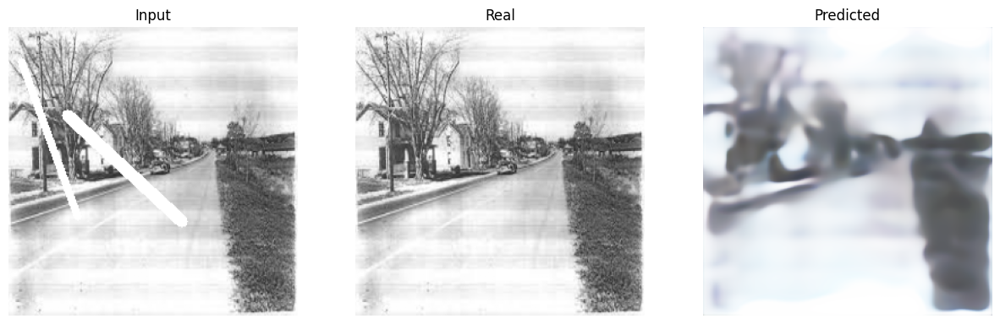

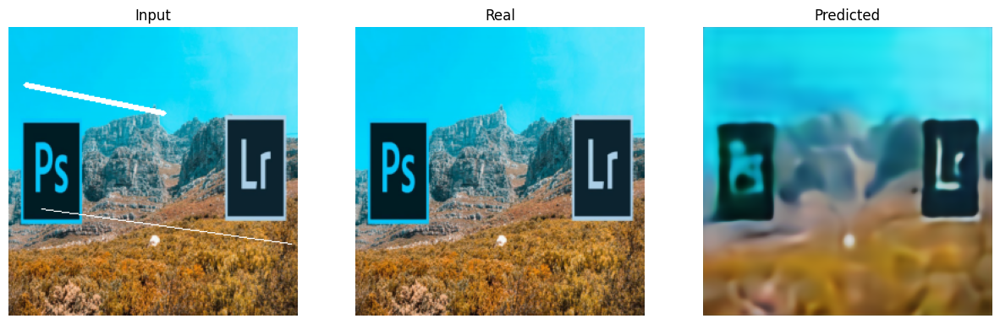

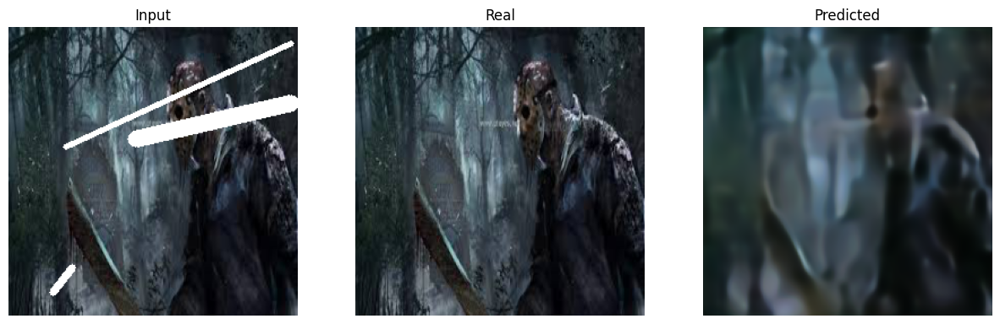

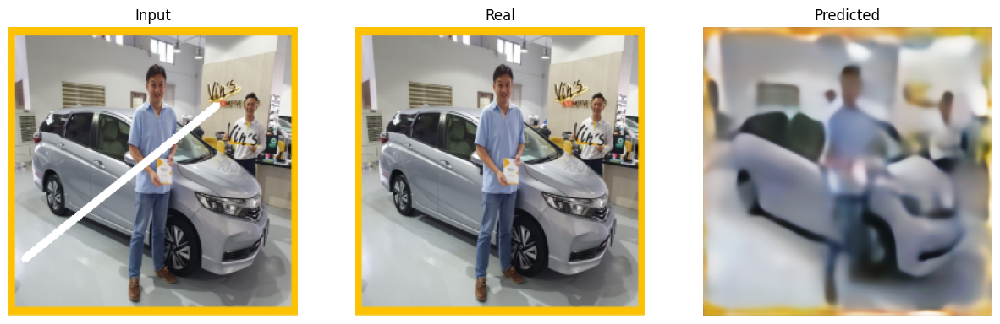

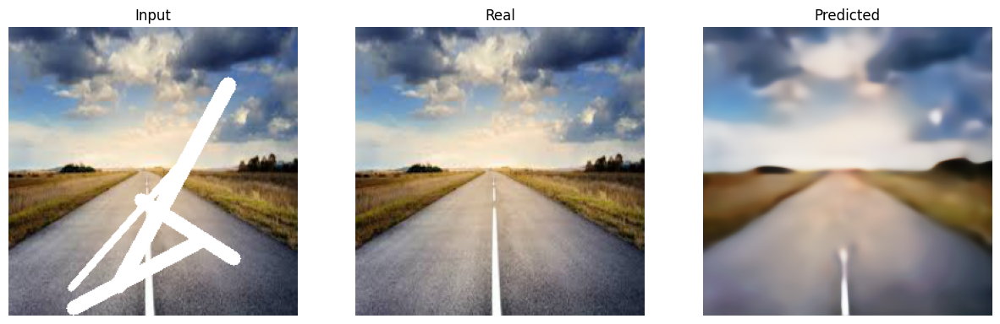

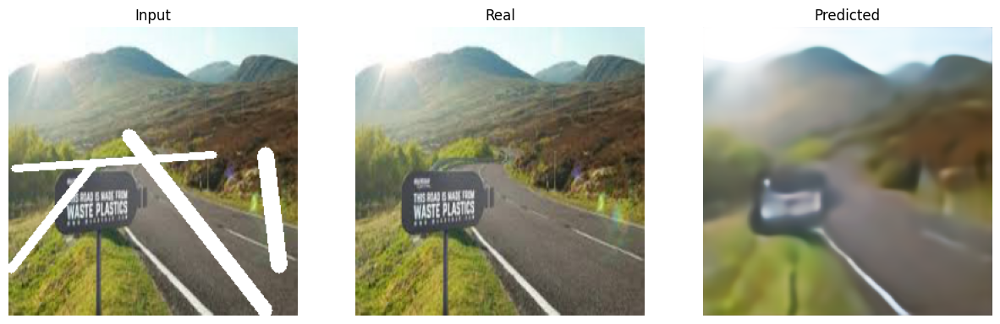

In [ ]:
predict_and_display(IP_unet_model_noskip, test_loader, device)

#### Unet

| epoch   1 |    50/   86 batches | psnr   18.568


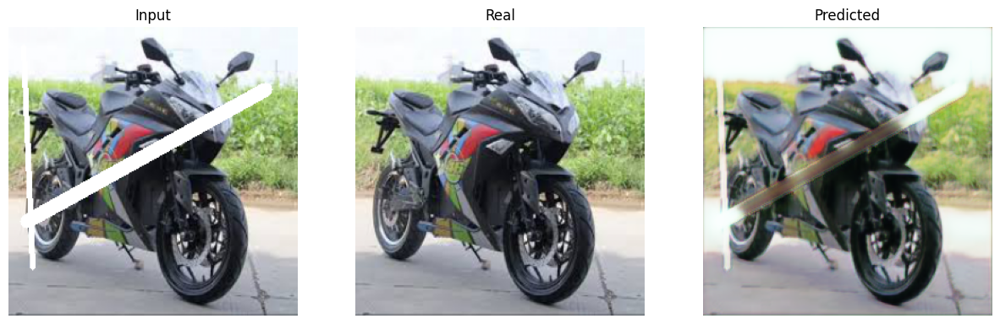

-----------------------------------------------------------
| End of epoch   1 | Time: 43.34s | Train psnr   21.589 | Train Loss    0.159 | Valid psnr   22.608 | Valid Loss    0.084 
-----------------------------------------------------------
| epoch   2 |    50/   86 batches | psnr   21.908


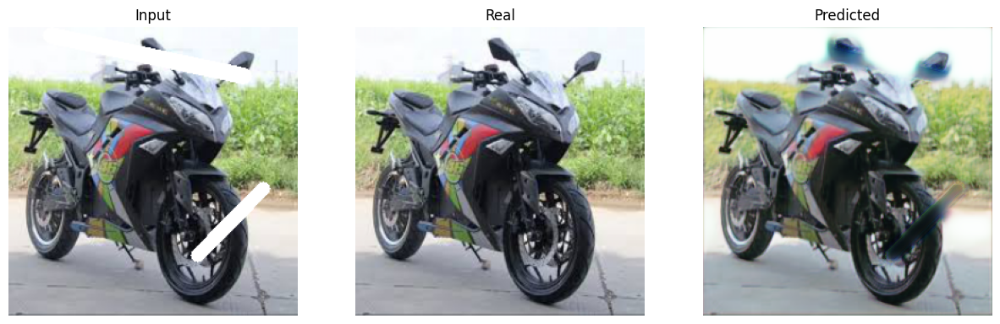

-----------------------------------------------------------
| End of epoch   2 | Time: 42.49s | Train psnr   23.213 | Train Loss    0.108 | Valid psnr   24.316 | Valid Loss    0.068 
-----------------------------------------------------------
| epoch   3 |    50/   86 batches | psnr   23.694
-----------------------------------------------------------
| End of epoch   3 | Time: 42.41s | Train psnr   24.266 | Train Loss    0.087 | Valid psnr   22.200 | Valid Loss    0.079 
-----------------------------------------------------------
| epoch   4 |    50/   86 batches | psnr   24.447
-----------------------------------------------------------
| End of epoch   4 | Time: 43.18s | Train psnr   24.291 | Train Loss    0.080 | Valid psnr   24.032 | Valid Loss    0.064 
-----------------------------------------------------------
| epoch   5 |    50/   86 batches | psnr   25.076


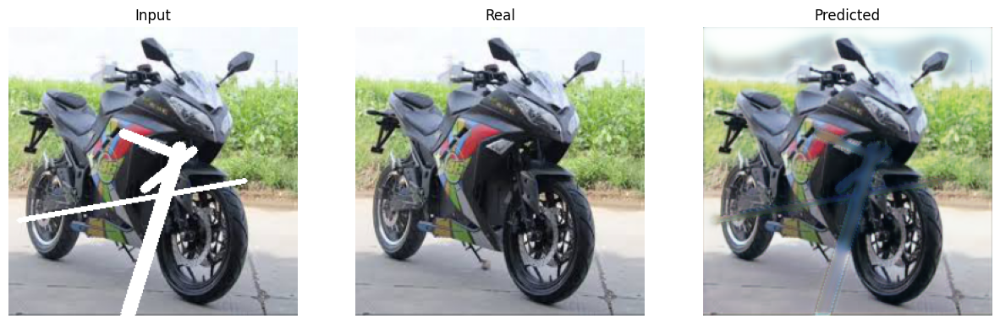

-----------------------------------------------------------
| End of epoch   5 | Time: 42.54s | Train psnr   25.844 | Train Loss    0.070 | Valid psnr   25.054 | Valid Loss    0.062 
-----------------------------------------------------------
| epoch   6 |    50/   86 batches | psnr   25.476


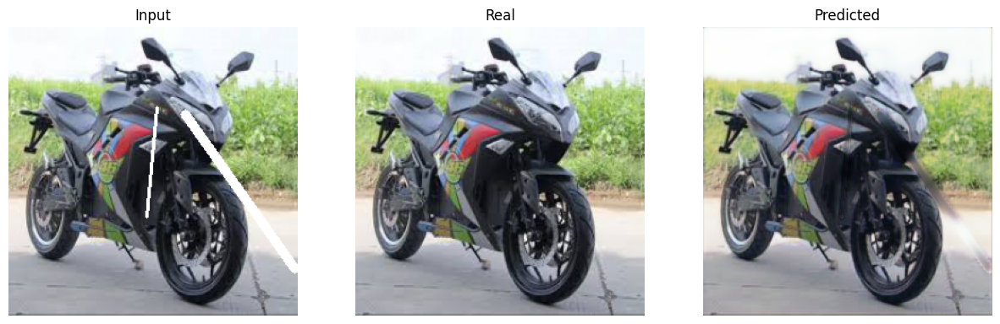

-----------------------------------------------------------
| End of epoch   6 | Time: 42.27s | Train psnr   25.807 | Train Loss    0.070 | Valid psnr   26.030 | Valid Loss    0.051 
-----------------------------------------------------------
| epoch   7 |    50/   86 batches | psnr   25.453
-----------------------------------------------------------
| End of epoch   7 | Time: 42.15s | Train psnr   25.155 | Train Loss    0.071 | Valid psnr   22.649 | Valid Loss    0.077 
-----------------------------------------------------------
| epoch   8 |    50/   86 batches | psnr   25.859
-----------------------------------------------------------
| End of epoch   8 | Time: 42.08s | Train psnr   25.553 | Train Loss    0.067 | Valid psnr   21.626 | Valid Loss    0.080 
-----------------------------------------------------------
| epoch   9 |    50/   86 batches | psnr   25.725


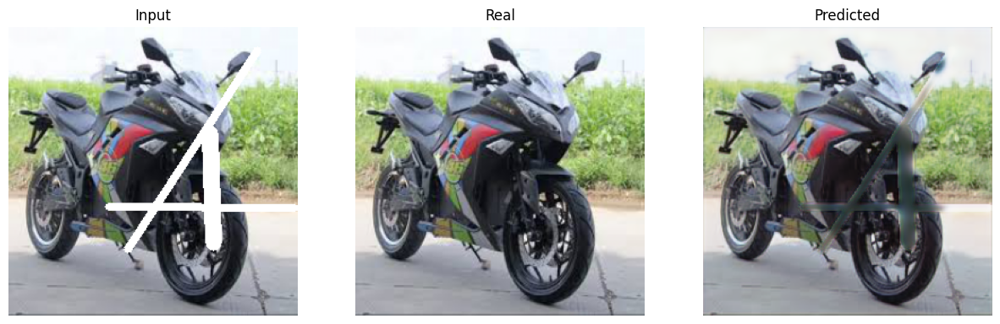

-----------------------------------------------------------
| End of epoch   9 | Time: 43.57s | Train psnr   26.397 | Train Loss    0.065 | Valid psnr   27.483 | Valid Loss    0.048 
-----------------------------------------------------------
| epoch  10 |    50/   86 batches | psnr   26.606
-----------------------------------------------------------
| End of epoch  10 | Time: 42.15s | Train psnr   26.691 | Train Loss    0.060 | Valid psnr   27.348 | Valid Loss    0.045 
-----------------------------------------------------------
| epoch  11 |    50/   86 batches | psnr   26.773


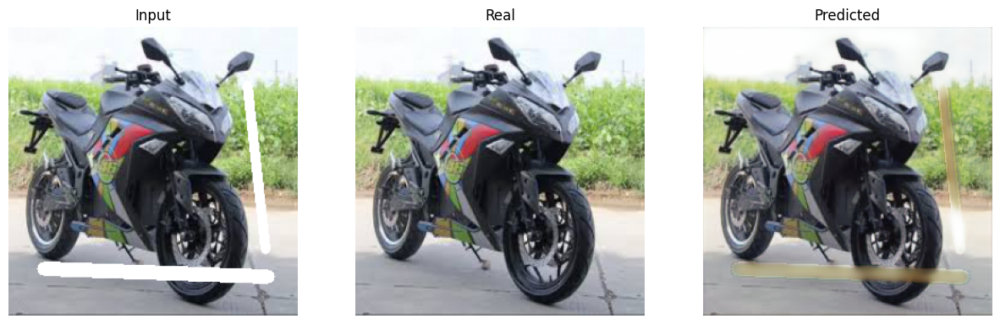

-----------------------------------------------------------
| End of epoch  11 | Time: 43.24s | Train psnr   26.974 | Train Loss    0.059 | Valid psnr   27.486 | Valid Loss    0.044 
-----------------------------------------------------------
| epoch  12 |    50/   86 batches | psnr   26.789
-----------------------------------------------------------
| End of epoch  12 | Time: 41.98s | Train psnr   26.607 | Train Loss    0.058 | Valid psnr   27.203 | Valid Loss    0.041 
-----------------------------------------------------------
| epoch  13 |    50/   86 batches | psnr   27.274
-----------------------------------------------------------
| End of epoch  13 | Time: 45.68s | Train psnr   27.235 | Train Loss    0.054 | Valid psnr   26.658 | Valid Loss    0.047 
-----------------------------------------------------------
| epoch  14 |    50/   86 batches | psnr   27.219
-----------------------------------------------------------
| End of epoch  14 | Time: 44.44s | Train psnr   27.138 | Tra

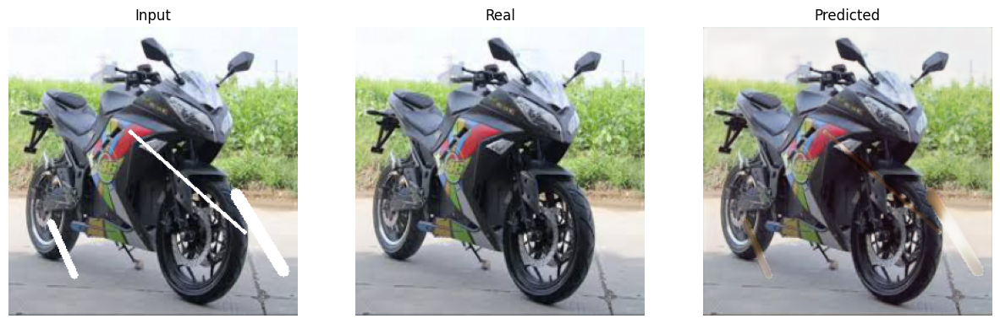

-----------------------------------------------------------
| End of epoch  16 | Time: 43.71s | Train psnr   27.319 | Train Loss    0.052 | Valid psnr   27.616 | Valid Loss    0.043 
-----------------------------------------------------------
| epoch  17 |    50/   86 batches | psnr   27.687


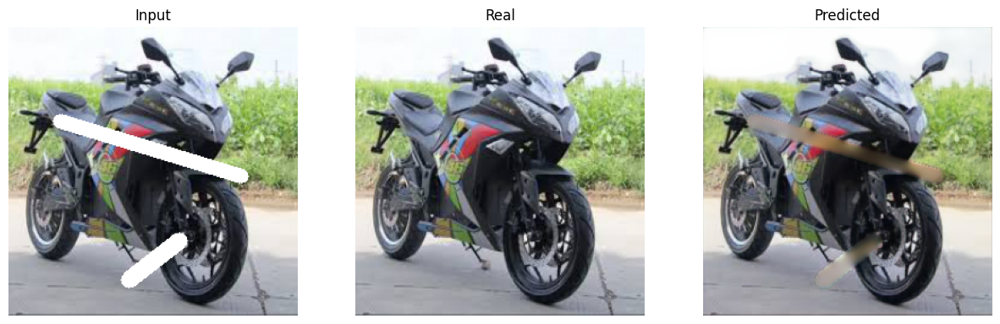

-----------------------------------------------------------
| End of epoch  17 | Time: 42.54s | Train psnr   27.448 | Train Loss    0.053 | Valid psnr   28.139 | Valid Loss    0.040 
-----------------------------------------------------------
| epoch  18 |    50/   86 batches | psnr   27.828


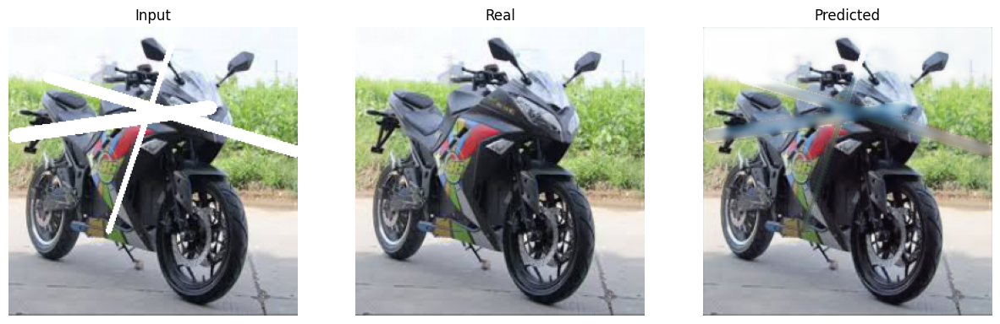

-----------------------------------------------------------
| End of epoch  18 | Time: 46.35s | Train psnr   27.924 | Train Loss    0.049 | Valid psnr   28.685 | Valid Loss    0.035 
-----------------------------------------------------------
| epoch  19 |    50/   86 batches | psnr   27.947
-----------------------------------------------------------
| End of epoch  19 | Time: 42.56s | Train psnr   27.671 | Train Loss    0.049 | Valid psnr   26.947 | Valid Loss    0.050 
-----------------------------------------------------------
| epoch  20 |    50/   86 batches | psnr   28.031


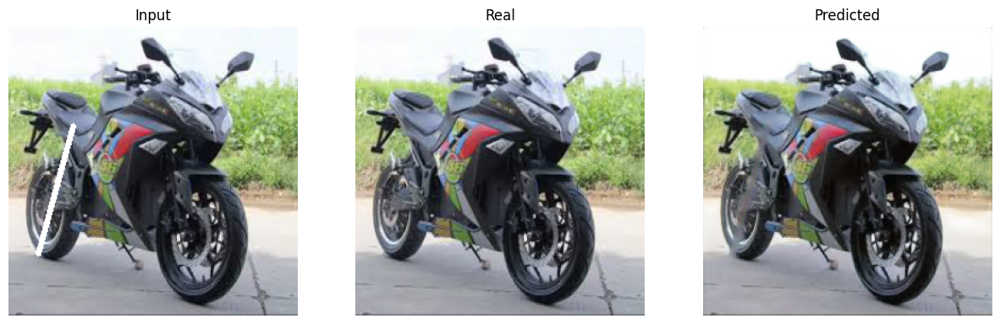

-----------------------------------------------------------
| End of epoch  20 | Time: 42.95s | Train psnr   28.030 | Train Loss    0.047 | Valid psnr   28.728 | Valid Loss    0.039 
-----------------------------------------------------------
| epoch  21 |    50/   86 batches | psnr   27.777
-----------------------------------------------------------
| End of epoch  21 | Time: 43.31s | Train psnr   28.123 | Train Loss    0.047 | Valid psnr   25.563 | Valid Loss    0.043 
-----------------------------------------------------------
| epoch  22 |    50/   86 batches | psnr   27.568


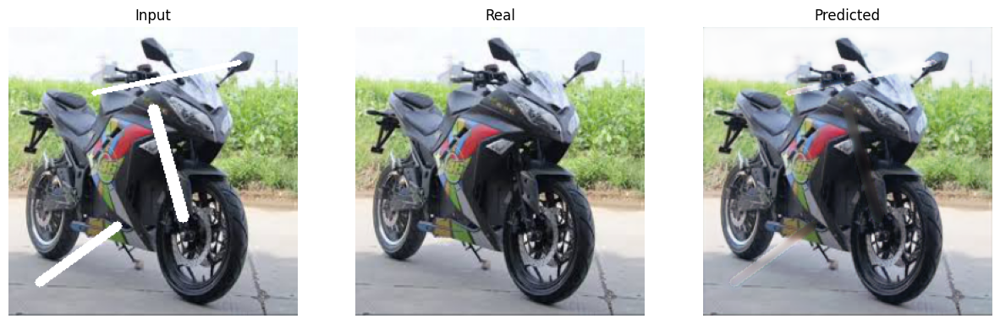

-----------------------------------------------------------
| End of epoch  22 | Time: 43.11s | Train psnr   28.017 | Train Loss    0.050 | Valid psnr   29.111 | Valid Loss    0.035 
-----------------------------------------------------------
| epoch  23 |    50/   86 batches | psnr   27.868


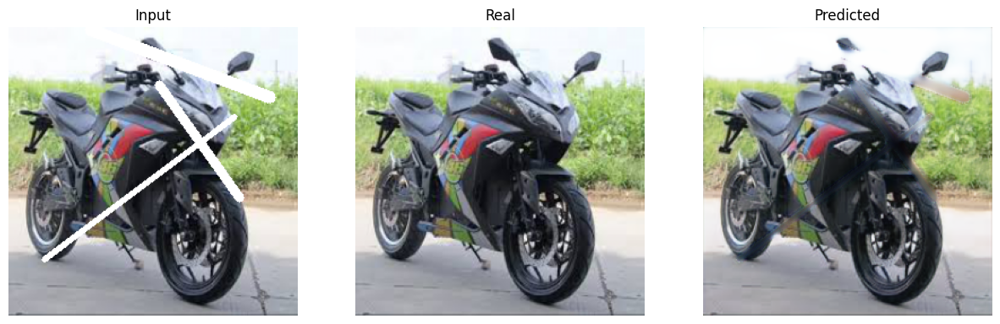

-----------------------------------------------------------
| End of epoch  23 | Time: 43.26s | Train psnr   28.104 | Train Loss    0.047 | Valid psnr   29.420 | Valid Loss    0.031 
-----------------------------------------------------------
| epoch  24 |    50/   86 batches | psnr   28.313
-----------------------------------------------------------
| End of epoch  24 | Time: 43.26s | Train psnr   28.070 | Train Loss    0.047 | Valid psnr   29.146 | Valid Loss    0.037 
-----------------------------------------------------------
| epoch  25 |    50/   86 batches | psnr   28.327
-----------------------------------------------------------
| End of epoch  25 | Time: 43.27s | Train psnr   27.929 | Train Loss    0.046 | Valid psnr   26.282 | Valid Loss    0.044 
-----------------------------------------------------------
| epoch  26 |    50/   86 batches | psnr   28.340


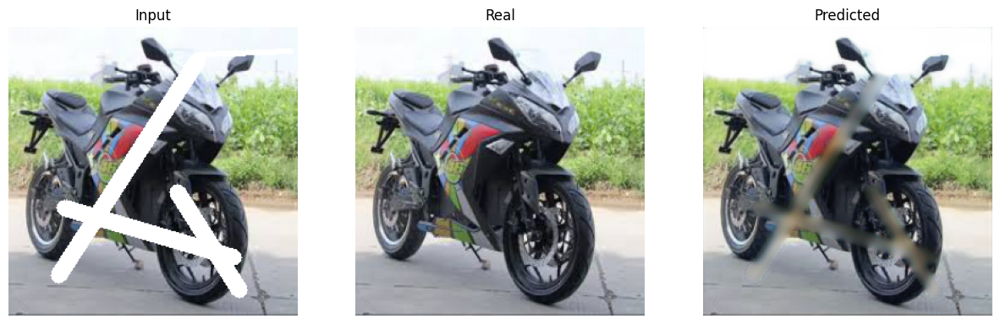

-----------------------------------------------------------
| End of epoch  26 | Time: 42.43s | Train psnr   28.465 | Train Loss    0.045 | Valid psnr   29.553 | Valid Loss    0.033 
-----------------------------------------------------------
| epoch  27 |    50/   86 batches | psnr   28.630
-----------------------------------------------------------
| End of epoch  27 | Time: 42.59s | Train psnr   28.585 | Train Loss    0.044 | Valid psnr   27.811 | Valid Loss    0.040 
-----------------------------------------------------------
| epoch  28 |    50/   86 batches | psnr   28.309
-----------------------------------------------------------
| End of epoch  28 | Time: 42.78s | Train psnr   28.595 | Train Loss    0.045 | Valid psnr   28.634 | Valid Loss    0.033 
-----------------------------------------------------------
| epoch  29 |    50/   86 batches | psnr   28.457
-----------------------------------------------------------
| End of epoch  29 | Time: 42.33s | Train psnr   29.075 | Tra

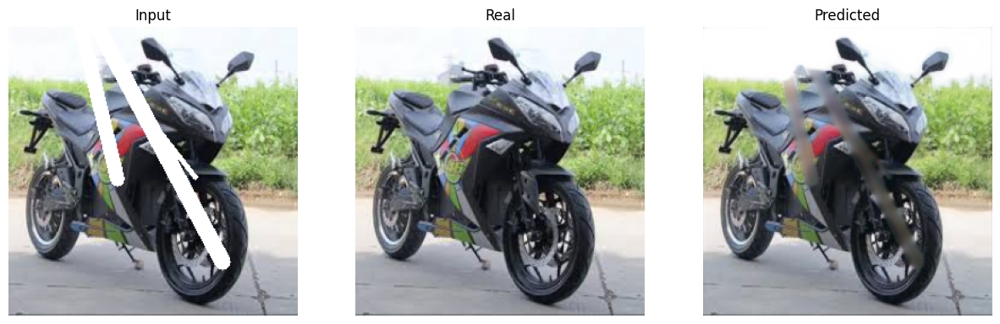

-----------------------------------------------------------
| End of epoch  31 | Time: 42.75s | Train psnr   28.682 | Train Loss    0.042 | Valid psnr   29.811 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch  32 |    50/   86 batches | psnr   28.881
-----------------------------------------------------------
| End of epoch  32 | Time: 43.07s | Train psnr   28.347 | Train Loss    0.042 | Valid psnr   28.288 | Valid Loss    0.042 
-----------------------------------------------------------
| epoch  33 |    50/   86 batches | psnr   28.506
-----------------------------------------------------------
| End of epoch  33 | Time: 42.01s | Train psnr   28.272 | Train Loss    0.044 | Valid psnr   29.375 | Valid Loss    0.035 
-----------------------------------------------------------
| epoch  34 |    50/   86 batches | psnr   28.558
-----------------------------------------------------------
| End of epoch  34 | Time: 42.10s | Train psnr   28.562 | Tra

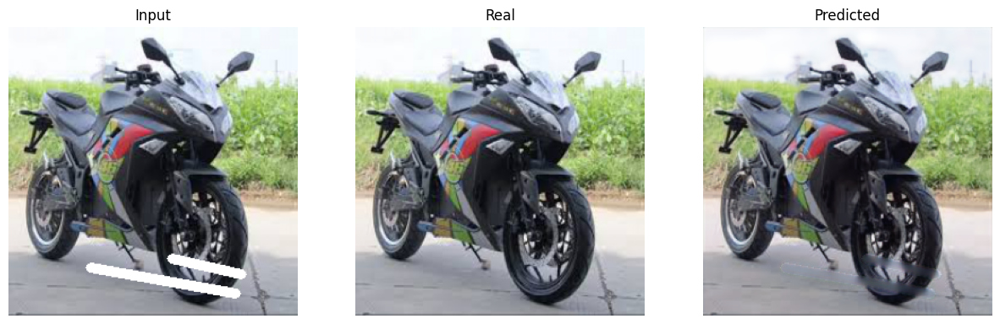

-----------------------------------------------------------
| End of epoch  46 | Time: 42.52s | Train psnr   29.414 | Train Loss    0.038 | Valid psnr   29.949 | Valid Loss    0.034 
-----------------------------------------------------------
| epoch  47 |    50/   86 batches | psnr   29.324
-----------------------------------------------------------
| End of epoch  47 | Time: 41.96s | Train psnr   29.471 | Train Loss    0.038 | Valid psnr   22.725 | Valid Loss    0.050 
-----------------------------------------------------------
| epoch  48 |    50/   86 batches | psnr   29.413
-----------------------------------------------------------
| End of epoch  48 | Time: 42.97s | Train psnr   29.318 | Train Loss    0.037 | Valid psnr   27.906 | Valid Loss    0.039 
-----------------------------------------------------------
| epoch  49 |    50/   86 batches | psnr   29.363
-----------------------------------------------------------
| End of epoch  49 | Time: 43.65s | Train psnr   28.833 | Tra

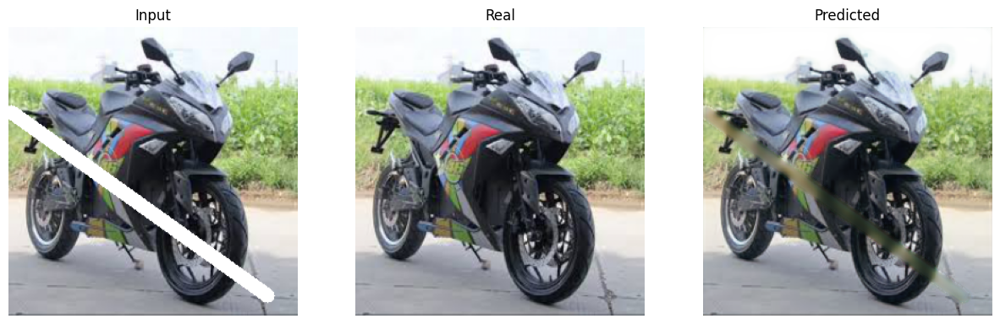

-----------------------------------------------------------
| End of epoch  50 | Time: 43.06s | Train psnr   29.175 | Train Loss    0.037 | Valid psnr   30.448 | Valid Loss    0.029 
-----------------------------------------------------------
| epoch  51 |    50/   86 batches | psnr   27.566
-----------------------------------------------------------
| End of epoch  51 | Time: 43.06s | Train psnr   26.433 | Train Loss    0.050 | Valid psnr   26.670 | Valid Loss    0.036 
-----------------------------------------------------------
| epoch  52 |    50/   86 batches | psnr   28.594
-----------------------------------------------------------
| End of epoch  52 | Time: 43.48s | Train psnr   28.601 | Train Loss    0.041 | Valid psnr   29.641 | Valid Loss    0.031 
-----------------------------------------------------------
| epoch  53 |    50/   86 batches | psnr   28.406
-----------------------------------------------------------
| End of epoch  53 | Time: 44.41s | Train psnr   29.056 | Tra

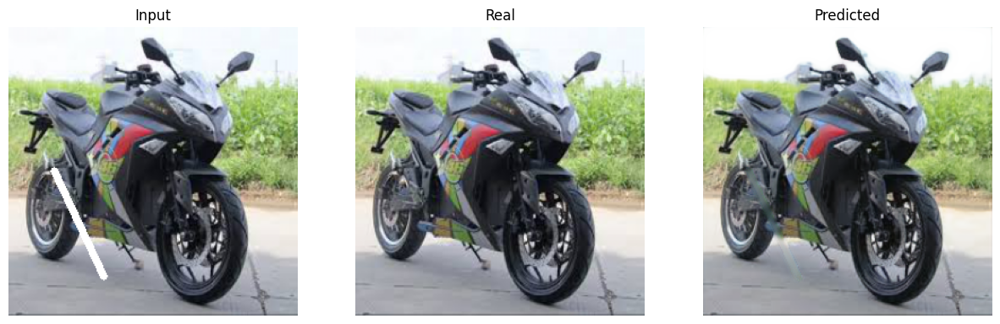

-----------------------------------------------------------
| End of epoch  59 | Time: 43.21s | Train psnr   29.422 | Train Loss    0.035 | Valid psnr   30.486 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch  60 |    50/   86 batches | psnr   29.458
-----------------------------------------------------------
| End of epoch  60 | Time: 42.82s | Train psnr   29.905 | Train Loss    0.036 | Valid psnr   28.849 | Valid Loss    0.029 
-----------------------------------------------------------
| epoch  61 |    50/   86 batches | psnr   29.657
-----------------------------------------------------------
| End of epoch  61 | Time: 41.47s | Train psnr   29.857 | Train Loss    0.035 | Valid psnr   29.872 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  62 |    50/   86 batches | psnr   29.730
-----------------------------------------------------------
| End of epoch  62 | Time: 41.96s | Train psnr   30.249 | Tra

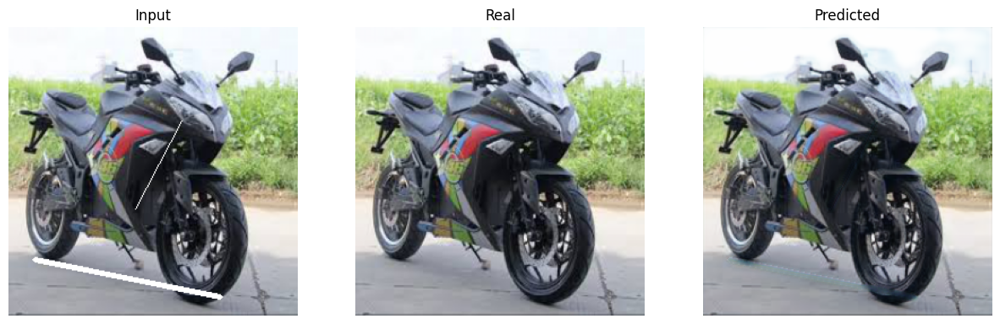

-----------------------------------------------------------
| End of epoch  63 | Time: 43.04s | Train psnr   29.898 | Train Loss    0.034 | Valid psnr   30.652 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  64 |    50/   86 batches | psnr   29.805
-----------------------------------------------------------
| End of epoch  64 | Time: 41.73s | Train psnr   29.592 | Train Loss    0.036 | Valid psnr   21.060 | Valid Loss    0.073 
-----------------------------------------------------------
| epoch  65 |    50/   86 batches | psnr   29.358
-----------------------------------------------------------
| End of epoch  65 | Time: 42.67s | Train psnr   29.994 | Train Loss    0.036 | Valid psnr   30.542 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch  66 |    50/   86 batches | psnr   29.997


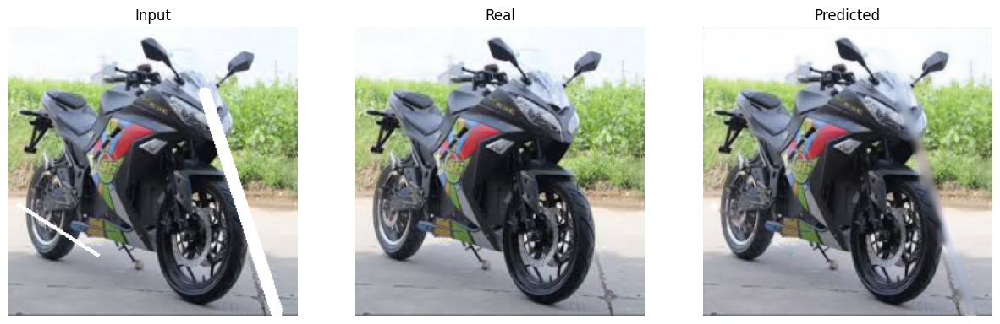

-----------------------------------------------------------
| End of epoch  66 | Time: 44.62s | Train psnr   30.360 | Train Loss    0.034 | Valid psnr   30.945 | Valid Loss    0.024 
-----------------------------------------------------------
| epoch  67 |    50/   86 batches | psnr   29.947
-----------------------------------------------------------
| End of epoch  67 | Time: 43.39s | Train psnr   29.445 | Train Loss    0.035 | Valid psnr   29.055 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch  68 |    50/   86 batches | psnr   29.828
-----------------------------------------------------------
| End of epoch  68 | Time: 43.42s | Train psnr   27.890 | Train Loss    0.040 | Valid psnr   12.671 | Valid Loss    0.209 
-----------------------------------------------------------
| epoch  69 |    50/   86 batches | psnr   27.087
-----------------------------------------------------------
| End of epoch  69 | Time: 43.64s | Train psnr   28.589 | Tra

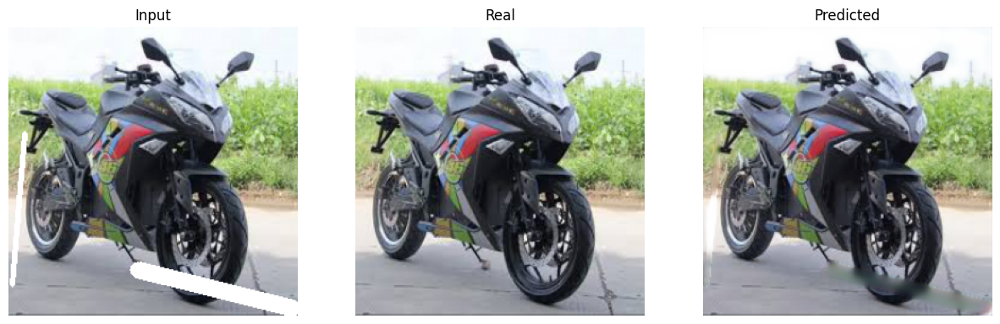

-----------------------------------------------------------
| End of epoch  78 | Time: 43.32s | Train psnr   30.115 | Train Loss    0.033 | Valid psnr   31.028 | Valid Loss    0.026 
-----------------------------------------------------------
| epoch  79 |    50/   86 batches | psnr   30.115
-----------------------------------------------------------
| End of epoch  79 | Time: 43.32s | Train psnr   30.614 | Train Loss    0.032 | Valid psnr   30.673 | Valid Loss    0.026 
-----------------------------------------------------------
| epoch  80 |    50/   86 batches | psnr   29.577
-----------------------------------------------------------
| End of epoch  80 | Time: 43.05s | Train psnr   30.363 | Train Loss    0.033 | Valid psnr   30.063 | Valid Loss    0.028 
-----------------------------------------------------------
| epoch  81 |    50/   86 batches | psnr   30.241
-----------------------------------------------------------
| End of epoch  81 | Time: 43.06s | Train psnr   30.291 | Tra

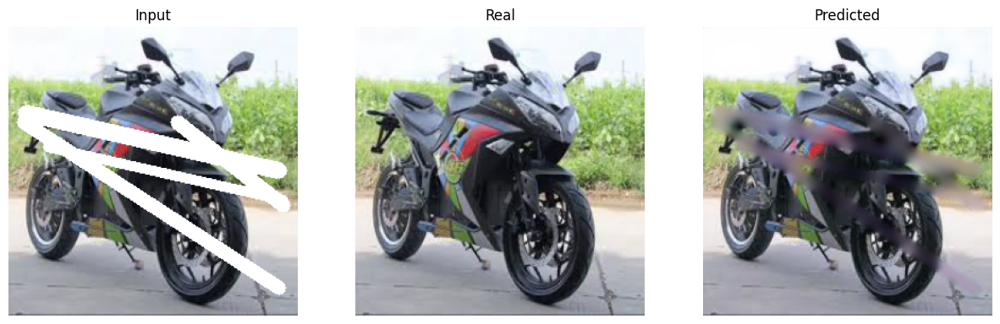

-----------------------------------------------------------
| End of epoch  85 | Time: 33.65s | Train psnr   30.155 | Train Loss    0.031 | Valid psnr   31.122 | Valid Loss    0.025 
-----------------------------------------------------------
| epoch  86 |    50/   86 batches | psnr   30.295
-----------------------------------------------------------
| End of epoch  86 | Time: 27.70s | Train psnr   30.472 | Train Loss    0.032 | Valid psnr   30.972 | Valid Loss    0.026 
-----------------------------------------------------------
| epoch  87 |    50/   86 batches | psnr   29.933
-----------------------------------------------------------
| End of epoch  87 | Time: 27.44s | Train psnr   30.330 | Train Loss    0.032 | Valid psnr   30.345 | Valid Loss    0.026 
-----------------------------------------------------------
| epoch  88 |    50/   86 batches | psnr   30.421
-----------------------------------------------------------
| End of epoch  88 | Time: 27.69s | Train psnr   30.298 | Tra

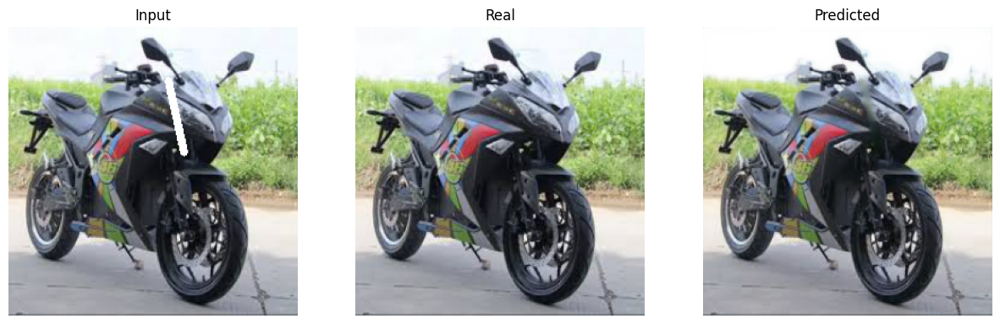

-----------------------------------------------------------
| End of epoch  95 | Time: 27.90s | Train psnr   30.525 | Train Loss    0.031 | Valid psnr   31.330 | Valid Loss    0.026 
-----------------------------------------------------------
| epoch  96 |    50/   86 batches | psnr   30.752
-----------------------------------------------------------
| End of epoch  96 | Time: 27.49s | Train psnr   30.360 | Train Loss    0.030 | Valid psnr   31.182 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  97 |    50/   86 batches | psnr   30.483
-----------------------------------------------------------
| End of epoch  97 | Time: 27.08s | Train psnr   30.105 | Train Loss    0.031 | Valid psnr   29.930 | Valid Loss    0.033 
-----------------------------------------------------------
| epoch  98 |    50/   86 batches | psnr   30.394
-----------------------------------------------------------
| End of epoch  98 | Time: 27.52s | Train psnr   30.702 | Tra

In [ ]:
import torch.optim as optim

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IP_unet_model = II_Unet().to(device)
IP_unet_model.to(device)

criterion = nn.L1Loss()

optimizer = optim.Adam(IP_unet_model.parameters(), lr=1e-4, betas=[0.5,0.999])

save_model = './UNET'
os.makedirs(save_model, exist_ok = True)

EPOCHS = 100
IP_unet_model, metrics = train(
    IP_unet_model, 'IP_unet_model', save_model, optimizer, criterion, train_loader, test_loader, EPOCHS, device
)

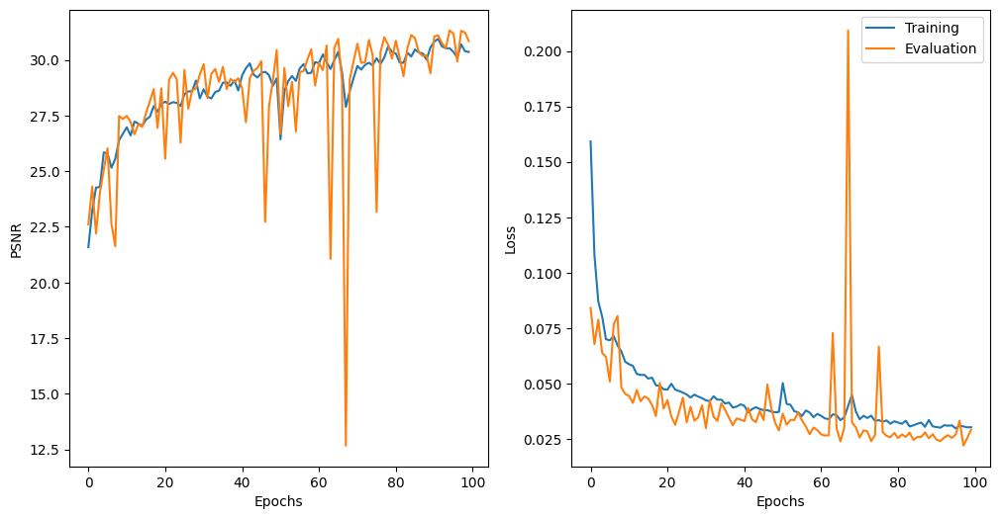

In [ ]:
plot_result(
    EPOCHS,
    metrics["train_psnr"],
    metrics["valid_psnr"],
    metrics["train_loss"],
    metrics["valid_loss"]
)

In [ ]:
test_psnr, test_loss = evaluate_epoch(IP_unet_model, criterion, test_loader, device)
test_psnr, test_loss

(tensor(31.1508, device='cuda:0'), 0.02584496411410245)

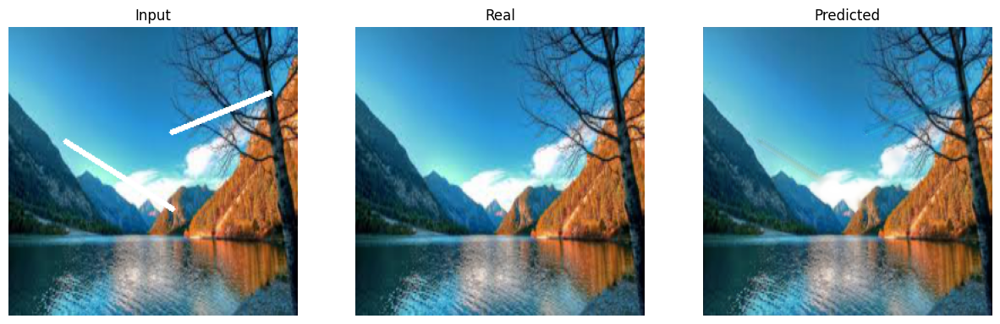

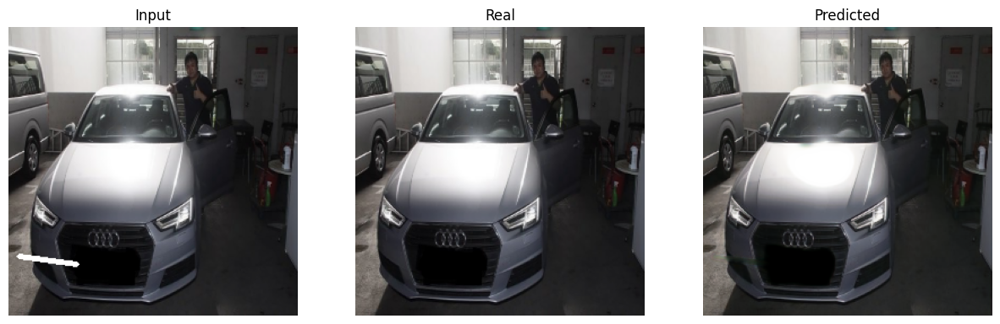

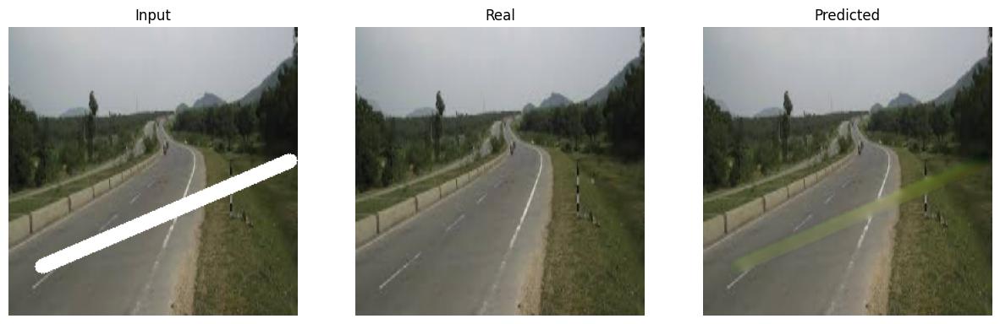

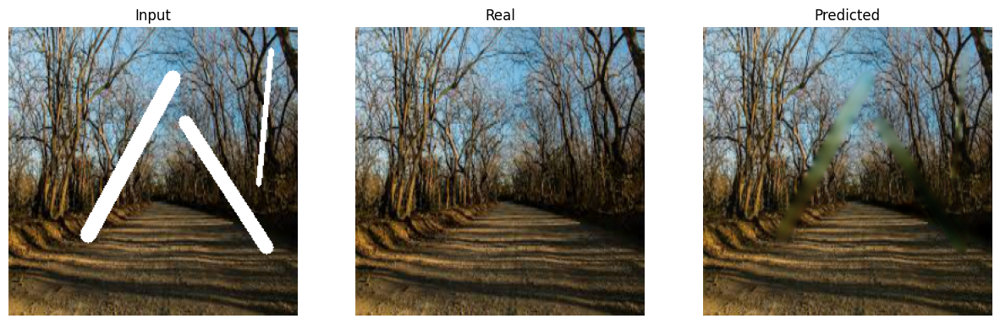

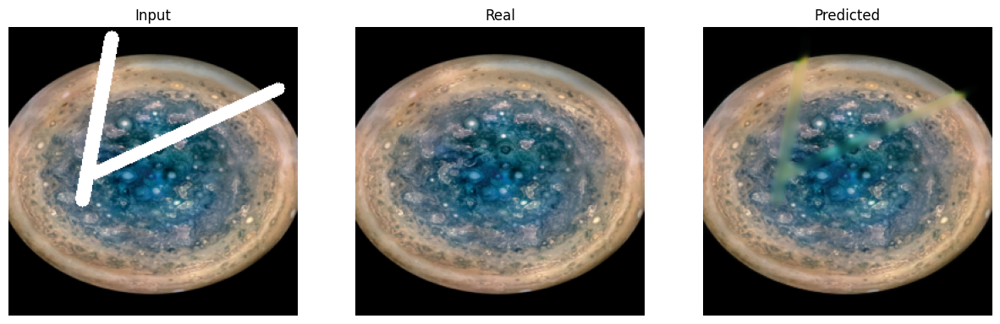

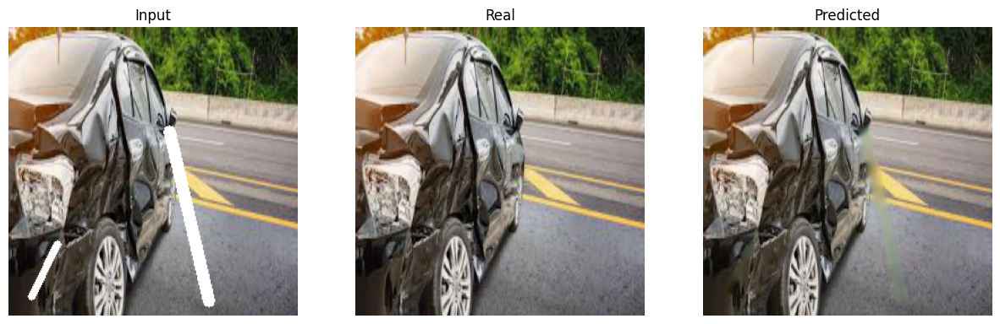

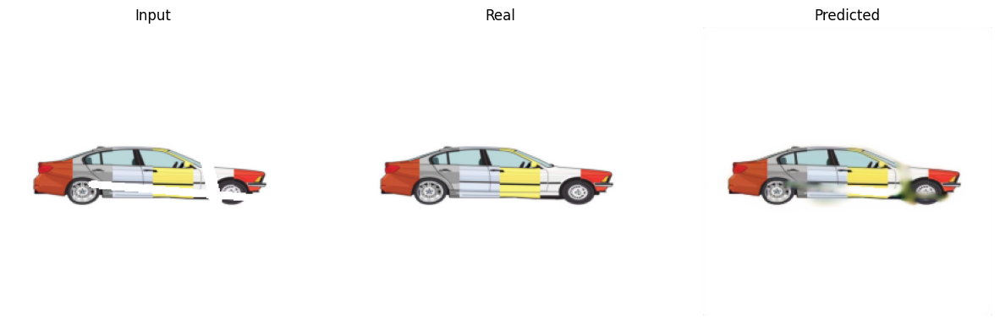

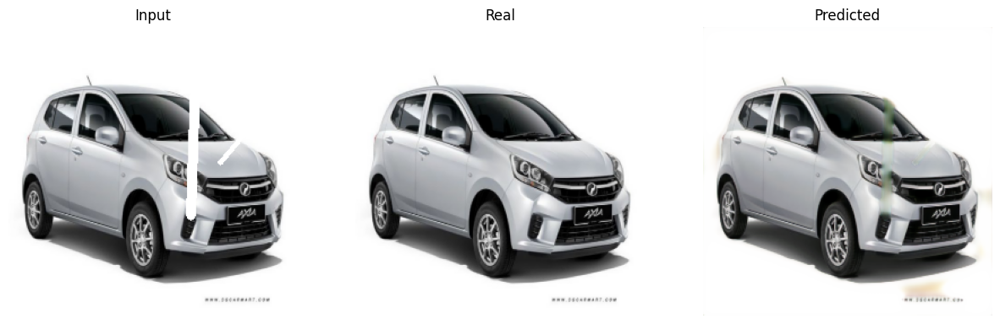

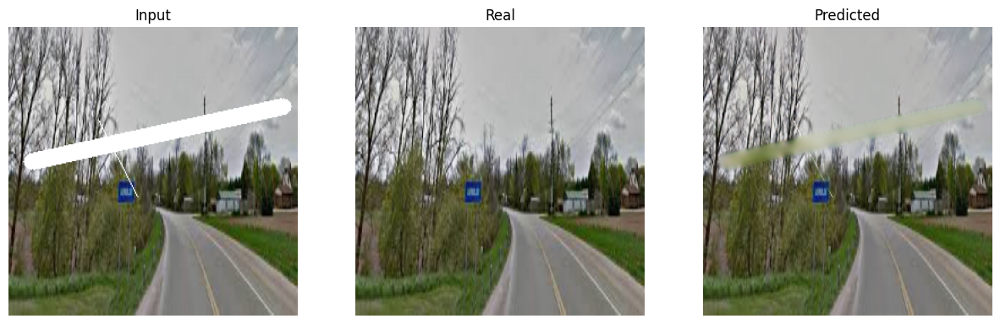

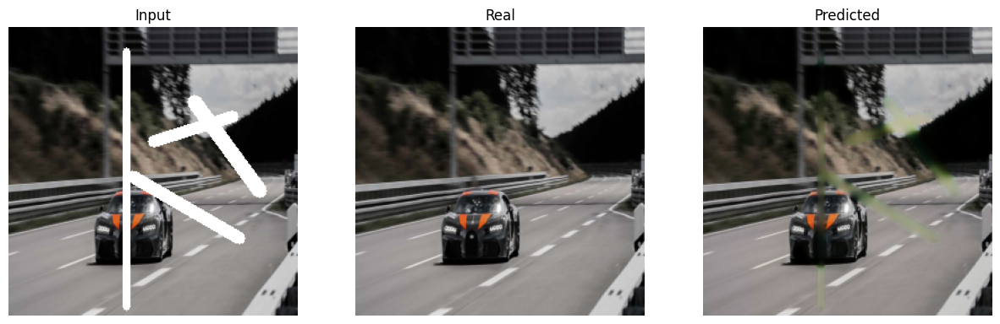

In [ ]:
predict_and_display(IP_unet_model, train_loader, device)

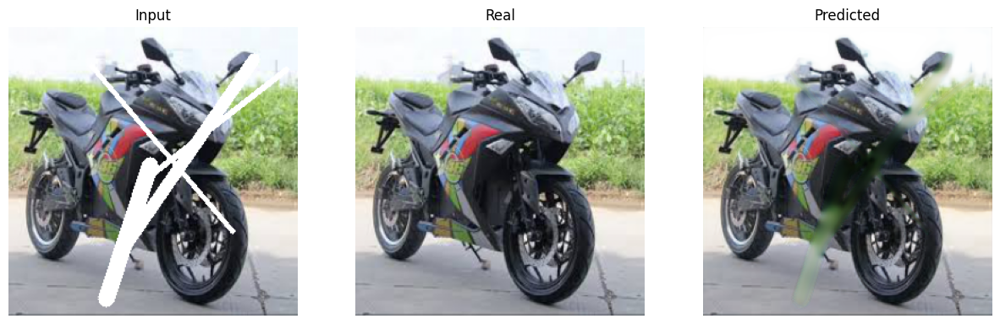

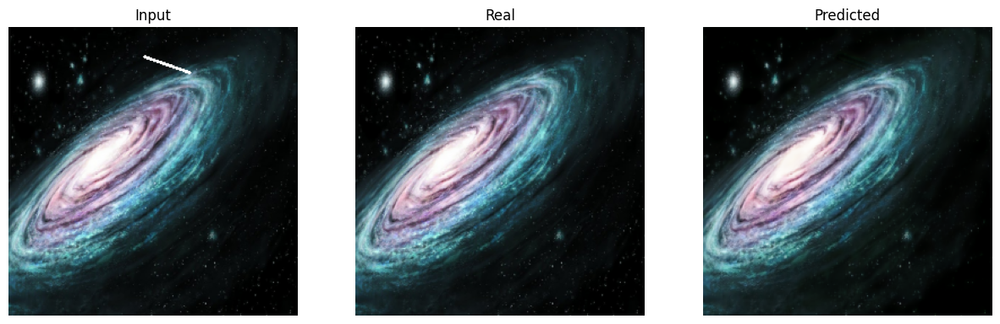

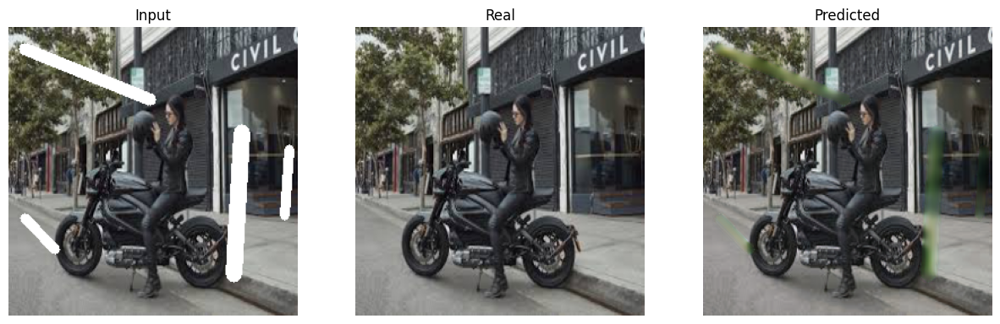

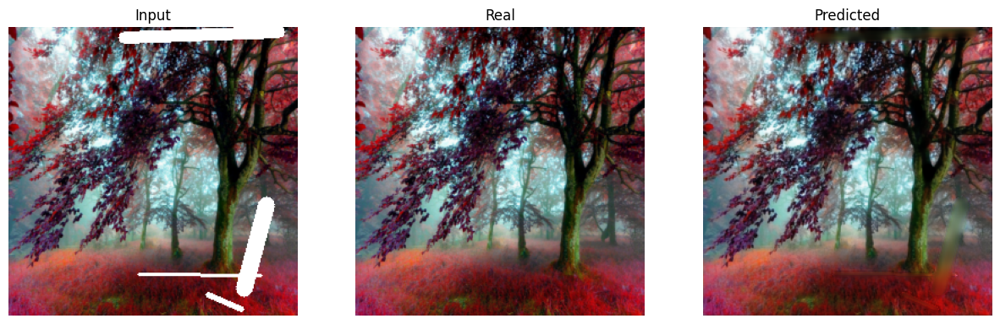

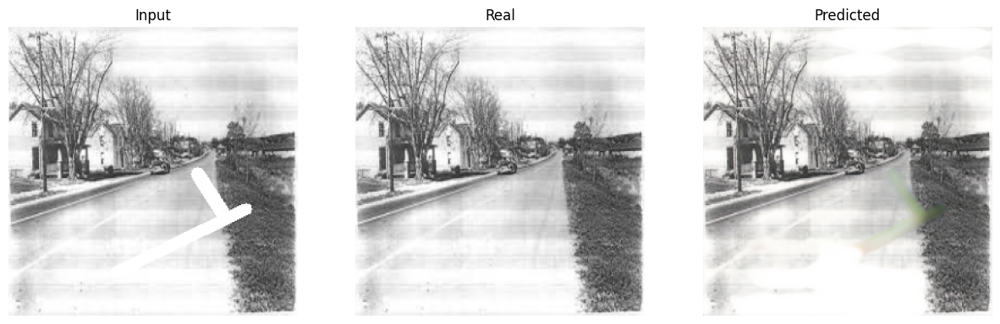

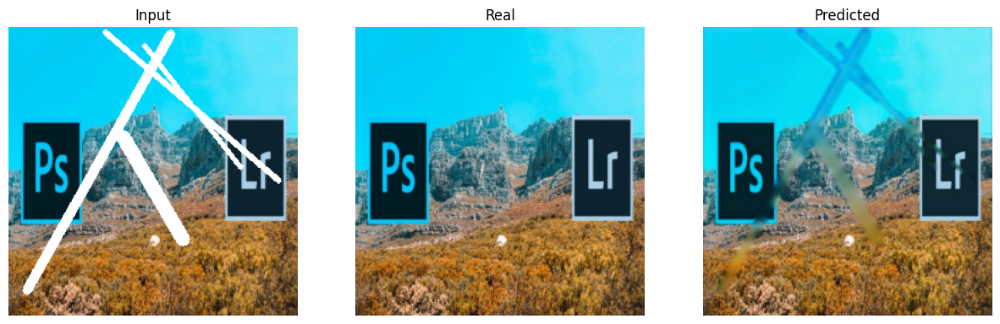

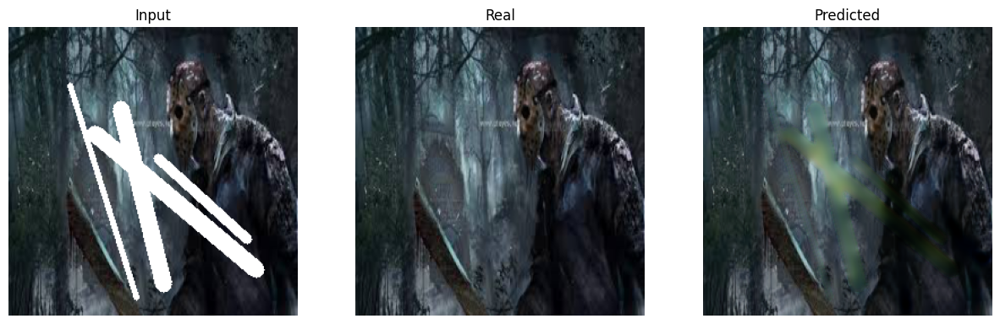

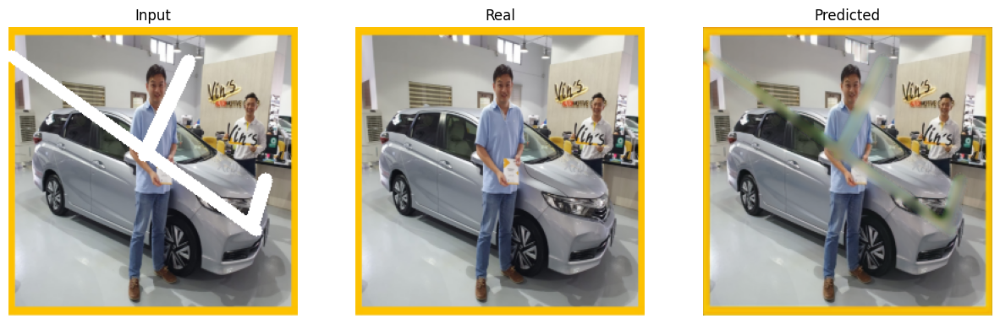

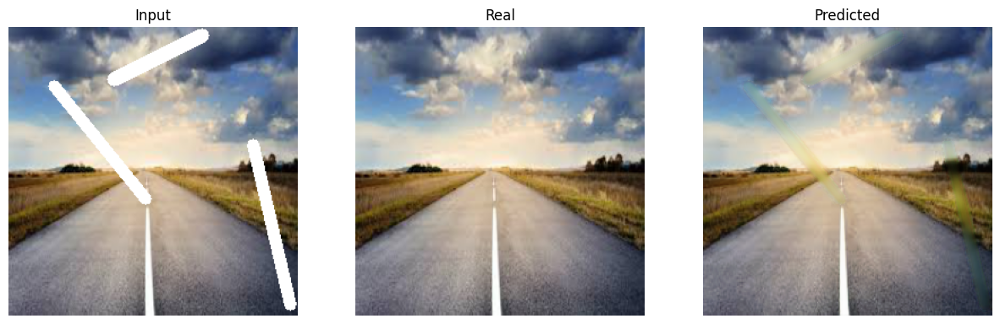

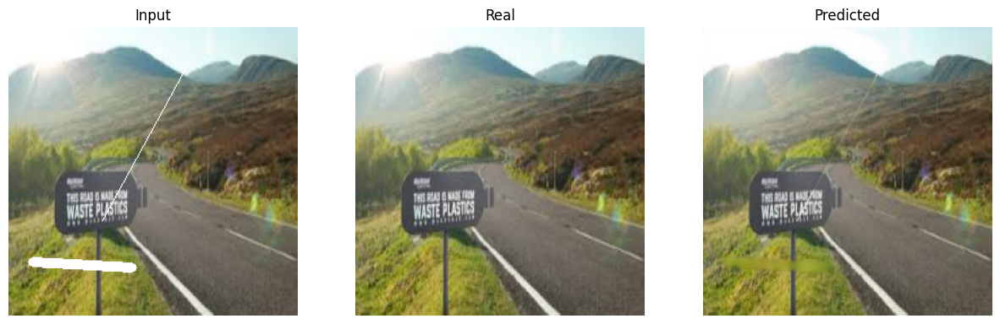

In [ ]:
predict_and_display(IP_unet_model, test_loader, device)

#### Unet Pretrained

In [ ]:
LHR_TRAIN_DATA_PATH = './Khoa_LHR_image/train'
LHR_VAL_DATA_PATH = './Khoa_LHR_image/val'
BATCH_SIZE = 8
IMG_HEIGHT = 256
IMG_WIDTH = 256

In [ ]:
class ImageDataset(Dataset):
    def __init__(self, img_dir, is_train=True, is_phase1=False):
        self.is_phase1 = is_phase1
        self.is_train = is_train
        self.img_dir = img_dir
        self.images = os.listdir(img_dir)

    def __len__(self):
        return len(self.images)

    def normalize(self, input_image, target_image):
        input_image  = input_image*2 - 1
        target_image = target_image*2 - 1

        return input_image, target_image

    def random_jitter(self, input_image, target_image):
        if torch.rand([]) < 0.5:
            input_image = transforms.functional.hflip(input_image)
            target_image = transforms.functional.hflip(target_image)

        return input_image, target_image

    def create_mask(self, image):
        masked_image = image.copy()
        ## Prepare masking matrix
        mask = np.full((IMG_WIDTH,IMG_HEIGHT,3), 0, np.uint8)
        for _ in range(np.random.randint(1, 5)):
            # Get random x locations to start line
            x1, x2 = np.random.randint(1, IMG_WIDTH), np.random.randint(1, IMG_WIDTH)
            # Get random y locations to start line
            y1, y2 = np.random.randint(1, IMG_HEIGHT), np.random.randint(1, IMG_HEIGHT)
            # Get random thickness of the line drawn
            thickness = np.random.randint(1, 15)
            # Draw line on the black mask
            cv2.line(mask,(x1,y1),(x2,y2),(1,1,1),thickness)

        masked_image = np.where(mask, 255*np.ones_like(mask), masked_image)
        return masked_image

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.images[idx])
        image = np.array(Image.open(img_path).convert("RGB"))

        if self.is_phase1:
            image = transforms.functional.to_tensor(image)
            input_image, target_image = self.normalize(image, image)
            input_image, target_image = input_image.type(torch.float32), target_image.type(torch.float32)
            if self.is_train:
                input_image, target_image = self.random_jitter(input_image, target_image)
            return input_image, target_image

        input_image = self.create_mask(image)
        input_image = transforms.functional.to_tensor(input_image)
        target_image = transforms.functional.to_tensor(image)

        input_image = input_image.type(torch.float32)
        target_image = target_image.type(torch.float32)

        input_image, target_image = self.normalize(input_image, target_image)

        if self.is_train:
            input_image, target_image = self.random_jitter(input_image, target_image)

        return input_image, target_image



In [ ]:
train_dataset_phase1 = ImageDataset(LHR_TRAIN_DATA_PATH, is_train=True, is_phase1=True)
train_loader_phase1 = DataLoader(train_dataset_phase1, batch_size=BATCH_SIZE, shuffle=True)

test_dataset_phase1 = ImageDataset(LHR_VAL_DATA_PATH, is_train=False, is_phase1=True)
test_loader_phase1 = DataLoader(test_dataset_phase1, batch_size=BATCH_SIZE, shuffle=False)

Text(0.5, 1.0, 'Target')

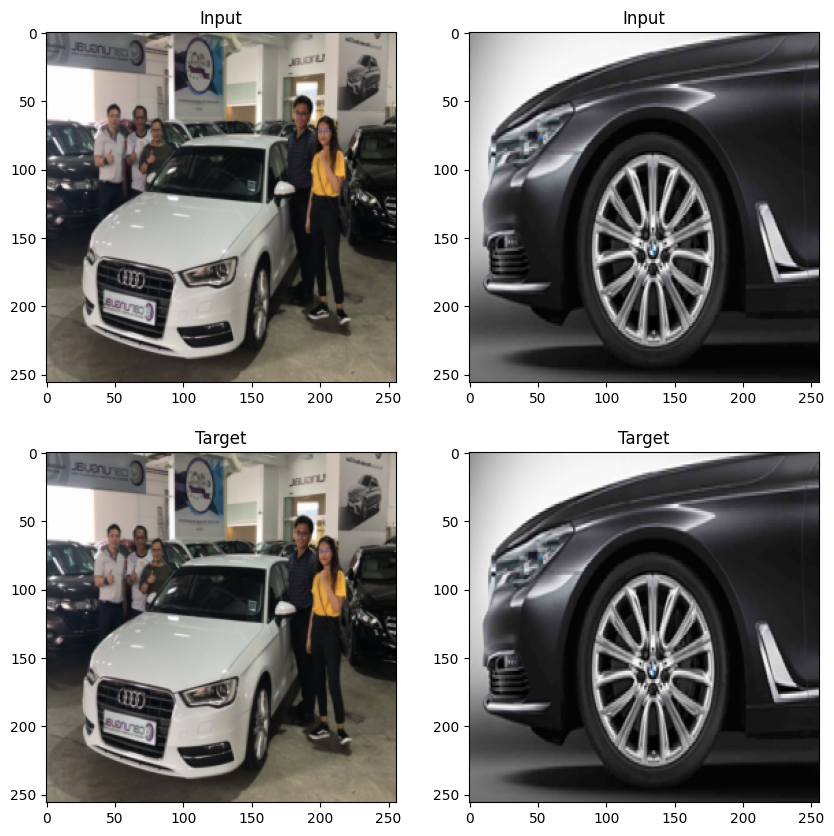

In [ ]:
in_batch, tar_batch = next(iter(train_loader_phase1))
in_batch = (in_batch + 1)/2
tar_batch = (tar_batch + 1)/2

plt.figure(figsize=(10, 10))
ax = plt.subplot(2, 2, 1)
plt.imshow(np.squeeze(in_batch[0].numpy().transpose((1, 2, 0))))
plt.title("Input")
ax = plt.subplot(2, 2, 3)
plt.imshow(np.squeeze(tar_batch[0].numpy().transpose((1, 2, 0))))
plt.title("Target")
ax = plt.subplot(2, 2, 2)
plt.imshow(np.squeeze(in_batch[1].numpy().transpose((1, 2, 0))))
plt.title("Input")
ax = plt.subplot(2, 2, 4)
plt.imshow(np.squeeze(tar_batch[1].numpy().transpose((1, 2, 0))))
plt.title("Target")



In [ ]:
train_dataset = ImageDataset(LHR_TRAIN_DATA_PATH, is_train=True)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

test_dataset = ImageDataset(LHR_VAL_DATA_PATH, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Text(0.5, 1.0, 'Target')

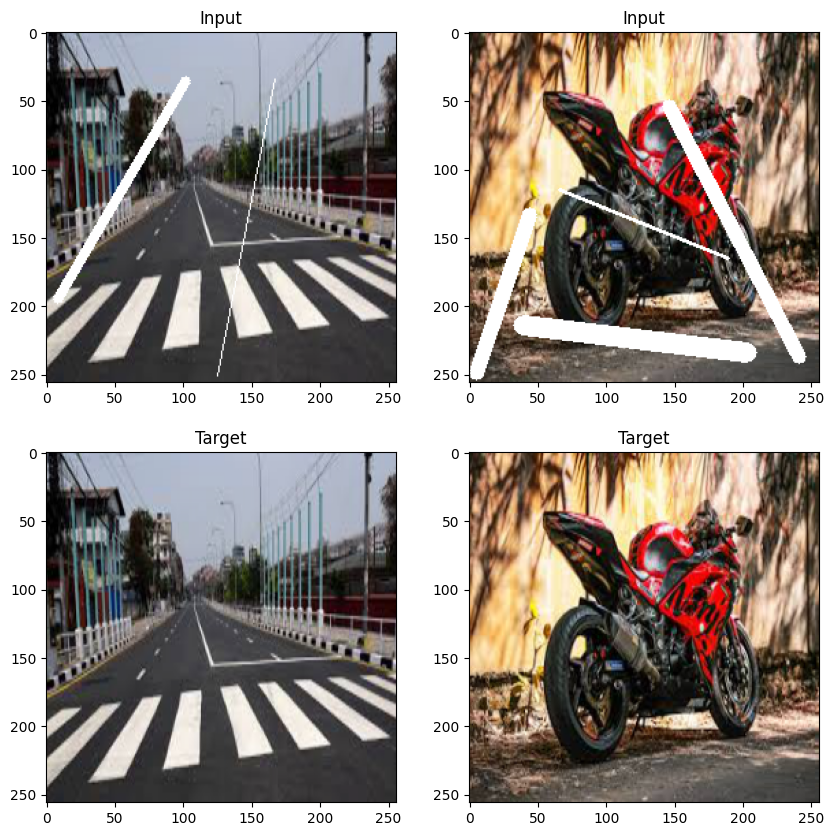

In [ ]:
in_batch, tar_batch = next(iter(train_loader))
in_batch = (in_batch + 1)/2
tar_batch = (tar_batch + 1)/2

plt.figure(figsize=(10, 10))
ax = plt.subplot(2, 2, 1)
plt.imshow(np.squeeze(in_batch[0].numpy().transpose((1, 2, 0))))
plt.title("Input")
ax = plt.subplot(2, 2, 3)
plt.imshow(np.squeeze(tar_batch[0].numpy().transpose((1, 2, 0))))
plt.title("Target")
ax = plt.subplot(2, 2, 2)
plt.imshow(np.squeeze(in_batch[1].numpy().transpose((1, 2, 0))))
plt.title("Input")
ax = plt.subplot(2, 2, 4)
plt.imshow(np.squeeze(tar_batch[1].numpy().transpose((1, 2, 0))))
plt.title("Target")



| epoch   1 |    50/   86 batches | psnr   19.700


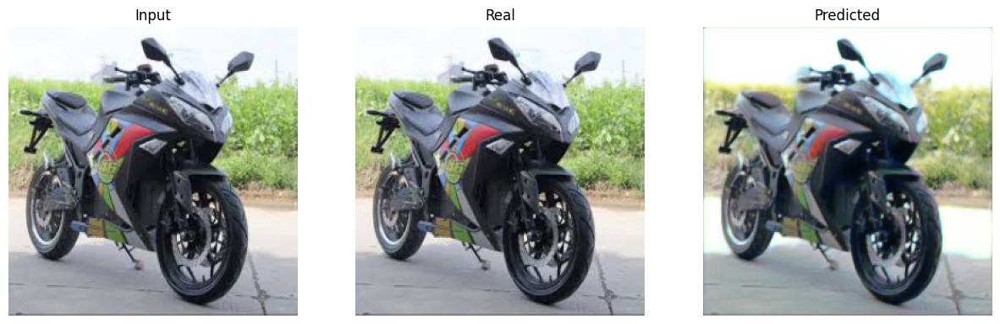

-----------------------------------------------------------
| End of epoch   1 | Time: 28.30s | Train psnr   22.747 | Train Loss    0.146 | Valid psnr   21.260 | Valid Loss    0.117 
-----------------------------------------------------------
| epoch   2 |    50/   86 batches | psnr   24.944


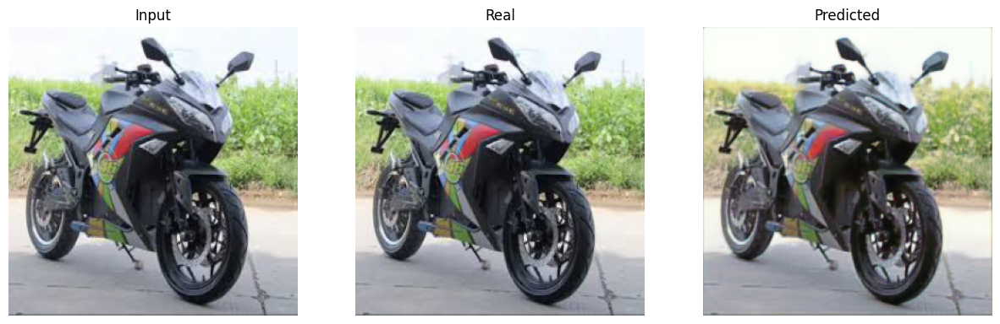

-----------------------------------------------------------
| End of epoch   2 | Time: 28.32s | Train psnr   25.603 | Train Loss    0.084 | Valid psnr   27.005 | Valid Loss    0.061 
-----------------------------------------------------------
| epoch   3 |    50/   86 batches | psnr   26.082


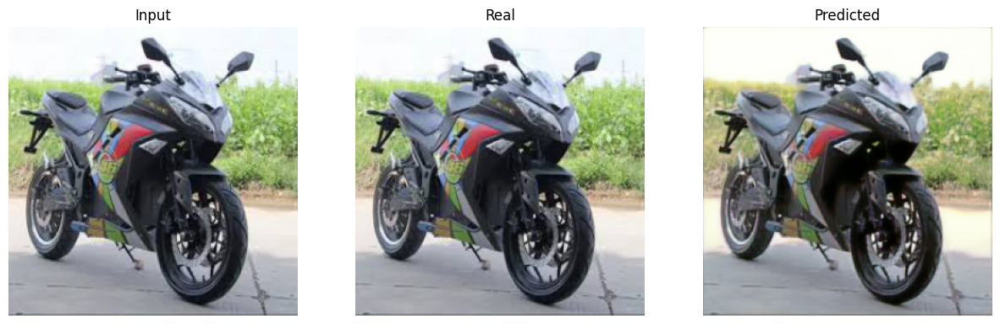

-----------------------------------------------------------
| End of epoch   3 | Time: 19.01s | Train psnr   25.828 | Train Loss    0.078 | Valid psnr   27.517 | Valid Loss    0.058 
-----------------------------------------------------------
| epoch   4 |    50/   86 batches | psnr   26.487


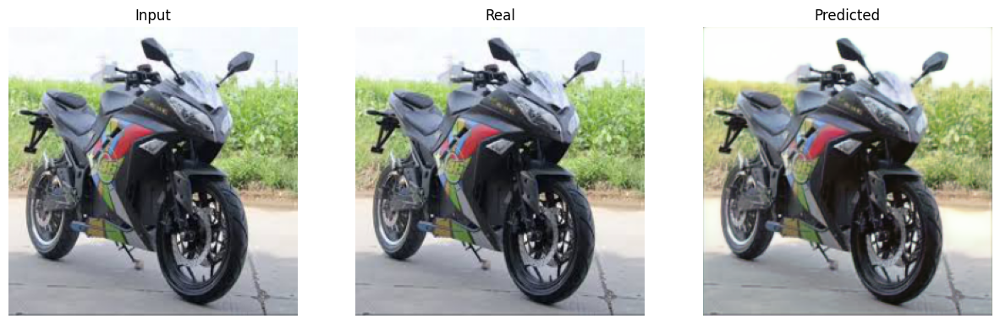

-----------------------------------------------------------
| End of epoch   4 | Time: 18.76s | Train psnr   27.164 | Train Loss    0.071 | Valid psnr   29.596 | Valid Loss    0.046 
-----------------------------------------------------------
| epoch   5 |    50/   86 batches | psnr   27.683


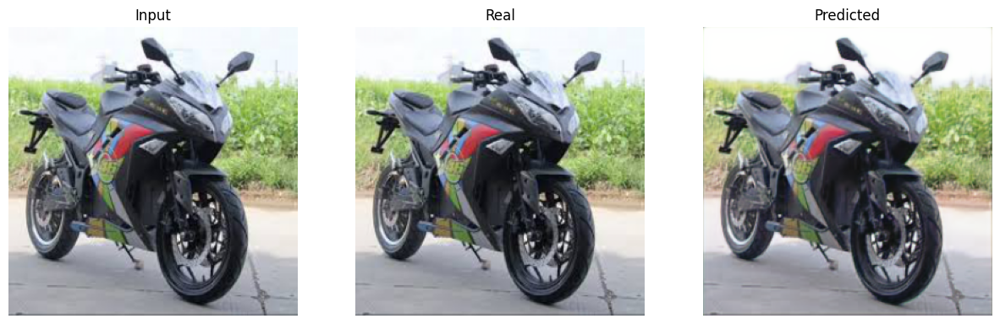

-----------------------------------------------------------
| End of epoch   5 | Time: 28.14s | Train psnr   27.986 | Train Loss    0.062 | Valid psnr   30.459 | Valid Loss    0.043 
-----------------------------------------------------------
| epoch   6 |    50/   86 batches | psnr   27.811
-----------------------------------------------------------
| End of epoch   6 | Time: 27.82s | Train psnr   28.872 | Train Loss    0.061 | Valid psnr   29.628 | Valid Loss    0.045 
-----------------------------------------------------------
| epoch   7 |    50/   86 batches | psnr   28.262
-----------------------------------------------------------
| End of epoch   7 | Time: 27.95s | Train psnr   28.566 | Train Loss    0.059 | Valid psnr   30.353 | Valid Loss    0.045 
-----------------------------------------------------------
| epoch   8 |    50/   86 batches | psnr   28.669
-----------------------------------------------------------
| End of epoch   8 | Time: 27.71s | Train psnr   28.779 | Tra

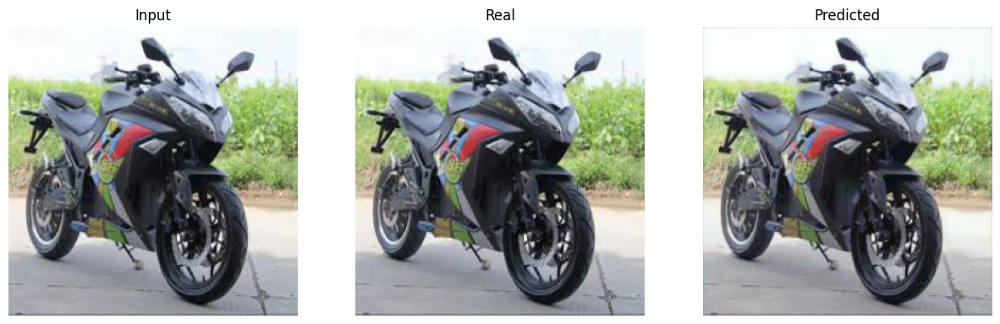

-----------------------------------------------------------
| End of epoch   9 | Time: 28.48s | Train psnr   28.825 | Train Loss    0.055 | Valid psnr   31.839 | Valid Loss    0.036 
-----------------------------------------------------------
| epoch  10 |    50/   86 batches | psnr   29.760
-----------------------------------------------------------
| End of epoch  10 | Time: 27.77s | Train psnr   29.319 | Train Loss    0.051 | Valid psnr   31.305 | Valid Loss    0.035 
-----------------------------------------------------------
| epoch  11 |    50/   86 batches | psnr   29.385
-----------------------------------------------------------
| End of epoch  11 | Time: 27.59s | Train psnr   30.185 | Train Loss    0.051 | Valid psnr   30.580 | Valid Loss    0.044 
-----------------------------------------------------------
| epoch  12 |    50/   86 batches | psnr   30.076
-----------------------------------------------------------
| End of epoch  12 | Time: 27.89s | Train psnr   30.162 | Tra

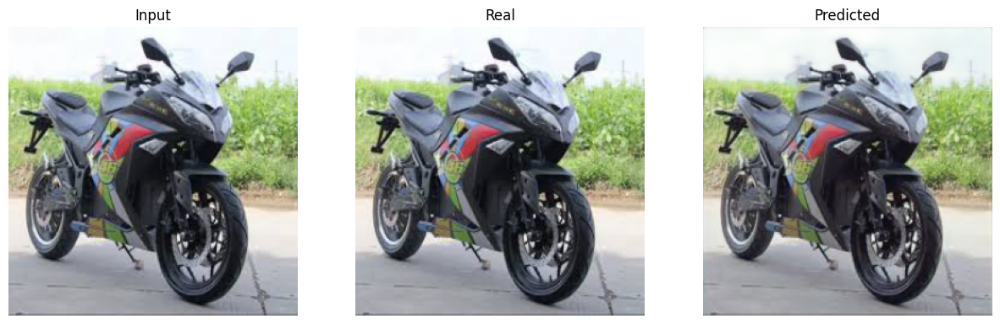

-----------------------------------------------------------
| End of epoch  13 | Time: 28.06s | Train psnr   29.887 | Train Loss    0.048 | Valid psnr   31.954 | Valid Loss    0.037 
-----------------------------------------------------------
| epoch  14 |    50/   86 batches | psnr   30.332
-----------------------------------------------------------
| End of epoch  14 | Time: 28.05s | Train psnr   30.559 | Train Loss    0.047 | Valid psnr   30.714 | Valid Loss    0.040 
-----------------------------------------------------------
| epoch  15 |    50/   86 batches | psnr   30.558


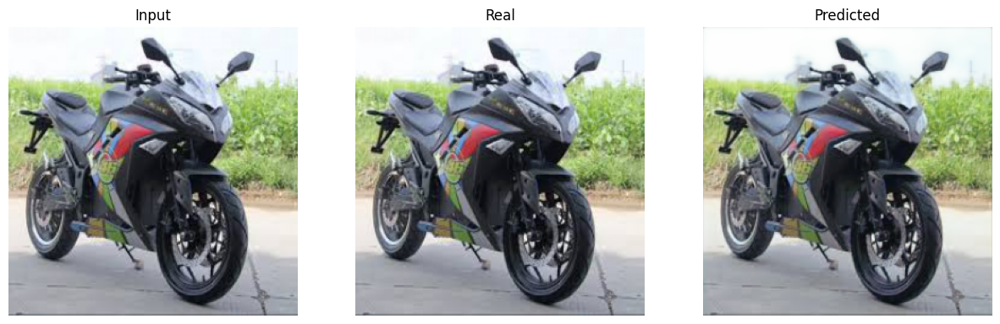

-----------------------------------------------------------
| End of epoch  15 | Time: 28.36s | Train psnr   30.884 | Train Loss    0.045 | Valid psnr   33.378 | Valid Loss    0.031 
-----------------------------------------------------------
| epoch  16 |    50/   86 batches | psnr   30.156
-----------------------------------------------------------
| End of epoch  16 | Time: 27.99s | Train psnr   30.962 | Train Loss    0.046 | Valid psnr   33.135 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch  17 |    50/   86 batches | psnr   30.626
-----------------------------------------------------------
| End of epoch  17 | Time: 27.35s | Train psnr   30.443 | Train Loss    0.046 | Valid psnr   32.063 | Valid Loss    0.031 
-----------------------------------------------------------
| epoch  18 |    50/   86 batches | psnr   30.830
-----------------------------------------------------------
| End of epoch  18 | Time: 27.82s | Train psnr   30.880 | Tra

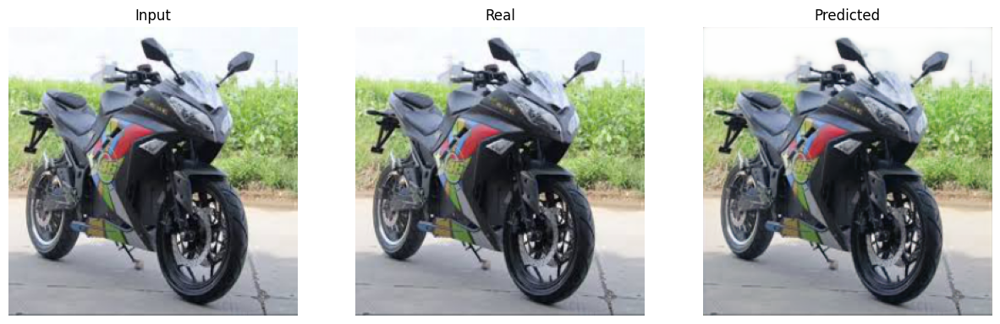

-----------------------------------------------------------
| End of epoch  21 | Time: 28.28s | Train psnr   31.636 | Train Loss    0.041 | Valid psnr   33.880 | Valid Loss    0.028 
-----------------------------------------------------------
| epoch  22 |    50/   86 batches | psnr   30.950


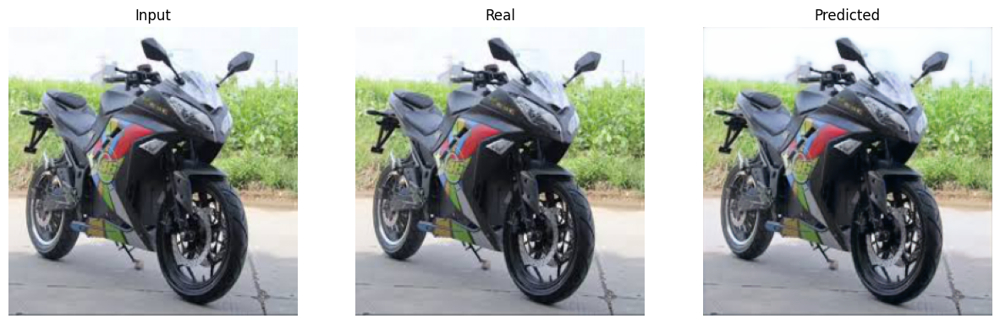

-----------------------------------------------------------
| End of epoch  22 | Time: 28.36s | Train psnr   32.143 | Train Loss    0.041 | Valid psnr   33.966 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  23 |    50/   86 batches | psnr   31.580
-----------------------------------------------------------
| End of epoch  23 | Time: 27.82s | Train psnr   31.256 | Train Loss    0.040 | Valid psnr   31.955 | Valid Loss    0.035 
-----------------------------------------------------------
| epoch  24 |    50/   86 batches | psnr   31.666
-----------------------------------------------------------
| End of epoch  24 | Time: 27.24s | Train psnr   31.635 | Train Loss    0.040 | Valid psnr   32.355 | Valid Loss    0.033 
-----------------------------------------------------------
| epoch  25 |    50/   86 batches | psnr   32.172
-----------------------------------------------------------
| End of epoch  25 | Time: 28.02s | Train psnr   31.775 | Tra

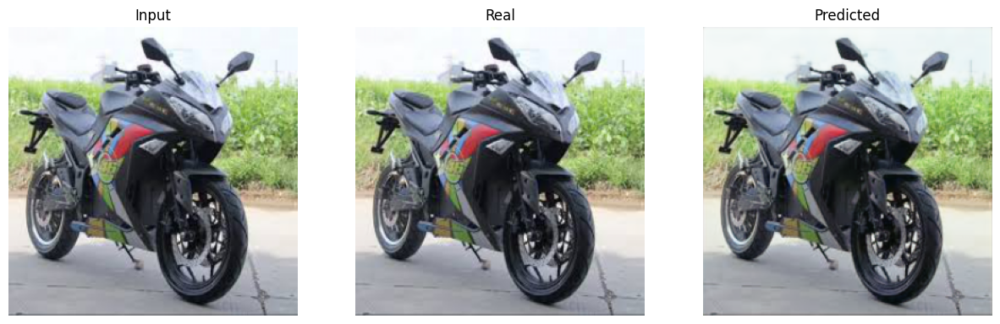

-----------------------------------------------------------
| End of epoch  26 | Time: 28.25s | Train psnr   32.494 | Train Loss    0.039 | Valid psnr   34.080 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  27 |    50/   86 batches | psnr   32.488
-----------------------------------------------------------
| End of epoch  27 | Time: 27.85s | Train psnr   31.349 | Train Loss    0.038 | Valid psnr   31.434 | Valid Loss    0.042 
-----------------------------------------------------------
| epoch  28 |    50/   86 batches | psnr   31.915


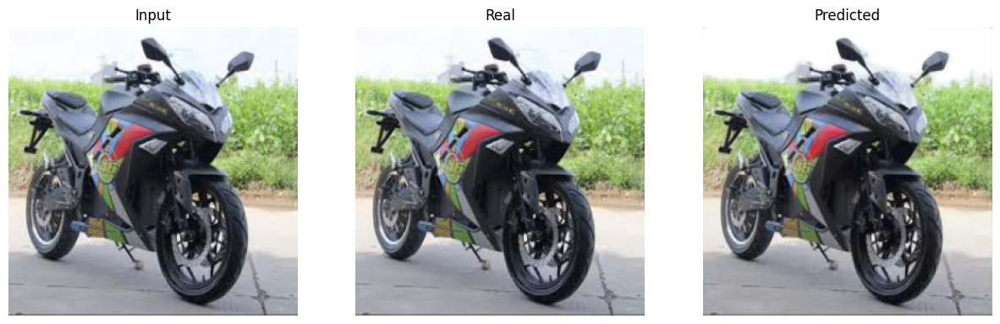

-----------------------------------------------------------
| End of epoch  28 | Time: 28.46s | Train psnr   31.948 | Train Loss    0.039 | Valid psnr   35.202 | Valid Loss    0.023 
-----------------------------------------------------------
| epoch  29 |    50/   86 batches | psnr   31.434
-----------------------------------------------------------
| End of epoch  29 | Time: 27.91s | Train psnr   31.742 | Train Loss    0.040 | Valid psnr   34.648 | Valid Loss    0.026 
-----------------------------------------------------------
| epoch  30 |    50/   86 batches | psnr   31.060
-----------------------------------------------------------
| End of epoch  30 | Time: 27.45s | Train psnr   31.631 | Train Loss    0.041 | Valid psnr   34.081 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  31 |    50/   86 batches | psnr   32.026
-----------------------------------------------------------
| End of epoch  31 | Time: 27.88s | Train psnr   32.108 | Tra

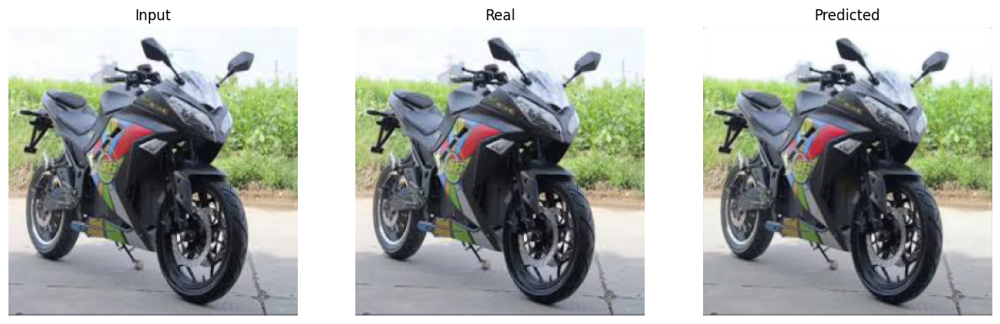

-----------------------------------------------------------
| End of epoch  35 | Time: 28.46s | Train psnr   32.834 | Train Loss    0.034 | Valid psnr   35.372 | Valid Loss    0.023 
-----------------------------------------------------------
| epoch  36 |    50/   86 batches | psnr   32.910
-----------------------------------------------------------
| End of epoch  36 | Time: 28.06s | Train psnr   31.928 | Train Loss    0.036 | Valid psnr   33.905 | Valid Loss    0.029 
-----------------------------------------------------------
| epoch  37 |    50/   86 batches | psnr   32.734
-----------------------------------------------------------
| End of epoch  37 | Time: 27.26s | Train psnr   32.597 | Train Loss    0.036 | Valid psnr   34.446 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  38 |    50/   86 batches | psnr   32.797
-----------------------------------------------------------
| End of epoch  38 | Time: 28.10s | Train psnr   32.857 | Tra

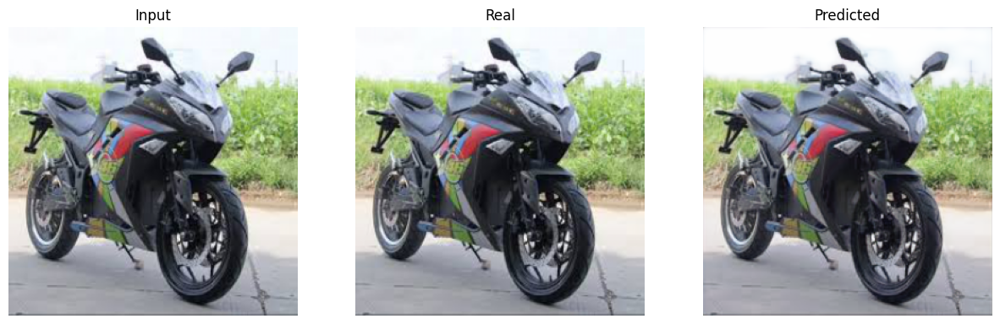

-----------------------------------------------------------
| End of epoch  39 | Time: 28.28s | Train psnr   33.297 | Train Loss    0.035 | Valid psnr   35.472 | Valid Loss    0.024 
-----------------------------------------------------------
| epoch  40 |    50/   86 batches | psnr   32.774
-----------------------------------------------------------
| End of epoch  40 | Time: 28.09s | Train psnr   32.348 | Train Loss    0.036 | Valid psnr   33.488 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch  41 |    50/   86 batches | psnr   32.314
-----------------------------------------------------------
| End of epoch  41 | Time: 27.75s | Train psnr   33.141 | Train Loss    0.036 | Valid psnr   34.288 | Valid Loss    0.028 
-----------------------------------------------------------
| epoch  42 |    50/   86 batches | psnr   32.573
-----------------------------------------------------------
| End of epoch  42 | Time: 27.75s | Train psnr   33.106 | Tra

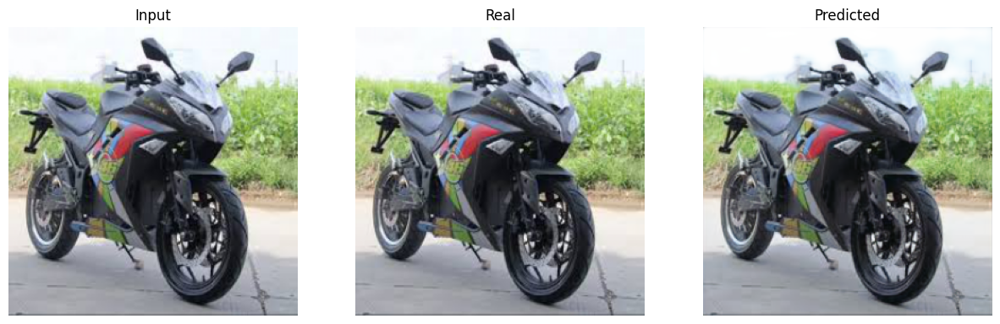

-----------------------------------------------------------
| End of epoch  43 | Time: 27.69s | Train psnr   32.928 | Train Loss    0.033 | Valid psnr   36.136 | Valid Loss    0.021 
-----------------------------------------------------------
| epoch  44 |    50/   86 batches | psnr   33.551


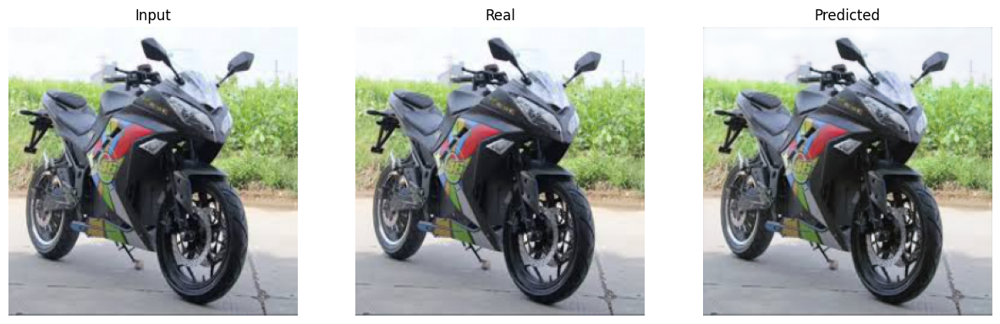

-----------------------------------------------------------
| End of epoch  44 | Time: 28.16s | Train psnr   33.510 | Train Loss    0.032 | Valid psnr   36.414 | Valid Loss    0.021 
-----------------------------------------------------------
| epoch  45 |    50/   86 batches | psnr   33.276
-----------------------------------------------------------
| End of epoch  45 | Time: 27.94s | Train psnr   33.074 | Train Loss    0.034 | Valid psnr   33.807 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  46 |    50/   86 batches | psnr   33.448
-----------------------------------------------------------
| End of epoch  46 | Time: 27.90s | Train psnr   33.097 | Train Loss    0.033 | Valid psnr   36.207 | Valid Loss    0.021 
-----------------------------------------------------------
| epoch  47 |    50/   86 batches | psnr   33.606
-----------------------------------------------------------
| End of epoch  47 | Time: 28.03s | Train psnr   34.012 | Tra

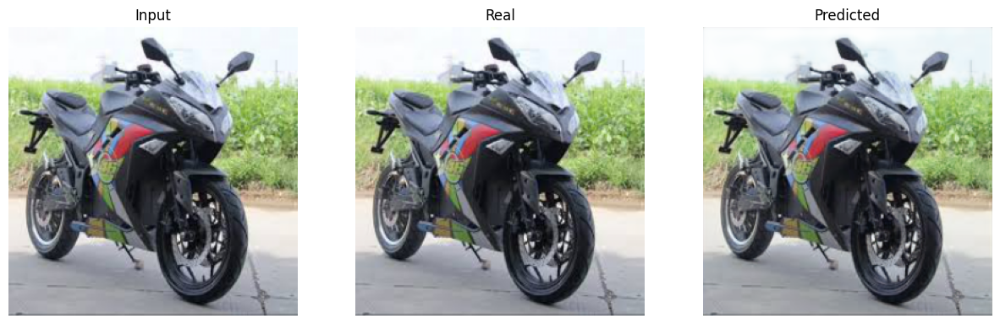

-----------------------------------------------------------
| End of epoch  66 | Time: 28.21s | Train psnr   34.498 | Train Loss    0.029 | Valid psnr   37.113 | Valid Loss    0.019 
-----------------------------------------------------------
| epoch  67 |    50/   86 batches | psnr   34.047
-----------------------------------------------------------
| End of epoch  67 | Time: 27.98s | Train psnr   34.330 | Train Loss    0.030 | Valid psnr   36.843 | Valid Loss    0.019 
-----------------------------------------------------------
| epoch  68 |    50/   86 batches | psnr   34.446
-----------------------------------------------------------
| End of epoch  68 | Time: 27.88s | Train psnr   34.624 | Train Loss    0.029 | Valid psnr   35.660 | Valid Loss    0.024 
-----------------------------------------------------------
| epoch  69 |    50/   86 batches | psnr   34.494
-----------------------------------------------------------
| End of epoch  69 | Time: 27.39s | Train psnr   34.633 | Tra

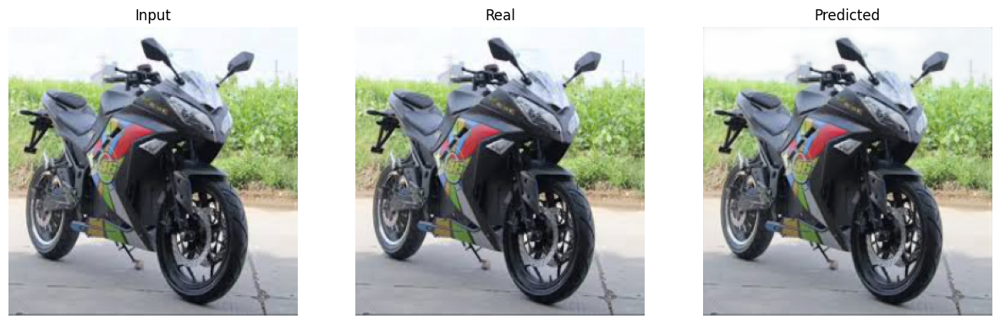

-----------------------------------------------------------
| End of epoch  70 | Time: 28.38s | Train psnr   34.067 | Train Loss    0.031 | Valid psnr   37.695 | Valid Loss    0.018 
-----------------------------------------------------------
| epoch  71 |    50/   86 batches | psnr   34.508
-----------------------------------------------------------
| End of epoch  71 | Time: 27.75s | Train psnr   34.859 | Train Loss    0.028 | Valid psnr   35.770 | Valid Loss    0.024 
-----------------------------------------------------------
| epoch  72 |    50/   86 batches | psnr   34.507
-----------------------------------------------------------
| End of epoch  72 | Time: 28.05s | Train psnr   34.431 | Train Loss    0.029 | Valid psnr   35.729 | Valid Loss    0.021 
-----------------------------------------------------------
| epoch  73 |    50/   86 batches | psnr   34.422
-----------------------------------------------------------
| End of epoch  73 | Time: 27.80s | Train psnr   34.496 | Tra

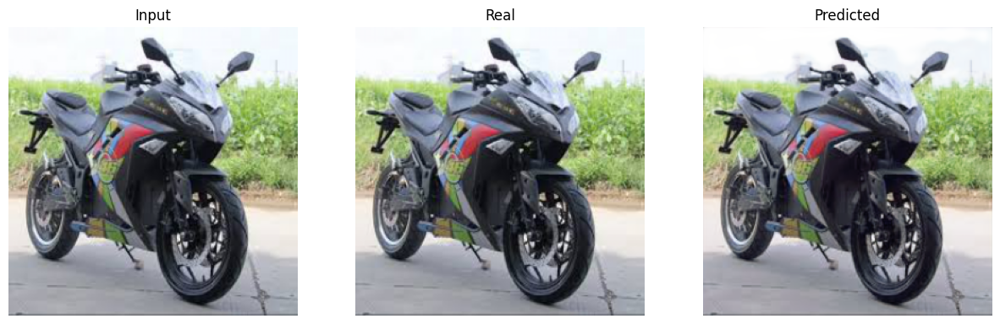

-----------------------------------------------------------
| End of epoch 100 | Time: 28.52s | Train psnr   35.540 | Train Loss    0.026 | Valid psnr   38.120 | Valid Loss    0.017 
-----------------------------------------------------------


In [ ]:
import torch.optim as optim

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IP_unet_model = II_Unet().to(device)
IP_unet_model.to(device)

criterion = nn.L1Loss()

optimizer = optim.Adam(IP_unet_model.parameters(), lr=1e-4, betas=[0.5,0.999])

save_model = './UNET'
os.makedirs(save_model, exist_ok = True)

EPOCHS = 100
IP_unet_model, metrics = train(
    IP_unet_model, 'IP_unet_model_phase1', save_model, optimizer, criterion, train_loader_phase1, test_loader_phase1, EPOCHS, device
)

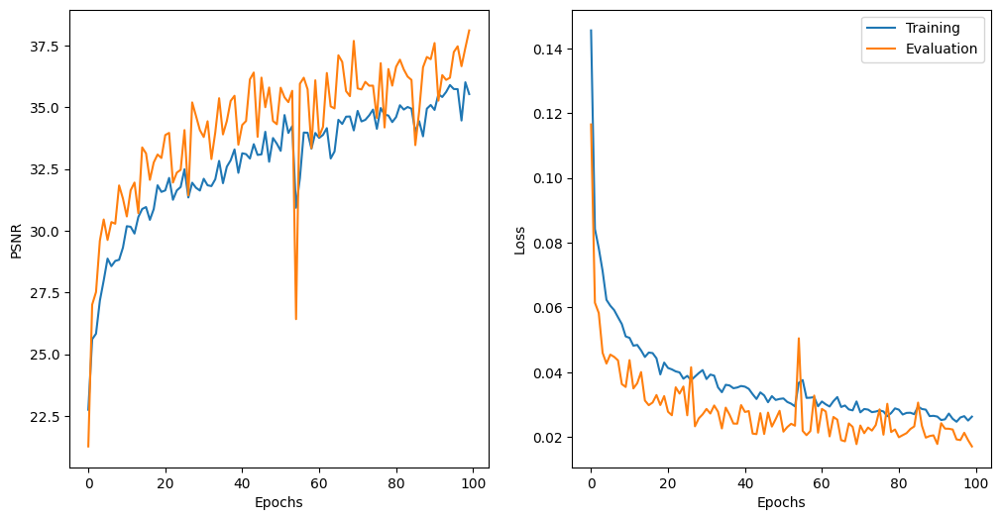

In [ ]:
plot_result(
    EPOCHS,
    metrics["train_psnr"],
    metrics["valid_psnr"],
    metrics["train_loss"],
    metrics["valid_loss"]
)

In [ ]:
test_psnr, test_loss = evaluate_epoch(IP_unet_model, criterion, test_loader_phase1, device)
test_psnr, test_loss

(tensor(38.1198, device='cuda:0'), 0.01711937158622525)

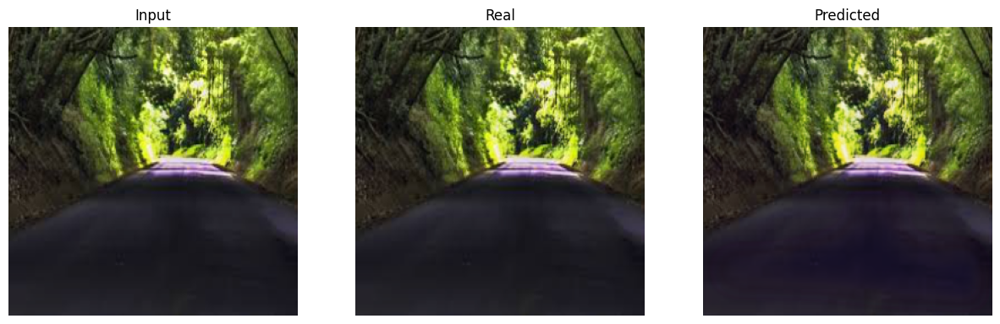

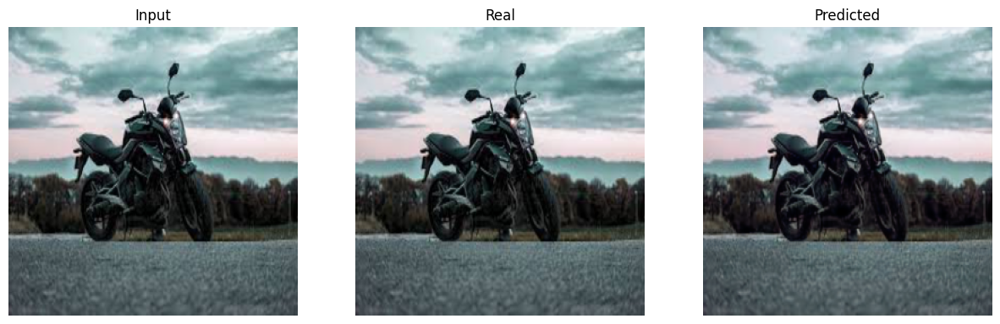

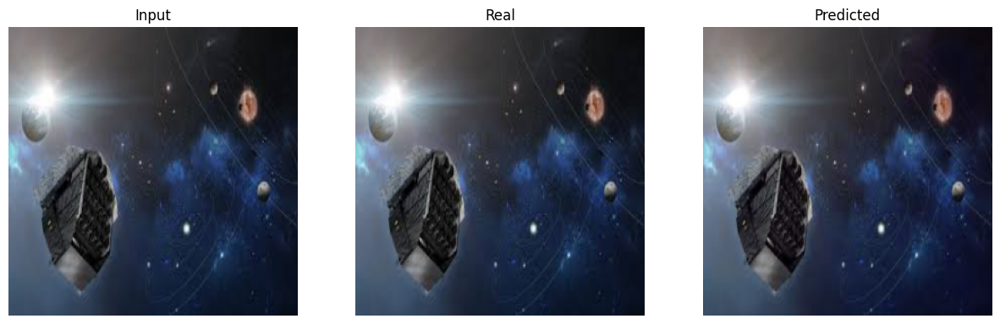

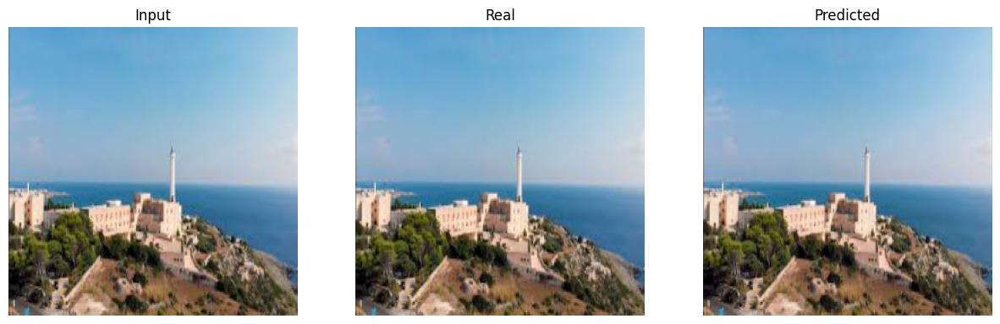

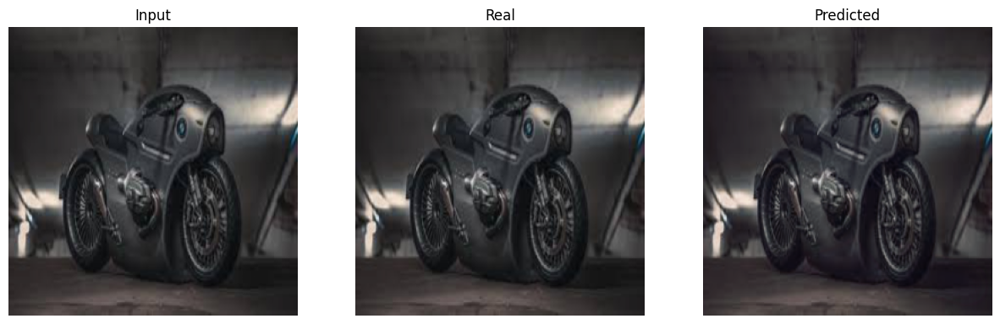

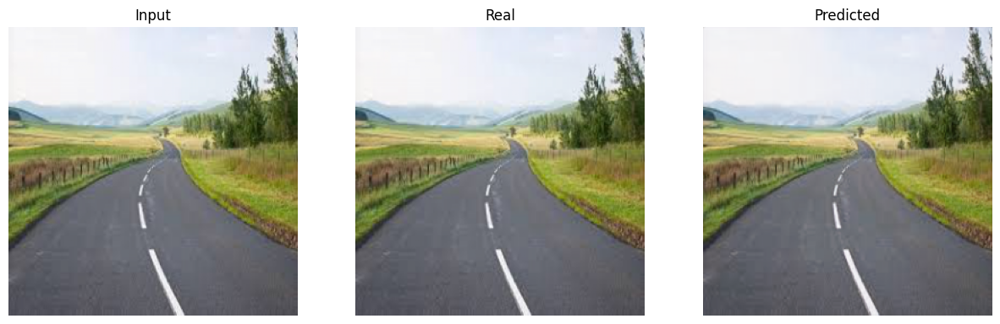

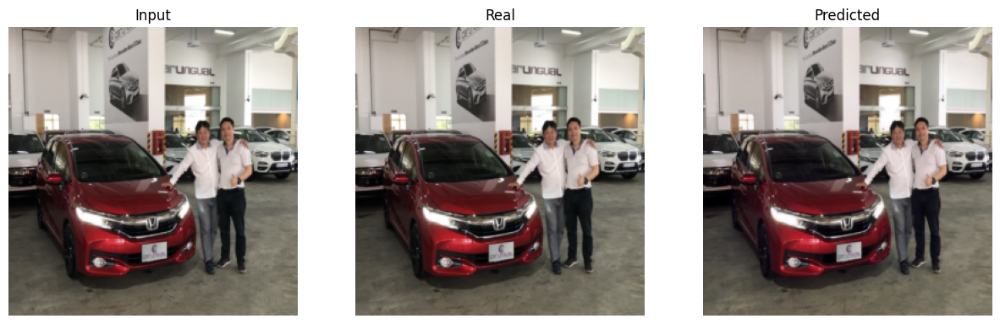

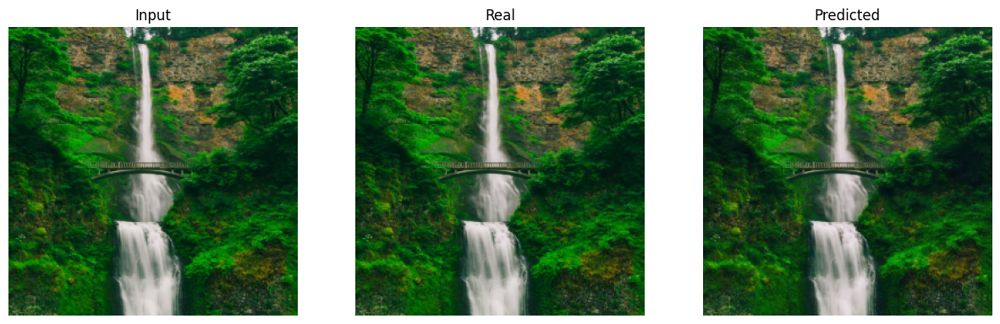

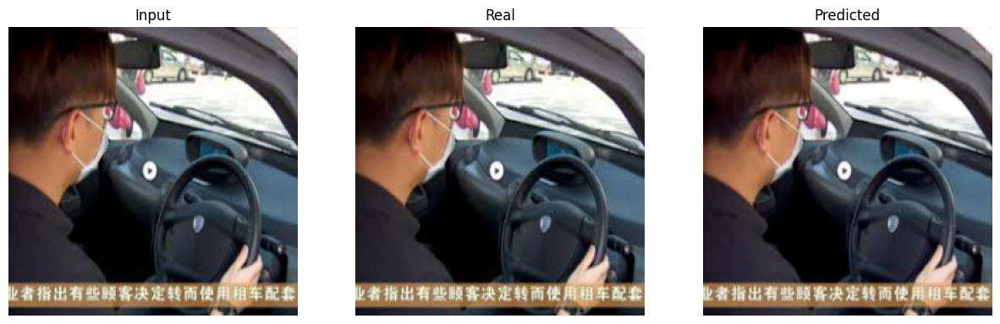

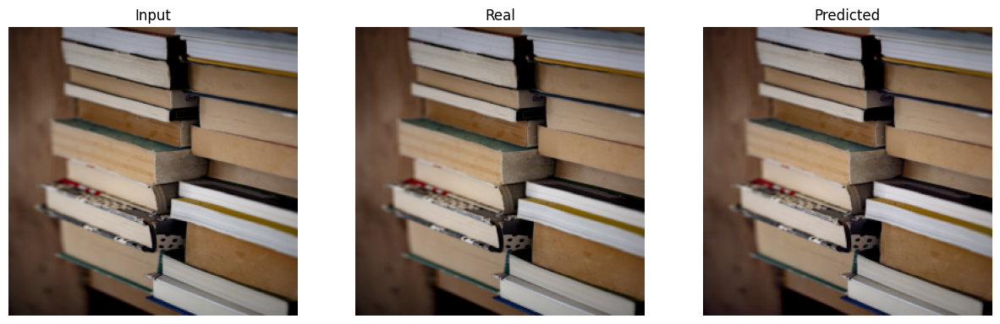

In [ ]:
predict_and_display(IP_unet_model, train_loader_phase1, device)

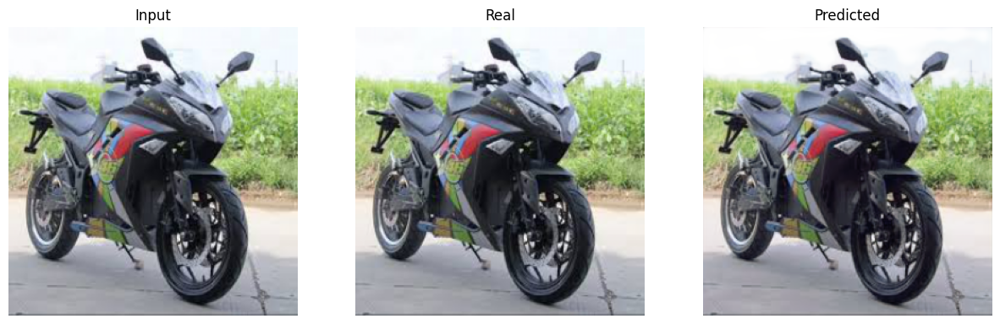

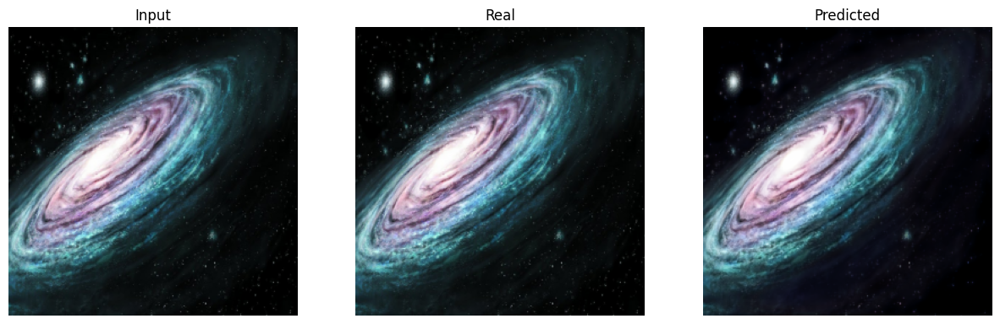

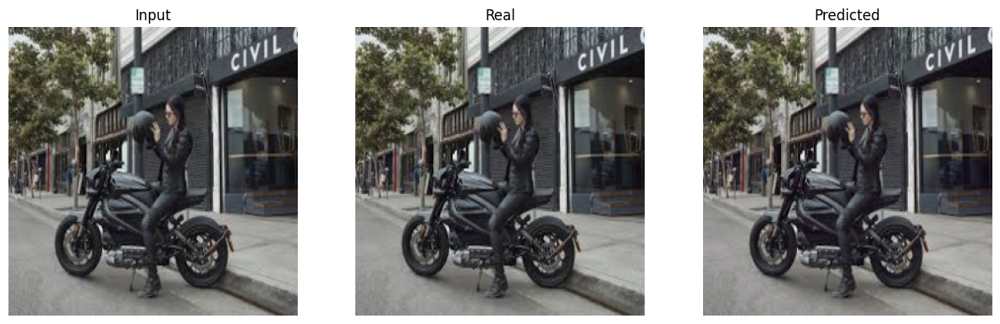

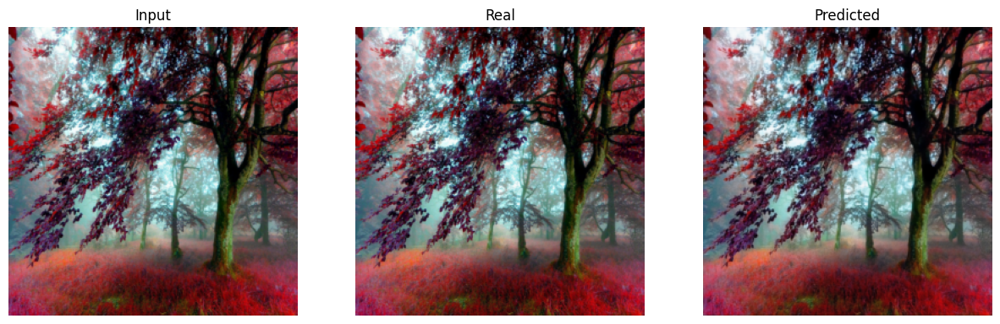

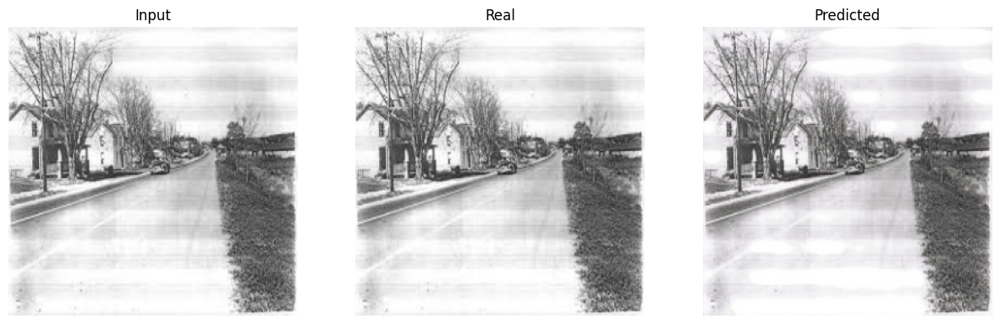

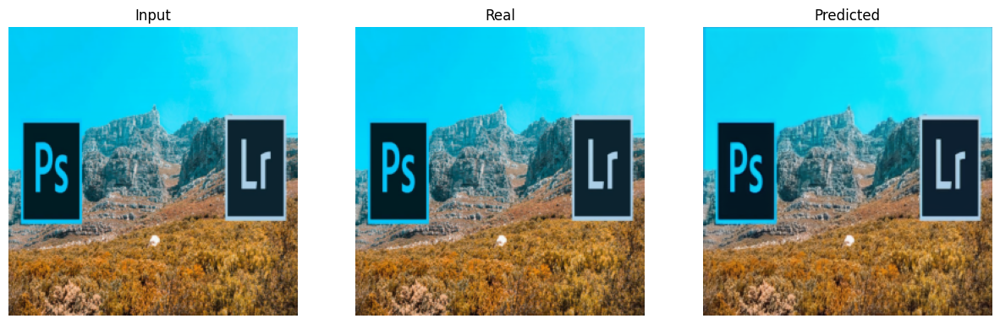

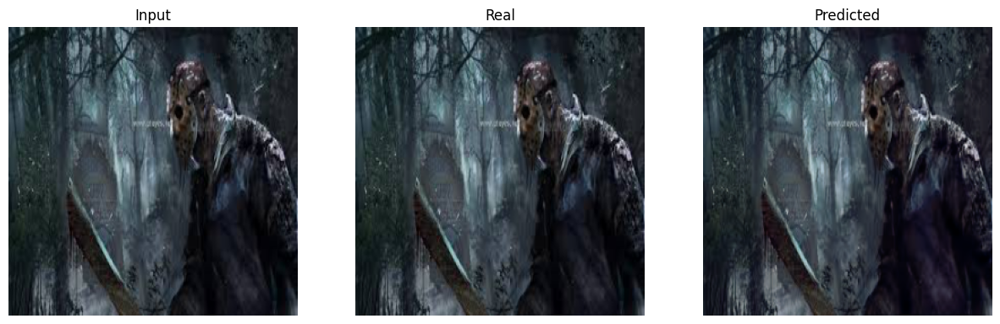

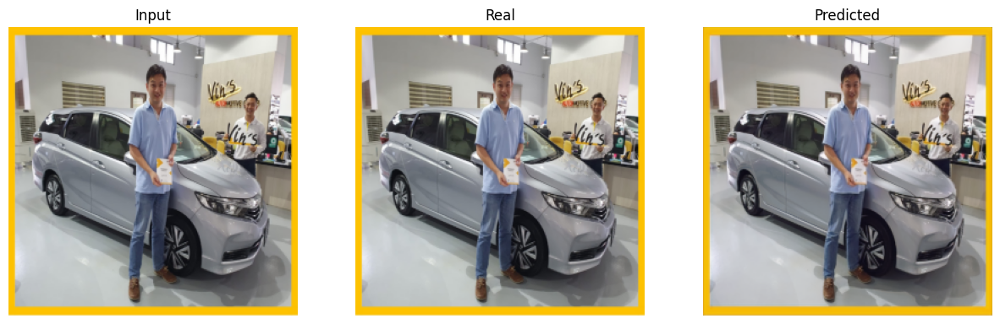

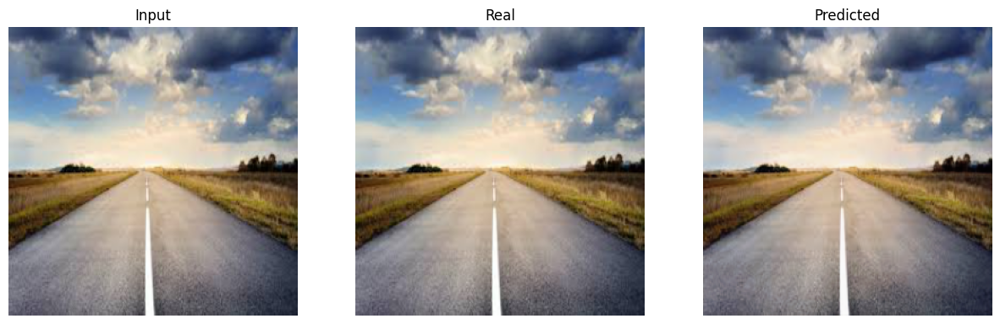

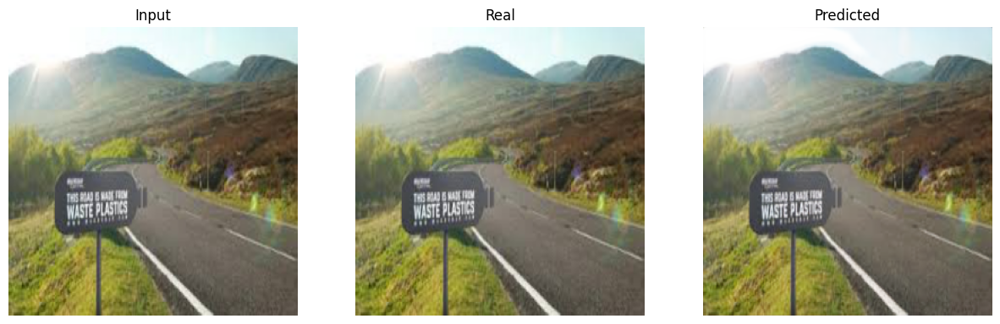

In [ ]:
predict_and_display(IP_unet_model, test_loader_phase1, device)

| epoch   1 |    50/   86 batches | psnr   19.229


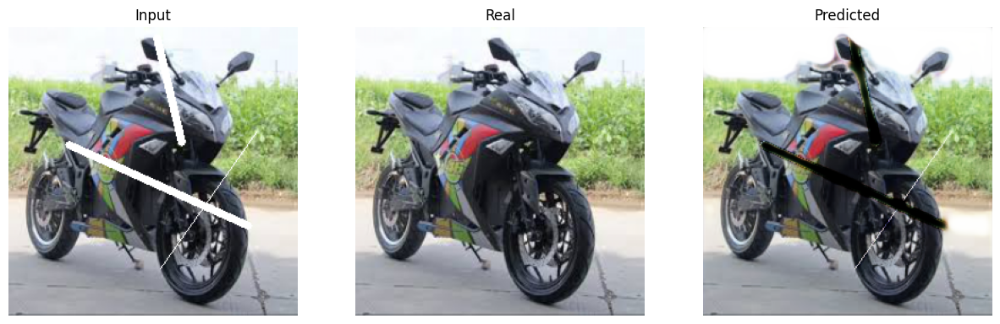

-----------------------------------------------------------
| End of epoch   1 | Time: 28.22s | Train psnr   23.133 | Train Loss    0.065 | Valid psnr   22.040 | Valid Loss    0.055 
-----------------------------------------------------------
| epoch   2 |    50/   86 batches | psnr   24.534


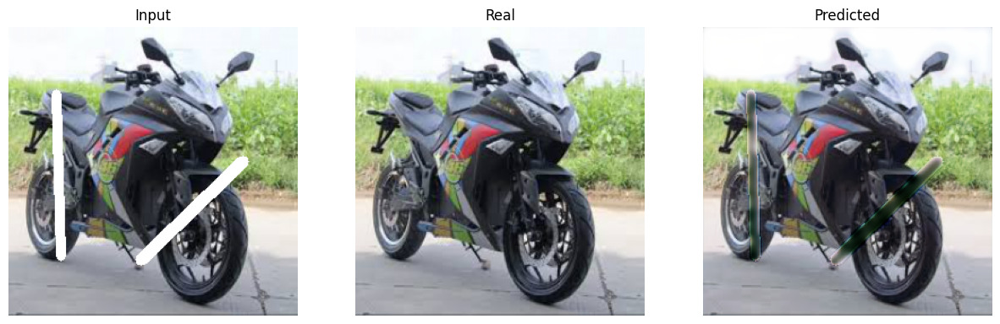

-----------------------------------------------------------
| End of epoch   2 | Time: 28.32s | Train psnr   24.689 | Train Loss    0.048 | Valid psnr   26.407 | Valid Loss    0.040 
-----------------------------------------------------------
| epoch   3 |    50/   86 batches | psnr   25.851
-----------------------------------------------------------
| End of epoch   3 | Time: 28.00s | Train psnr   26.281 | Train Loss    0.043 | Valid psnr   25.960 | Valid Loss    0.037 
-----------------------------------------------------------
| epoch   4 |    50/   86 batches | psnr   25.649
-----------------------------------------------------------
| End of epoch   4 | Time: 28.20s | Train psnr   25.382 | Train Loss    0.046 | Valid psnr   25.575 | Valid Loss    0.038 
-----------------------------------------------------------
| epoch   5 |    50/   86 batches | psnr   26.137


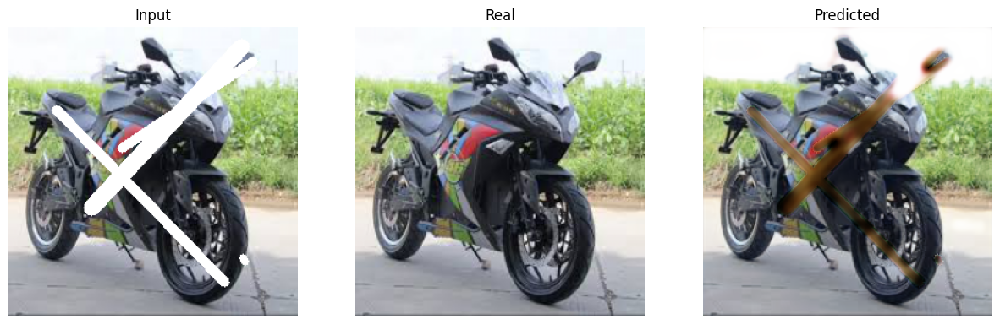

-----------------------------------------------------------
| End of epoch   5 | Time: 28.45s | Train psnr   26.520 | Train Loss    0.043 | Valid psnr   27.301 | Valid Loss    0.036 
-----------------------------------------------------------
| epoch   6 |    50/   86 batches | psnr   27.204
-----------------------------------------------------------
| End of epoch   6 | Time: 28.13s | Train psnr   27.049 | Train Loss    0.040 | Valid psnr   21.661 | Valid Loss    0.053 
-----------------------------------------------------------
| epoch   7 |    50/   86 batches | psnr   27.525
-----------------------------------------------------------
| End of epoch   7 | Time: 28.14s | Train psnr   27.605 | Train Loss    0.038 | Valid psnr   26.329 | Valid Loss    0.033 
-----------------------------------------------------------
| epoch   8 |    50/   86 batches | psnr   28.168


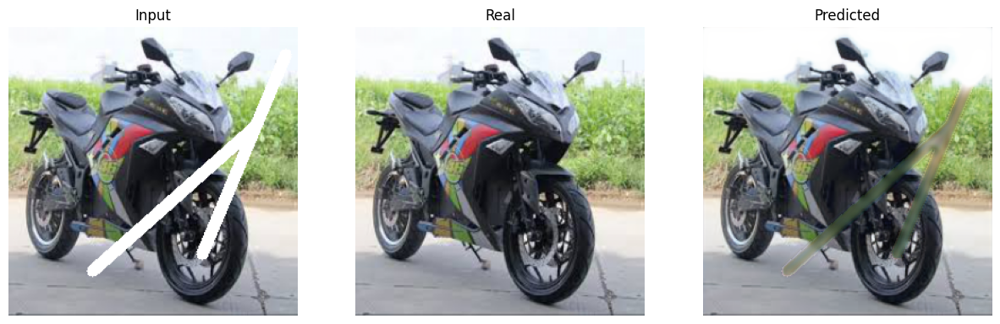

-----------------------------------------------------------
| End of epoch   8 | Time: 27.98s | Train psnr   27.934 | Train Loss    0.037 | Valid psnr   29.216 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch   9 |    50/   86 batches | psnr   28.023
-----------------------------------------------------------
| End of epoch   9 | Time: 28.16s | Train psnr   27.922 | Train Loss    0.036 | Valid psnr   27.015 | Valid Loss    0.033 
-----------------------------------------------------------
| epoch  10 |    50/   86 batches | psnr   28.297
-----------------------------------------------------------
| End of epoch  10 | Time: 28.22s | Train psnr   27.644 | Train Loss    0.037 | Valid psnr   28.029 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch  11 |    50/   86 batches | psnr   28.294


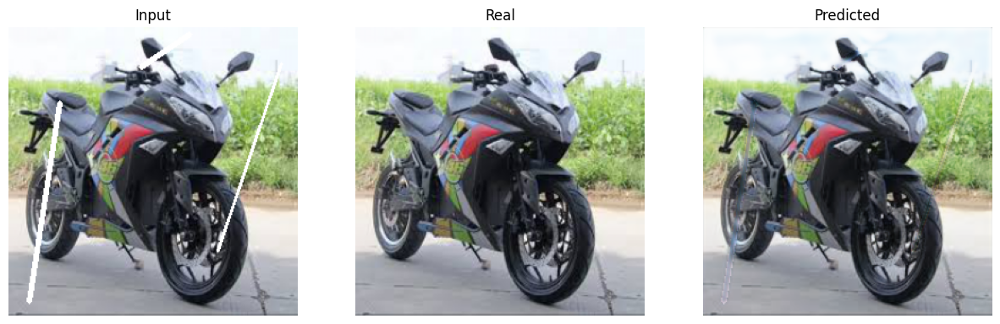

-----------------------------------------------------------
| End of epoch  11 | Time: 28.41s | Train psnr   28.295 | Train Loss    0.035 | Valid psnr   30.013 | Valid Loss    0.026 
-----------------------------------------------------------
| epoch  12 |    50/   86 batches | psnr   28.614
-----------------------------------------------------------
| End of epoch  12 | Time: 28.35s | Train psnr   27.668 | Train Loss    0.036 | Valid psnr   29.153 | Valid Loss    0.029 
-----------------------------------------------------------
| epoch  13 |    50/   86 batches | psnr   28.139
-----------------------------------------------------------
| End of epoch  13 | Time: 28.02s | Train psnr   28.454 | Train Loss    0.037 | Valid psnr   29.400 | Valid Loss    0.028 
-----------------------------------------------------------
| epoch  14 |    50/   86 batches | psnr   28.355
-----------------------------------------------------------
| End of epoch  14 | Time: 27.71s | Train psnr   28.623 | Tra

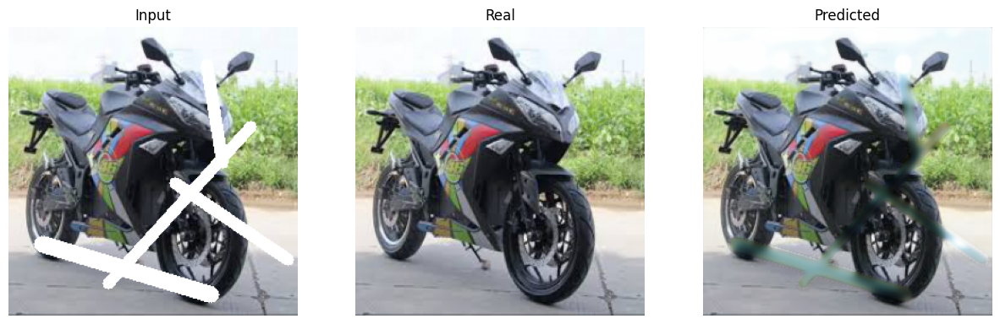

-----------------------------------------------------------
| End of epoch  21 | Time: 28.07s | Train psnr   29.110 | Train Loss    0.032 | Valid psnr   30.616 | Valid Loss    0.025 
-----------------------------------------------------------
| epoch  22 |    50/   86 batches | psnr   29.370
-----------------------------------------------------------
| End of epoch  22 | Time: 28.36s | Train psnr   29.220 | Train Loss    0.033 | Valid psnr   29.922 | Valid Loss    0.027 
-----------------------------------------------------------
| epoch  23 |    50/   86 batches | psnr   29.460
-----------------------------------------------------------
| End of epoch  23 | Time: 28.08s | Train psnr   29.797 | Train Loss    0.031 | Valid psnr   29.538 | Valid Loss    0.029 
-----------------------------------------------------------
| epoch  24 |    50/   86 batches | psnr   29.359
-----------------------------------------------------------
| End of epoch  24 | Time: 28.11s | Train psnr   29.721 | Tra

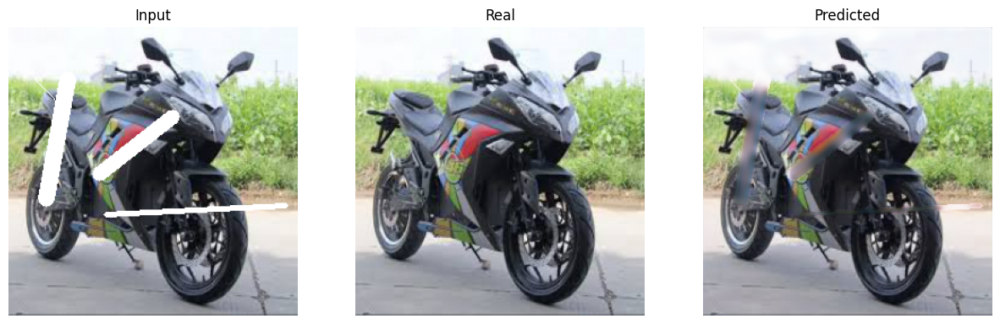

-----------------------------------------------------------
| End of epoch  28 | Time: 28.63s | Train psnr   29.629 | Train Loss    0.032 | Valid psnr   31.207 | Valid Loss    0.022 
-----------------------------------------------------------
| epoch  29 |    50/   86 batches | psnr   29.664
-----------------------------------------------------------
| End of epoch  29 | Time: 27.98s | Train psnr   29.541 | Train Loss    0.031 | Valid psnr   21.859 | Valid Loss    0.050 
-----------------------------------------------------------
| epoch  30 |    50/   86 batches | psnr   29.805
-----------------------------------------------------------
| End of epoch  30 | Time: 28.16s | Train psnr   29.753 | Train Loss    0.030 | Valid psnr   28.030 | Valid Loss    0.030 
-----------------------------------------------------------
| epoch  31 |    50/   86 batches | psnr   29.898
-----------------------------------------------------------
| End of epoch  31 | Time: 28.03s | Train psnr   29.541 | Tra

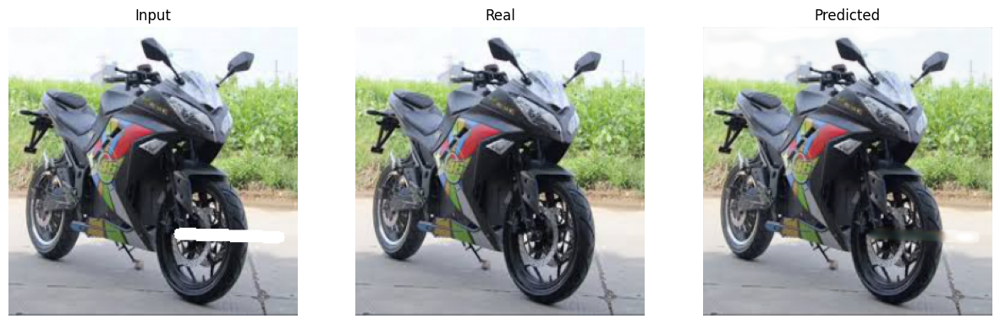

-----------------------------------------------------------
| End of epoch  52 | Time: 28.43s | Train psnr   29.974 | Train Loss    0.029 | Valid psnr   31.562 | Valid Loss    0.022 
-----------------------------------------------------------
| epoch  53 |    50/   86 batches | psnr   30.401
-----------------------------------------------------------
| End of epoch  53 | Time: 27.65s | Train psnr   30.383 | Train Loss    0.028 | Valid psnr   31.396 | Valid Loss    0.022 
-----------------------------------------------------------
| epoch  54 |    50/   86 batches | psnr   30.421
-----------------------------------------------------------
| End of epoch  54 | Time: 27.96s | Train psnr   30.407 | Train Loss    0.029 | Valid psnr   28.450 | Valid Loss    0.031 
-----------------------------------------------------------
| epoch  55 |    50/   86 batches | psnr   30.745
-----------------------------------------------------------
| End of epoch  55 | Time: 27.94s | Train psnr   30.578 | Tra

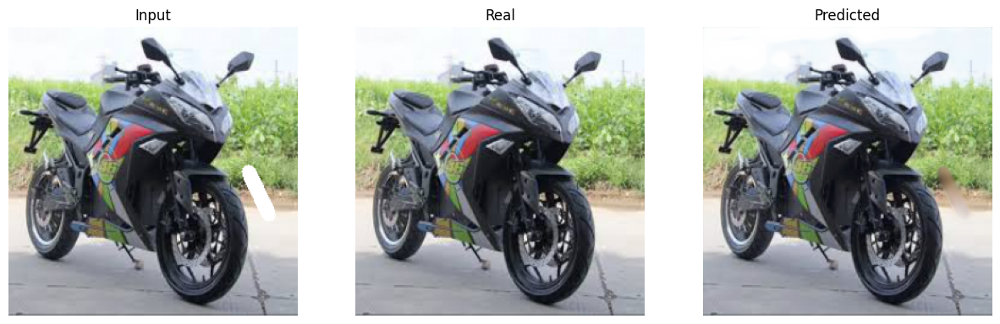

-----------------------------------------------------------
| End of epoch  88 | Time: 28.62s | Train psnr   30.601 | Train Loss    0.026 | Valid psnr   31.654 | Valid Loss    0.023 
-----------------------------------------------------------
| epoch  89 |    50/   86 batches | psnr   30.586
-----------------------------------------------------------
| End of epoch  89 | Time: 28.17s | Train psnr   30.877 | Train Loss    0.027 | Valid psnr   29.773 | Valid Loss    0.025 
-----------------------------------------------------------
| epoch  90 |    50/   86 batches | psnr   30.857
-----------------------------------------------------------
| End of epoch  90 | Time: 28.02s | Train psnr   30.789 | Train Loss    0.026 | Valid psnr   31.564 | Valid Loss    0.022 
-----------------------------------------------------------
| epoch  91 |    50/   86 batches | psnr   30.665
-----------------------------------------------------------
| End of epoch  91 | Time: 28.27s | Train psnr   30.449 | Tra

In [ ]:
criterion = nn.L1Loss()

optimizer = optim.Adam(IP_unet_model.parameters(), lr=1e-4, betas=[0.5,0.999])

EPOCHS = 100
IP_unet_model, metrics = train(
    IP_unet_model, 'IP_unet_model_phase2', save_model, optimizer, criterion, train_loader, test_loader, EPOCHS, device
)

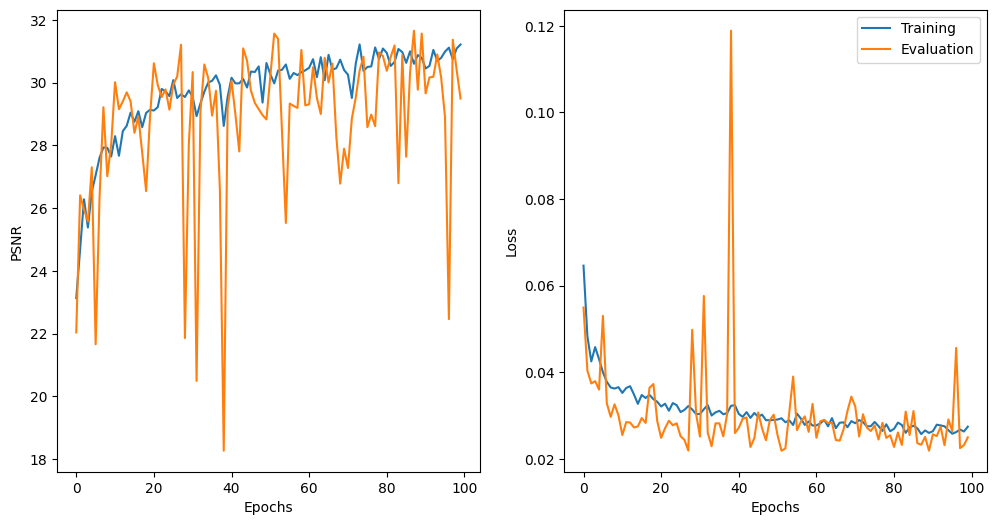

In [ ]:
plot_result(
    EPOCHS,
    metrics["train_psnr"],
    metrics["valid_psnr"],
    metrics["train_loss"],
    metrics["valid_loss"]
)

In [ ]:
test_psnr, test_loss = evaluate_epoch(IP_unet_model, criterion, test_loader, device)
test_psnr, test_loss

(tensor(31.6632, device='cuda:0'), 0.023582302203232593)

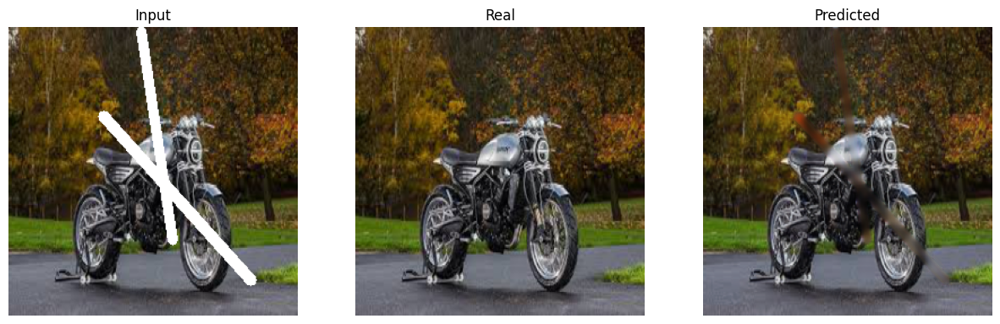

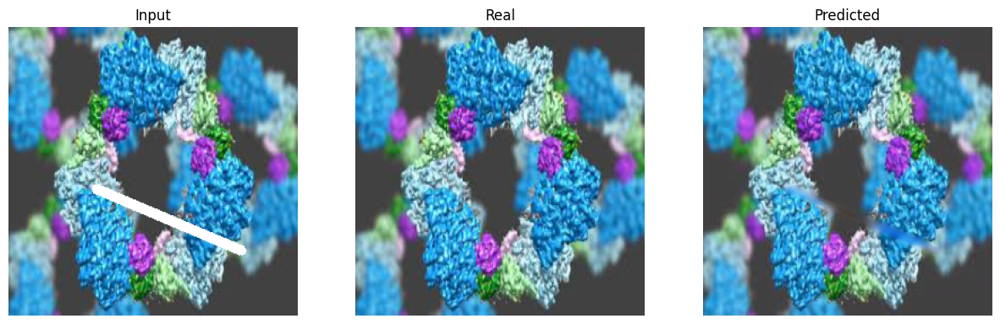

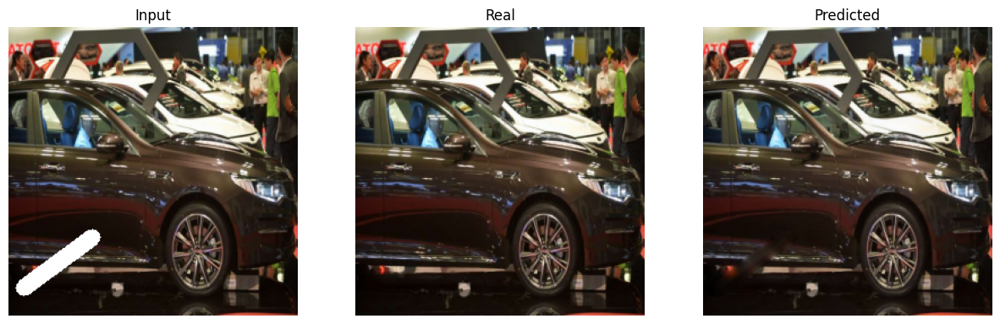

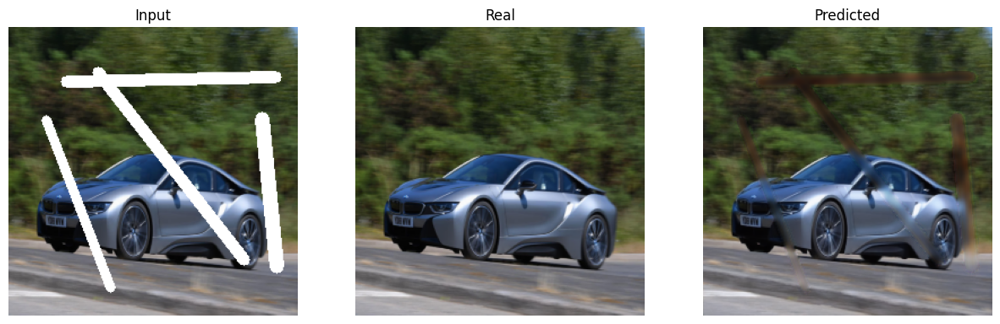

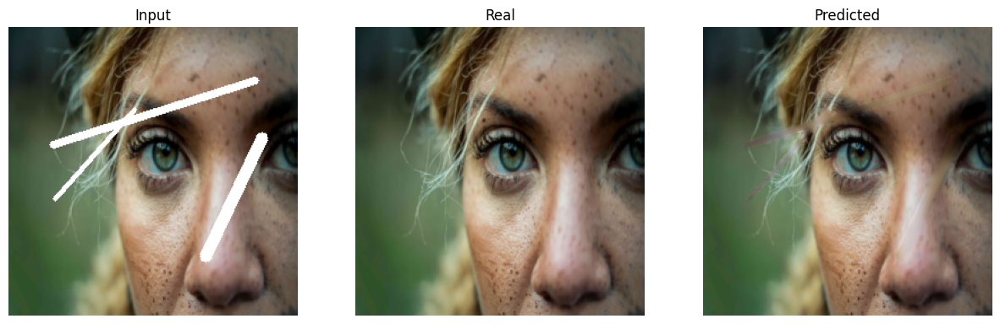

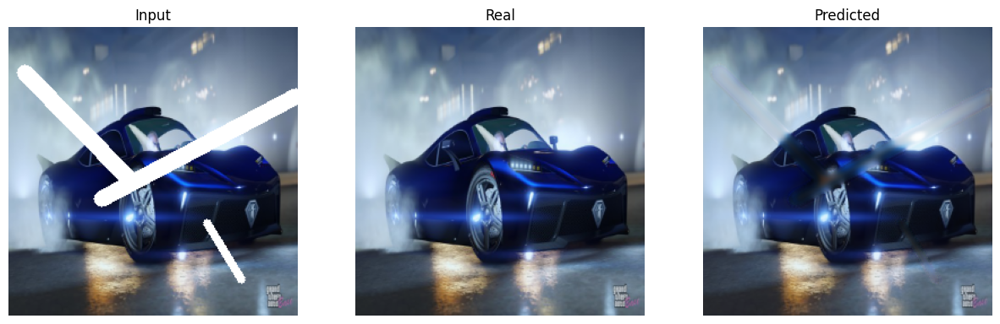

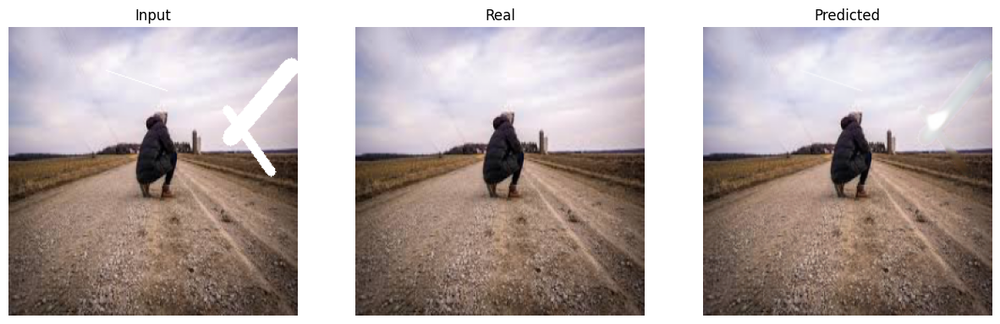

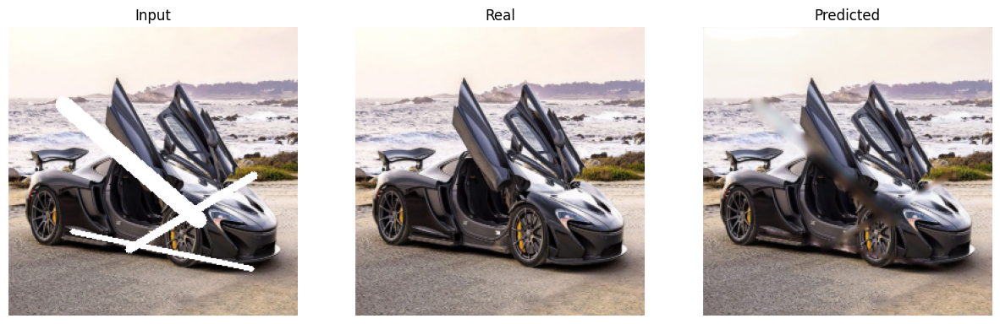

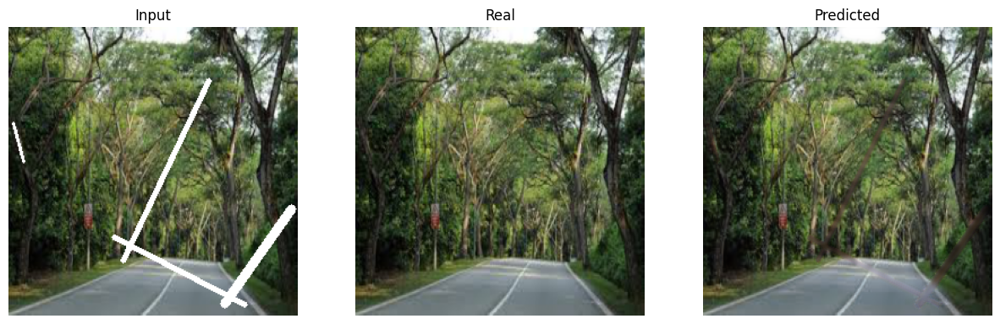

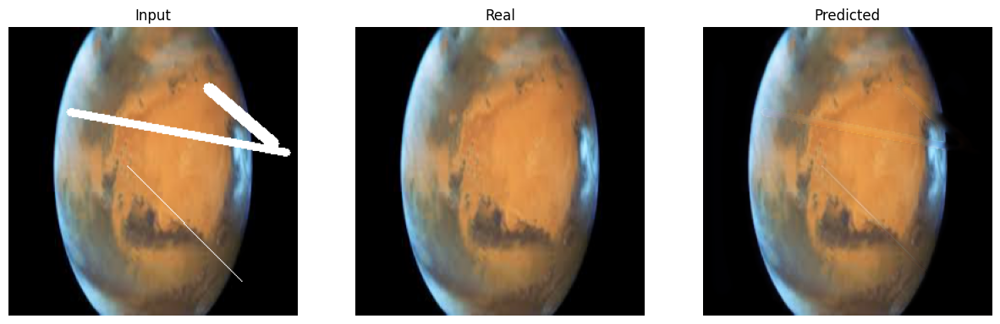

In [ ]:
predict_and_display(IP_unet_model, train_loader, device)

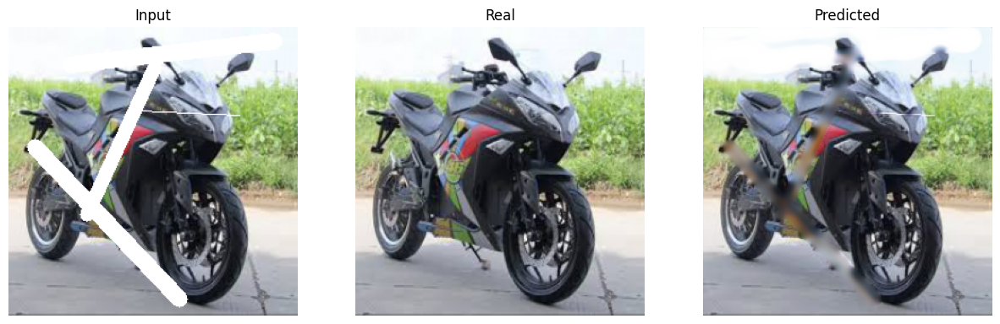

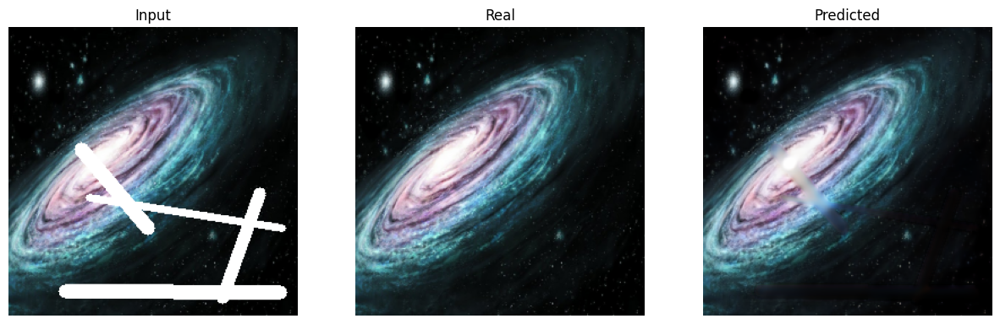

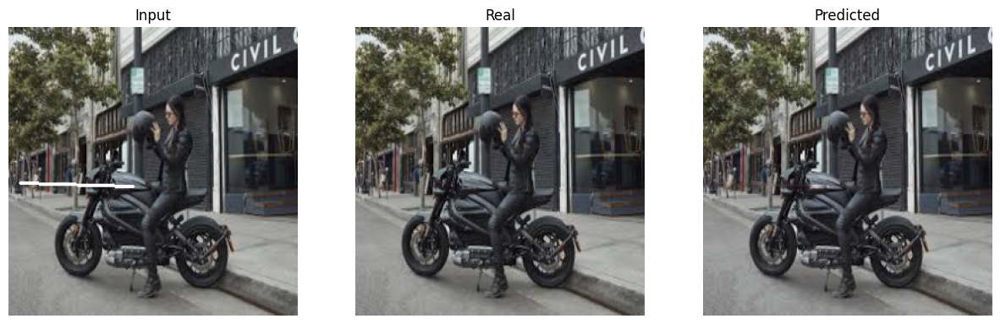

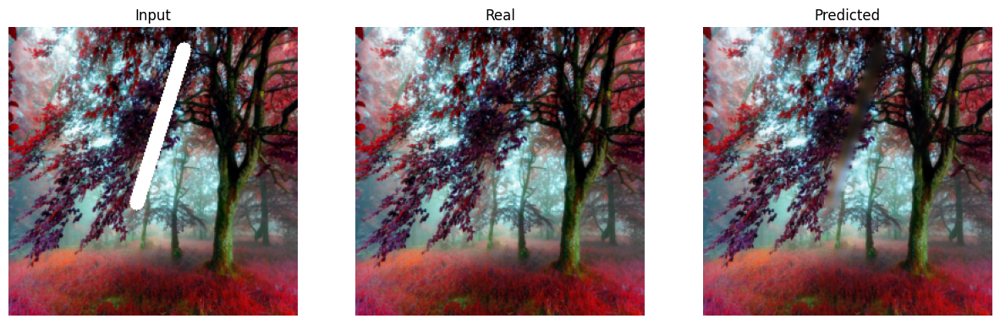

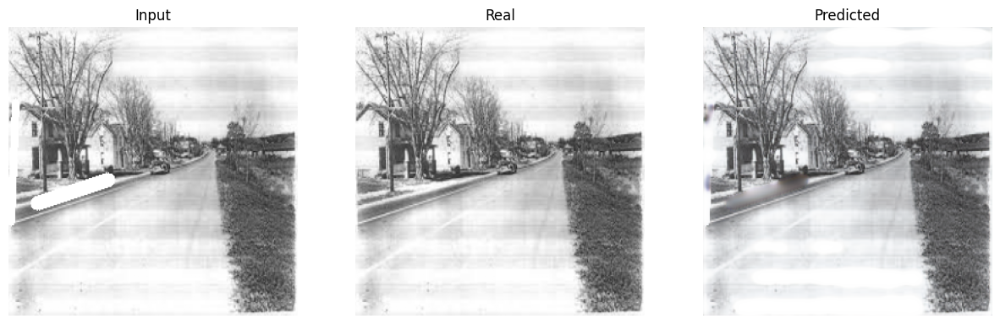

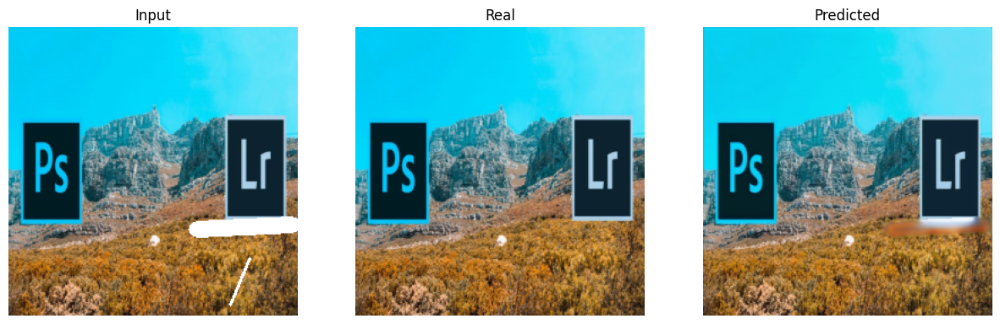

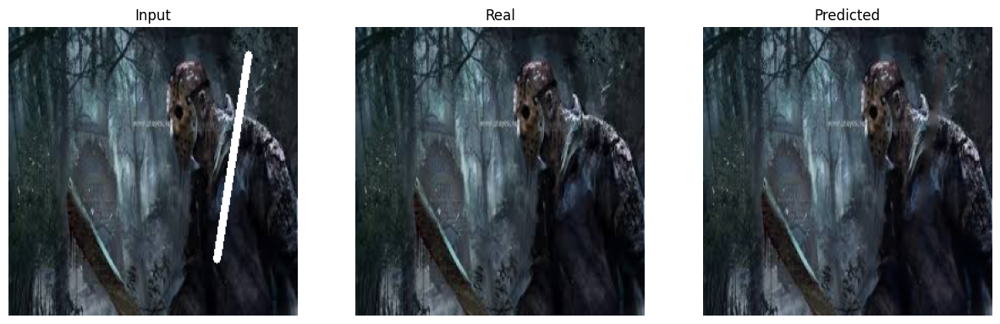

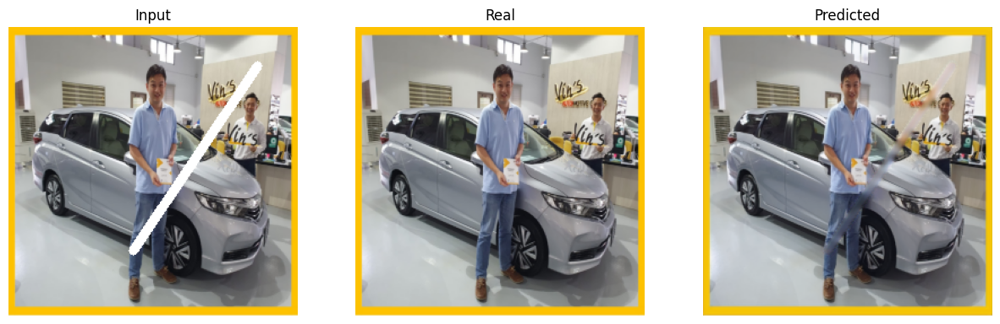

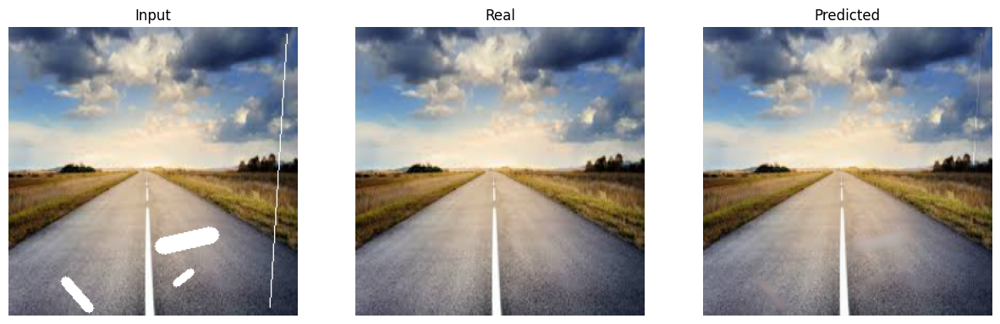

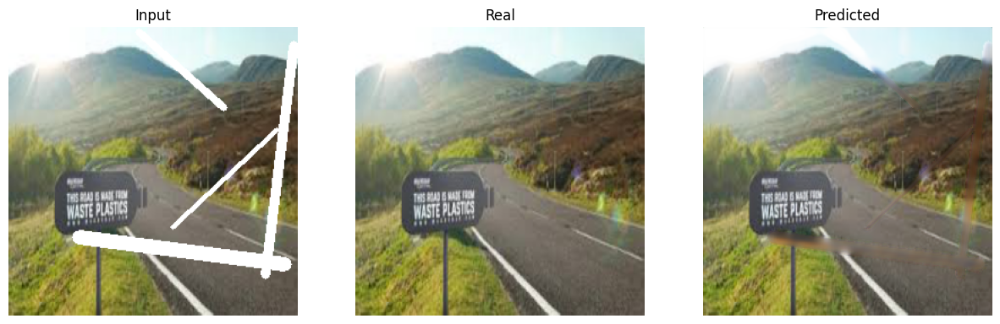

In [ ]:
predict_and_display(IP_unet_model, test_loader, device)